In [1]:
import pandas as pd
from pandas.errors import PerformanceWarning
import warnings
import sys
import os

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

warnings.simplefilter('ignore', category=PerformanceWarning)
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
print(sys.path)

['/Users/pavelholman/FIT/bp', '/Users/pavelholman/Applications/PyCharm Professional Edition.app/Contents/plugins/python-ce/helpers/pydev', '/Users/pavelholman/Applications/PyCharm Professional Edition.app/Contents/plugins/python-ce/helpers/jupyter_debug', '/Library/Frameworks/Python.framework/Versions/3.12/lib/python312.zip', '/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12', '/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/lib-dynload', '', '/Users/pavelholman/FIT/bp/.venv/lib/python3.12/site-packages', '/Users/pavelholman/FIT/bp']


In [2]:
from src.features.load_intra_day_dataset import load_intra_day_dataset

start = pd.Timestamp("2024-07-01")
end = pd.Timestamp("2025-04-01")
val_cutoff = pd.Timestamp("2025-01-01")
select_cutoff = pd.Timestamp("2025-02-01")
test_cutoff = pd.Timestamp("2025-03-01")

df = load_intra_day_dataset(start, end)

2025-05-06 16:41:09,803 - INFO - Loading intraday data
2025-05-06 16:41:09,804 - INFO - Loading data from /Users/pavelholman/FIT/bp/data/interim/data.csv


In [3]:
from src.models.metrics import get_eval_metrics

eval_metrics = get_eval_metrics()

In [4]:
from src.models.data_split import tabular_split, time_series_split, ID_KNOWN, ID_TARGET
from src.models.train_intra_day_time_series import train_intra_day_time_series
from src.models.train_intra_day_tabular import train_intra_day_tabular
from src.models.evaluation import evaluate_timeseries_model, evaluate_tabular_model

tab_df = df[[col for col in df.columns if any(col.startswith(prefix) for prefix in ID_KNOWN)] + [ID_TARGET]]
tab_train, tab_val, tab_select, tab_test = tabular_split(tab_df, val_cutoff, select_cutoff, test_cutoff)
ts_train, ts_val, ts_select, ts_test = time_series_split(df, val_cutoff, select_cutoff, test_cutoff)

/Users/pavelholman/FIT/bp/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/pavelholman/FIT/bp/src/models/data_split.py:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["item_id"] = 1
2025-05-06 16:41:13,676 - INFO - Data split info:
Original DataFrame size: 25632
Train size: 16992 (66.29%)
Validation size: 2976 (11.61%)
Select size: 2688 (10.49%)
Test size: 2976 (11.61%)
2025-05-06 16:41:14,181 - INFO - Data split info:
Original DataFrame size: 25632
Train size: 16992 (66.29%)
Validation size: 2976 (11.61%)
Select size: 2688 (10.49%)
Test size: 297

2025-05-06 16:41:14,197 - INFO - Loading model from /Users/pavelholman/FIT/bp/models/intra_day/time/MAE
2025-05-06 16:41:14,198 - INFO - Model not found, training a new model
Beginning AutoGluon training...
AutoGluon will save models to '/Users/pavelholman/FIT/bp/models/intra_day/time/MAE'
=================== System Info ===================
AutoGluon Version:  1.2
Python Version:     3.12.6
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 24.4.0: Fri Apr 11 18:32:43 PDT 2025; root:xnu-11417.101.15~117/RELEASE_ARM64_T8103
CPU Count:          8
GPU Count:          0
Memory Avail:       3.44 GB / 16.00 GB (21.5%)
Disk Space Avail:   70.95 GB / 460.43 GB (15.4%)

Fitting with arguments:
{'enable_ensemble': True,
 'eval_metric': MAE,
 'freq': '15min',
 'hyperparameters': {'AutoARIMA': [{'seasonal_period': 24},
                                   {'seasonal_period': 168}],
                     'AutoETS': [{'seasonal_period': 24},
                 

,model,mean_absolute_error [Training (0)],mean_absolute_error [Validation (0)],mean_absolute_error [Selection (0)],mean_absolute_percentage_error [Training (0)],mean_absolute_percentage_error [Validation (0)],mean_absolute_percentage_error [Selection (0)],root_mean_squared_error [Training (0)],root_mean_squared_error [Validation (0)],root_mean_squared_error [Selection (0)],weighted_mae [Training (0)],weighted_mae [Validation (0)],weighted_mae [Selection (0)],directional_accuracy [Training (0)],directional_accuracy [Validation (0)],directional_accuracy [Selection (0)],peak_detection [Training (0)],peak_detection [Validation (0)],peak_detection [Selection (0)],cost_simulation [Training (0)],cost_simulation [Validation (0)],cost_simulation [Selection (0)]
0,Naive,-28.523140,-42.338966,-34.701138,-0.649070,-0.304975,-0.346550,-38.034286,-60.966476,-47.690259,-29.252568,-56.227158,-41.620728,0.531646,0.568876,0.558451,0.856399,0.905506,0.848958,-0.232919,-0.272032,-0.189083
1,SeasonalNaive,-26.414896,-41.901689,-36.965141,-1.446721,-0.351532,-0.443686,-34.477117,-57.055265,-47.912503,-24.452164,-50.525673,-38.301200,0.544304,0.577066,0.579300,0.841518,0.823661,0.832589,-0.040045,-0.032497,-0.040192
2,SeasonalNaive_2,-32.518936,-54.594963,-52.064182,-1.593144,-0.494210,-0.634998,-40.953637,-74.928013,-65.726977,-31.555747,-61.722862,-52.829182,0.443038,0.434847,0.395383,0.827381,0.827381,0.803571,-0.068151,-0.031439,-0.074165
3,Average,-30.431064,-37.813497,-32.988304,-1.883333,-0.329526,-0.495302,-38.151135,-55.615597,-42.705974,-28.664265,-48.483074,-30.406470,0.531646,0.573343,0.557707,0.856399,0.828125,0.841518,-0.013742,-0.057496,-0.125544
4,SeasonalAverage,-30.501071,-37.878951,-33.182455,-1.902646,-0.331084,-0.499655,-38.264306,-55.564635,-42.980259,-28.644513,-48.425055,-30.276045,0.540581,0.531646,0.568876,0.829613,0.831101,0.838542,-0.009378,-0.054886,-0.134749
5,SeasonalAverage_2,-30.748787,-39.269003,-34.695149,-1.949594,-0.346171,-0.514743,-38.424262,-56.765038,-44.593592,-28.681416,-49.640774,-31.917521,0.528667,0.509308,0.525689,0.821429,0.831101,0.811012,-0.003997,-0.052046,-0.136449
6,RecursiveTabular,-13.144900,-33.030761,-29.107371,-0.458377,-0.269211,-0.365637,-18.280568,-55.701047,-37.957136,-13.115703,-39.735545,-29.683746,0.702904,0.720030,0.705882,0.913690,0.904762,0.875000,-0.017418,-0.021089,-0.070609
7,DirectTabular,-6.882373,-49.154917,-47.968175,-0.215179,-0.438326,-0.607889,-12.368680,-57.679937,-54.998857,-7.444402,-51.574541,-45.207194,0.714818,0.704393,0.702904,0.955357,0.898810,0.936012,-0.009787,-0.331237,-0.406444
8,AutoETS,-28.522925,-37.070062,-34.477666,-0.649070,-0.317520,-0.344882,-38.034029,-51.958101,-47.368176,-29.252343,-43.952384,-41.353017,0.531646,0.425912,0.559196,0.856399,0.848214,0.848958,-0.232916,-0.025613,-0.187778
9,AutoETS_2,-28.522925,-37.035661,-34.477666,-0.649070,-0.317168,-0.344882,-38.034029,-51.913290,-47.368176,-29.252343,-43.922806,-41.353017,0.531646,0.425912,0.559196,0.856399,0.848214,0.848958,-0.232916,-0.025058,-0.187778


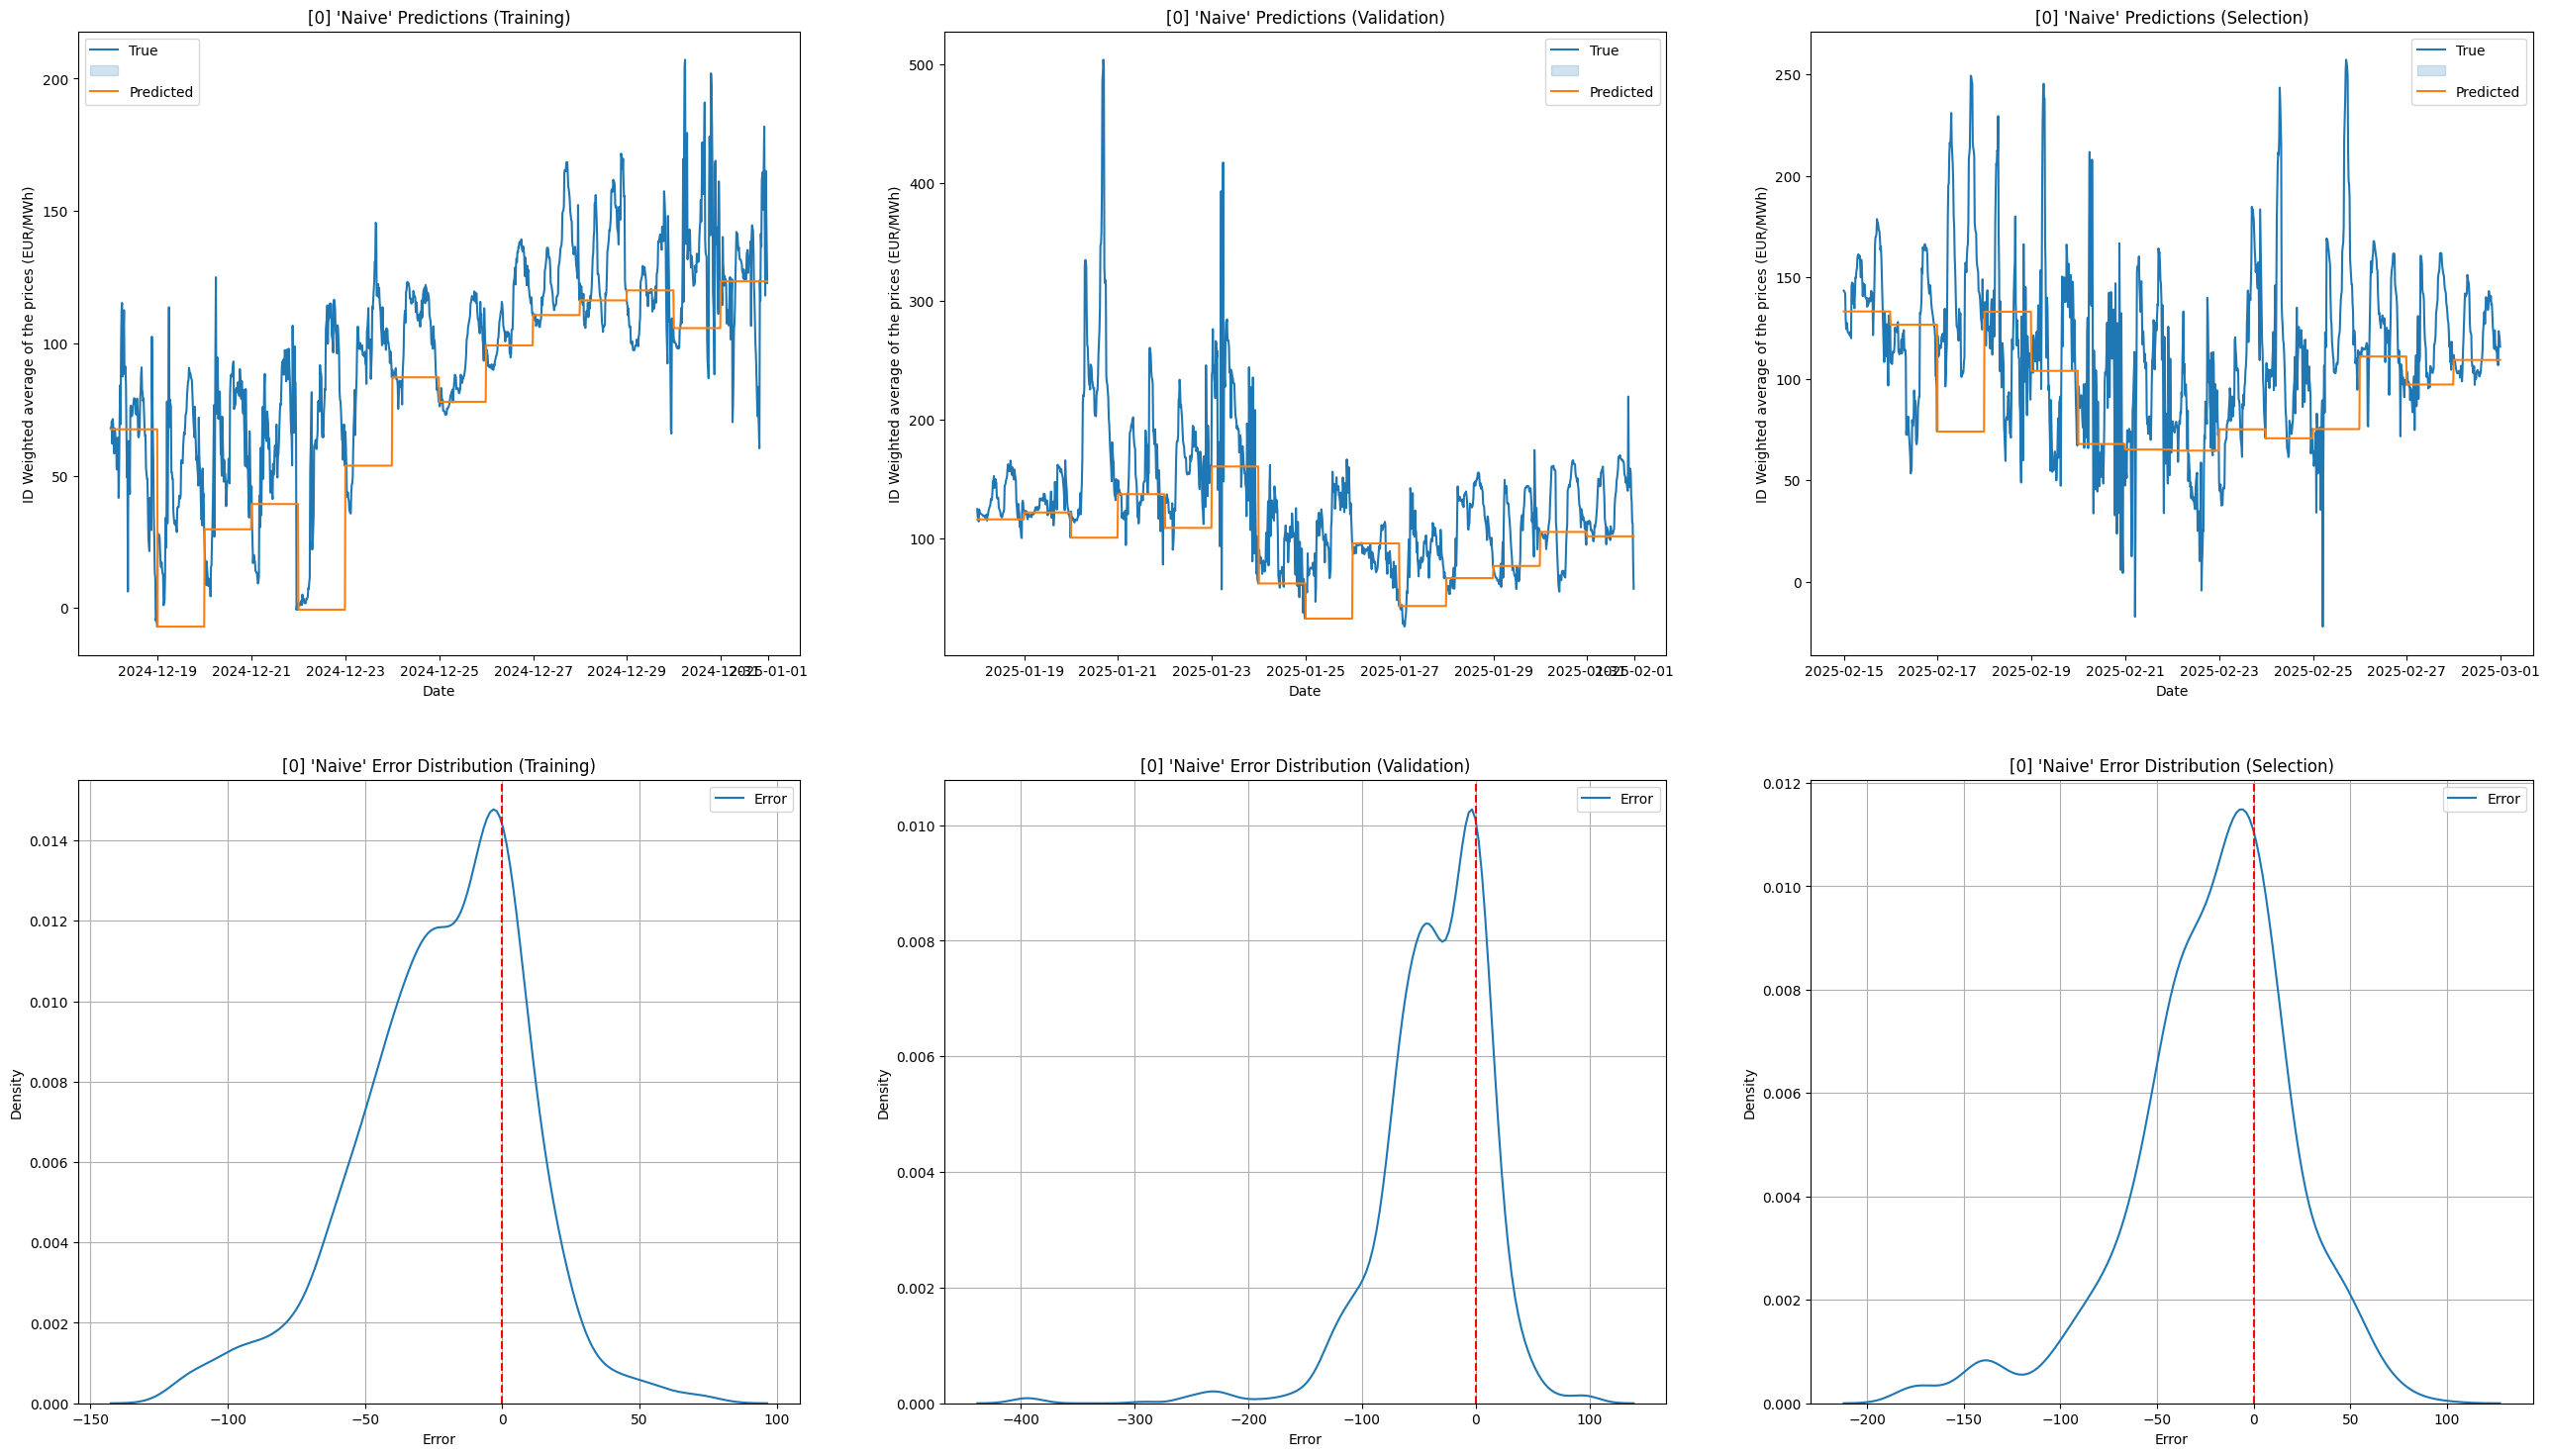

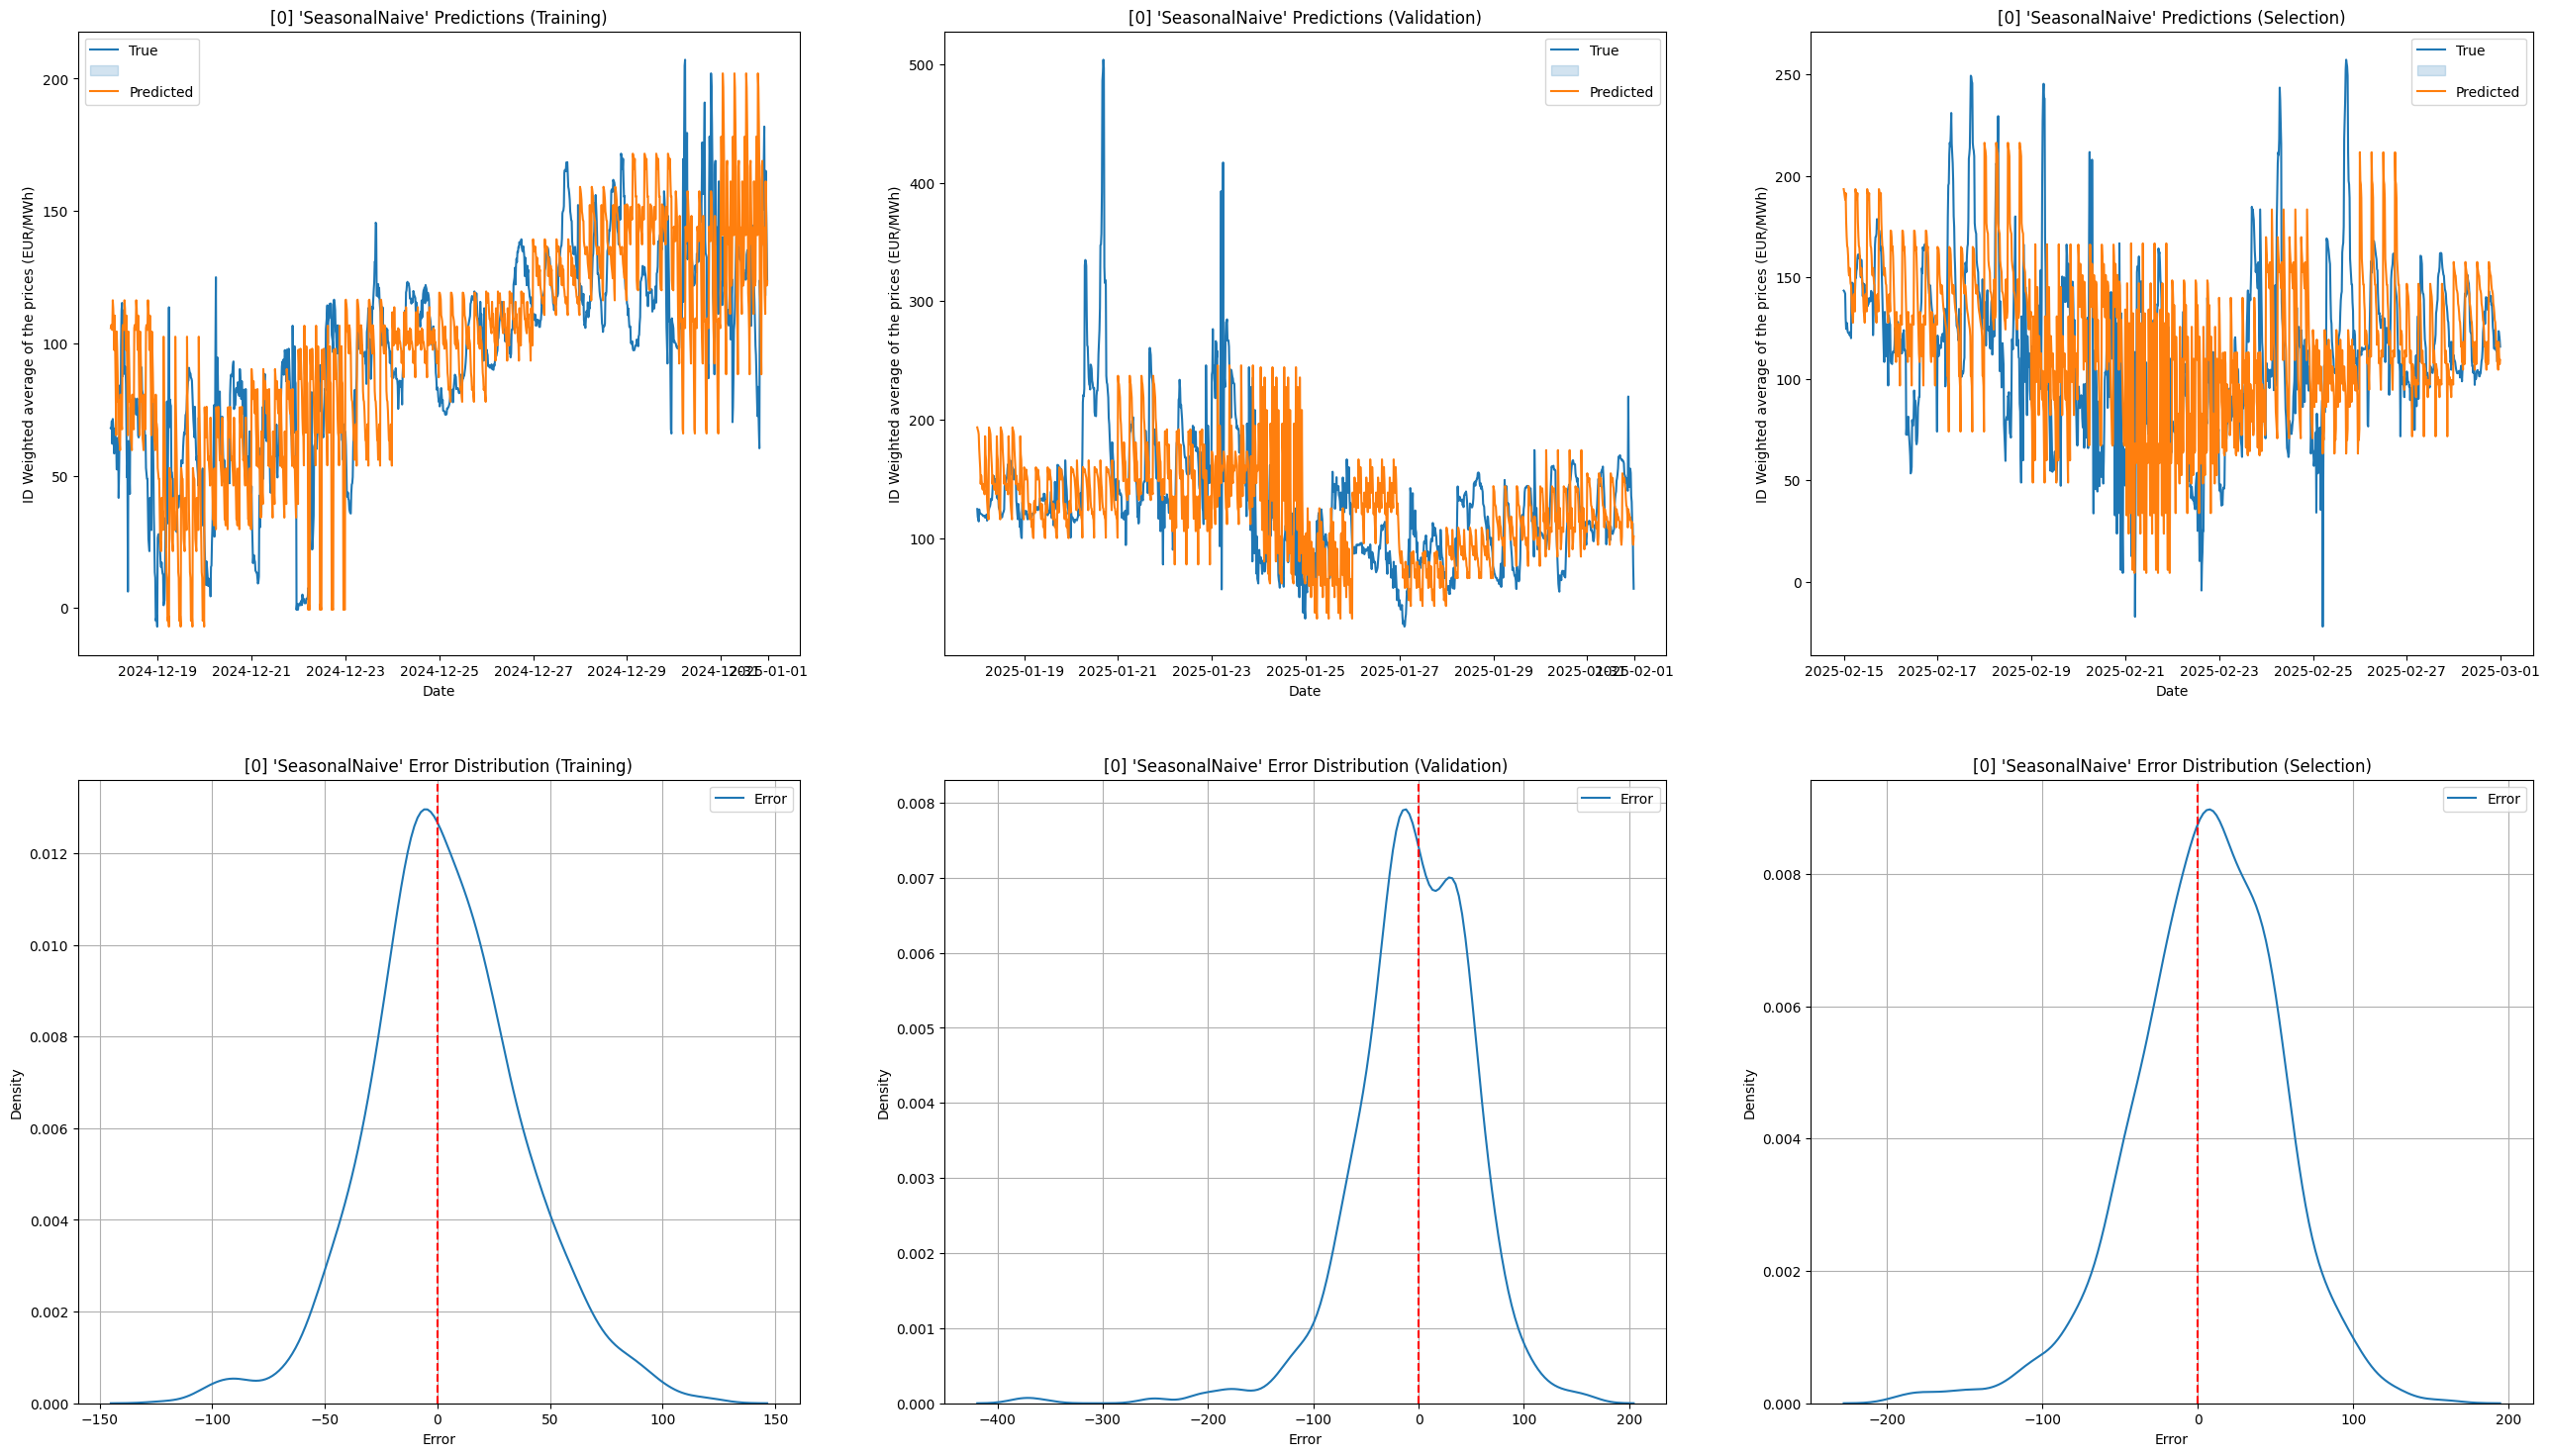

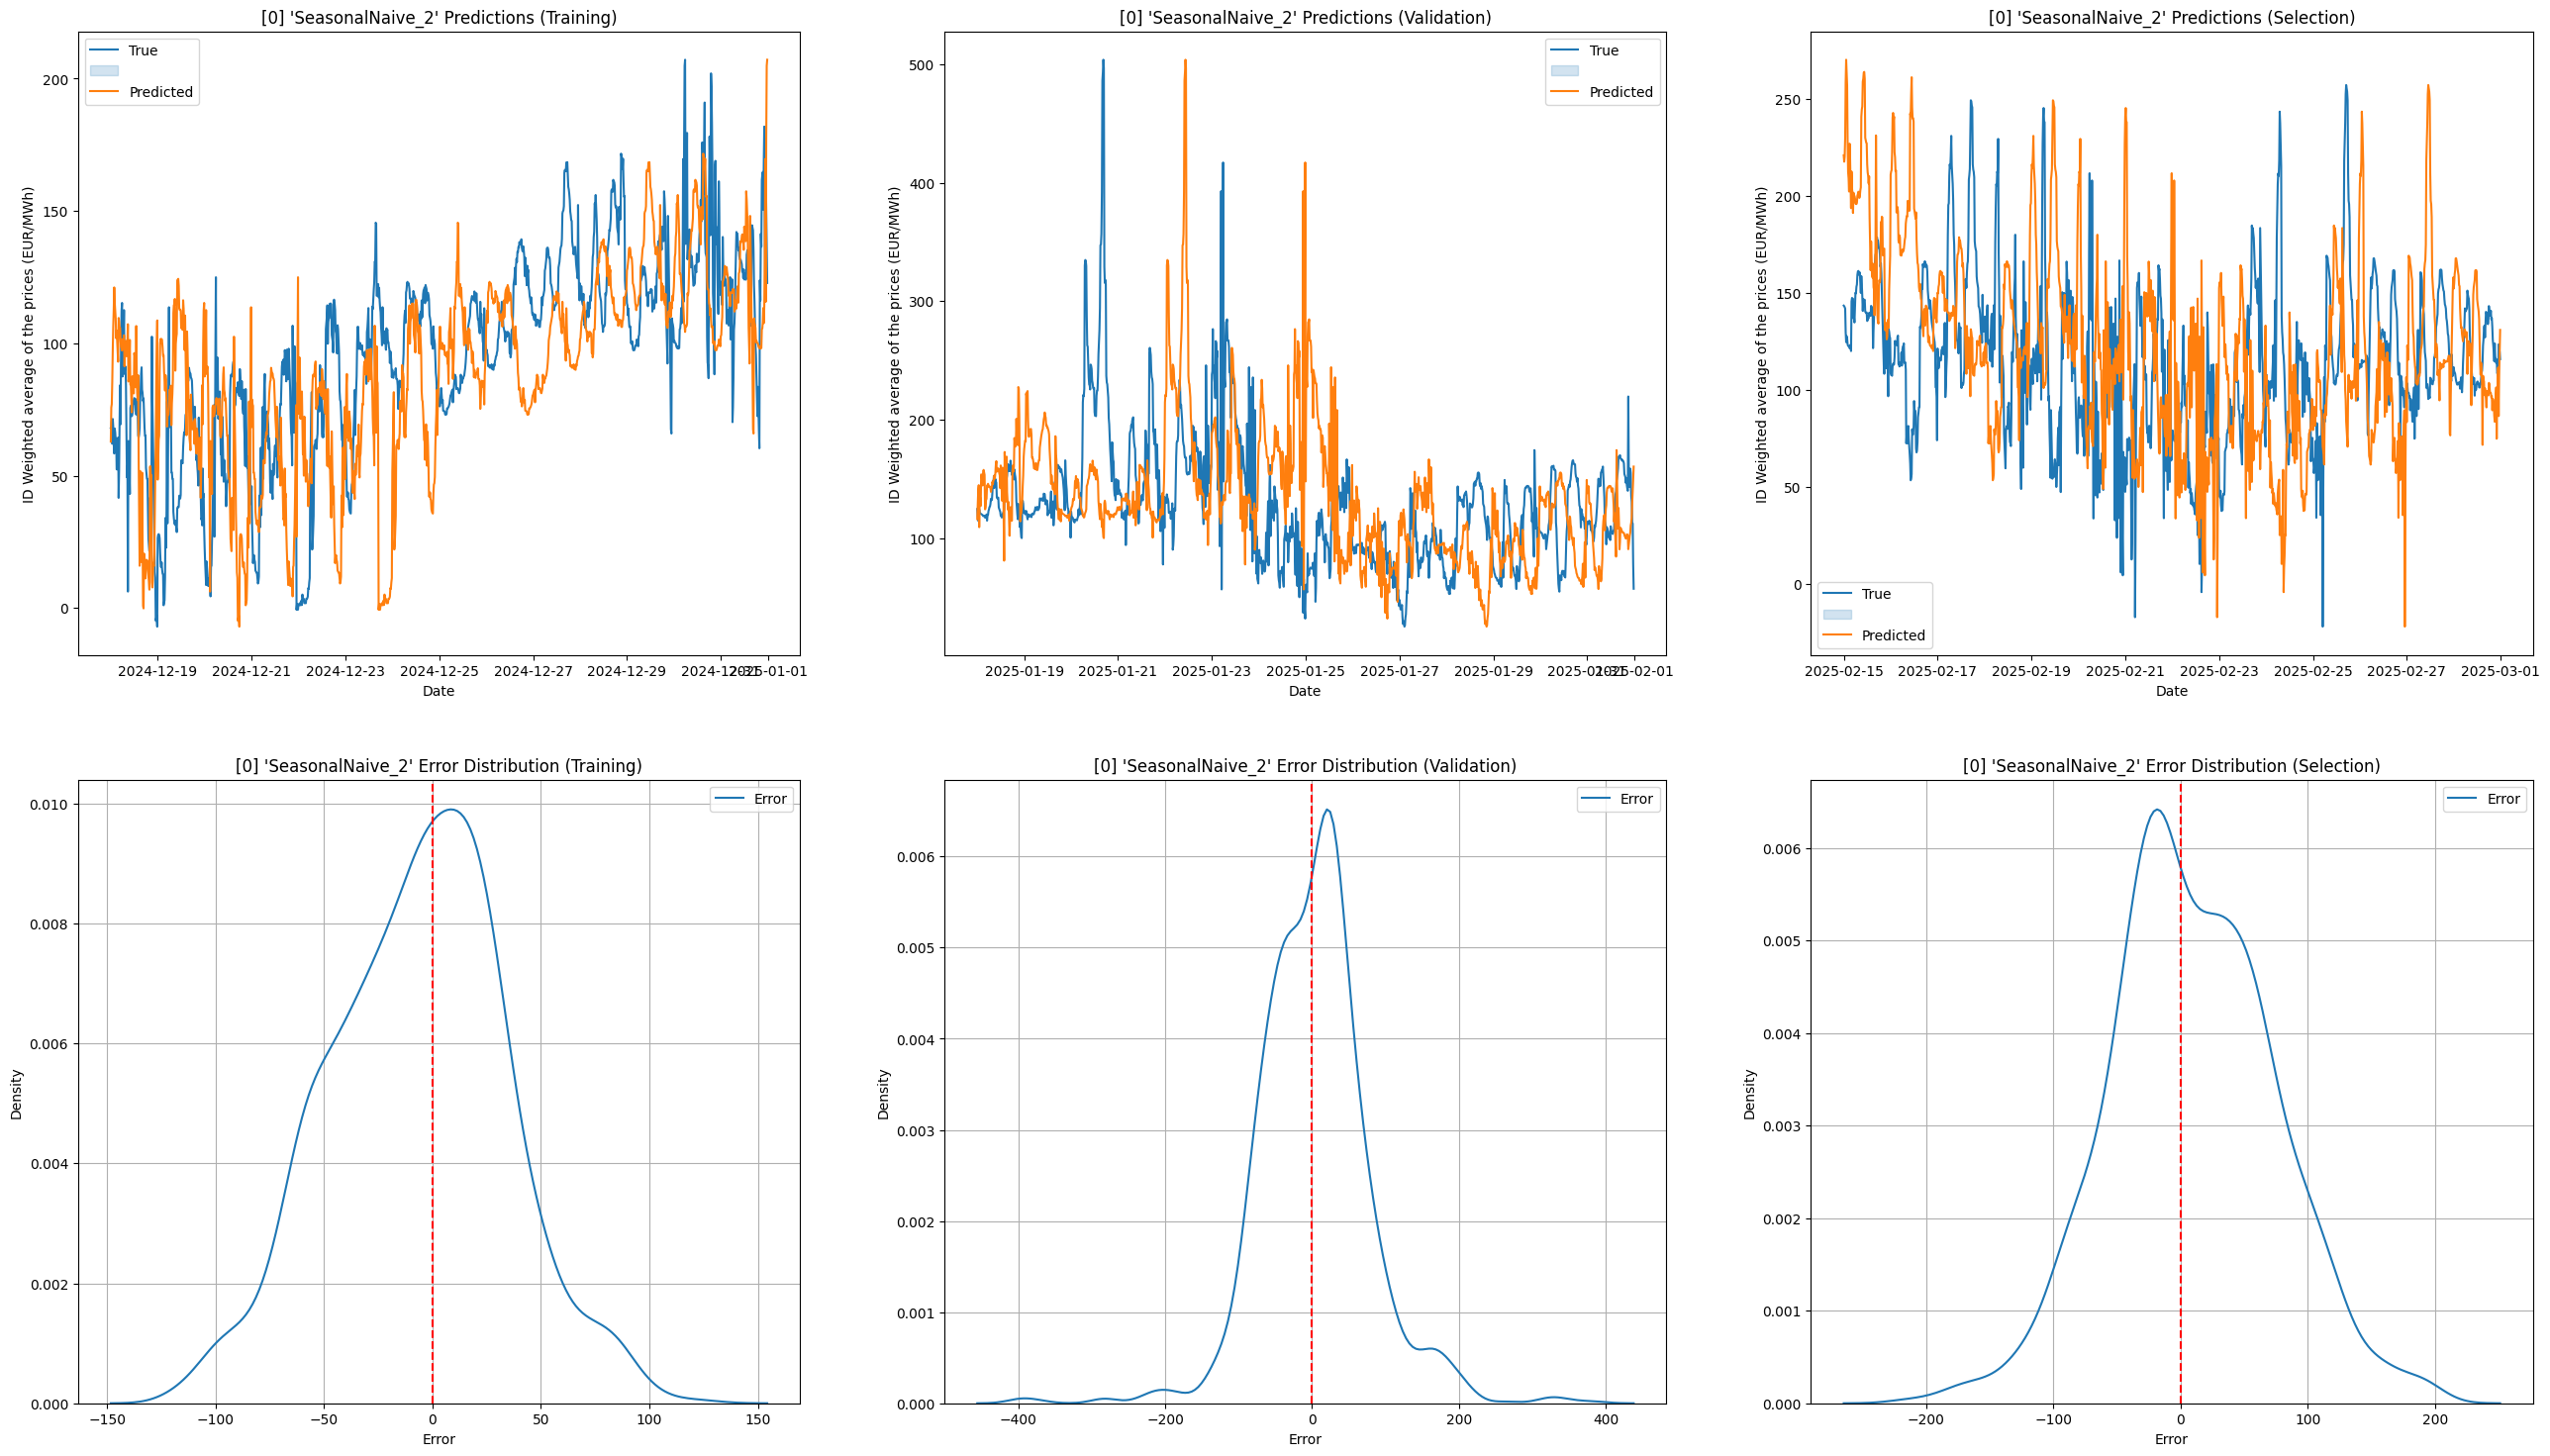

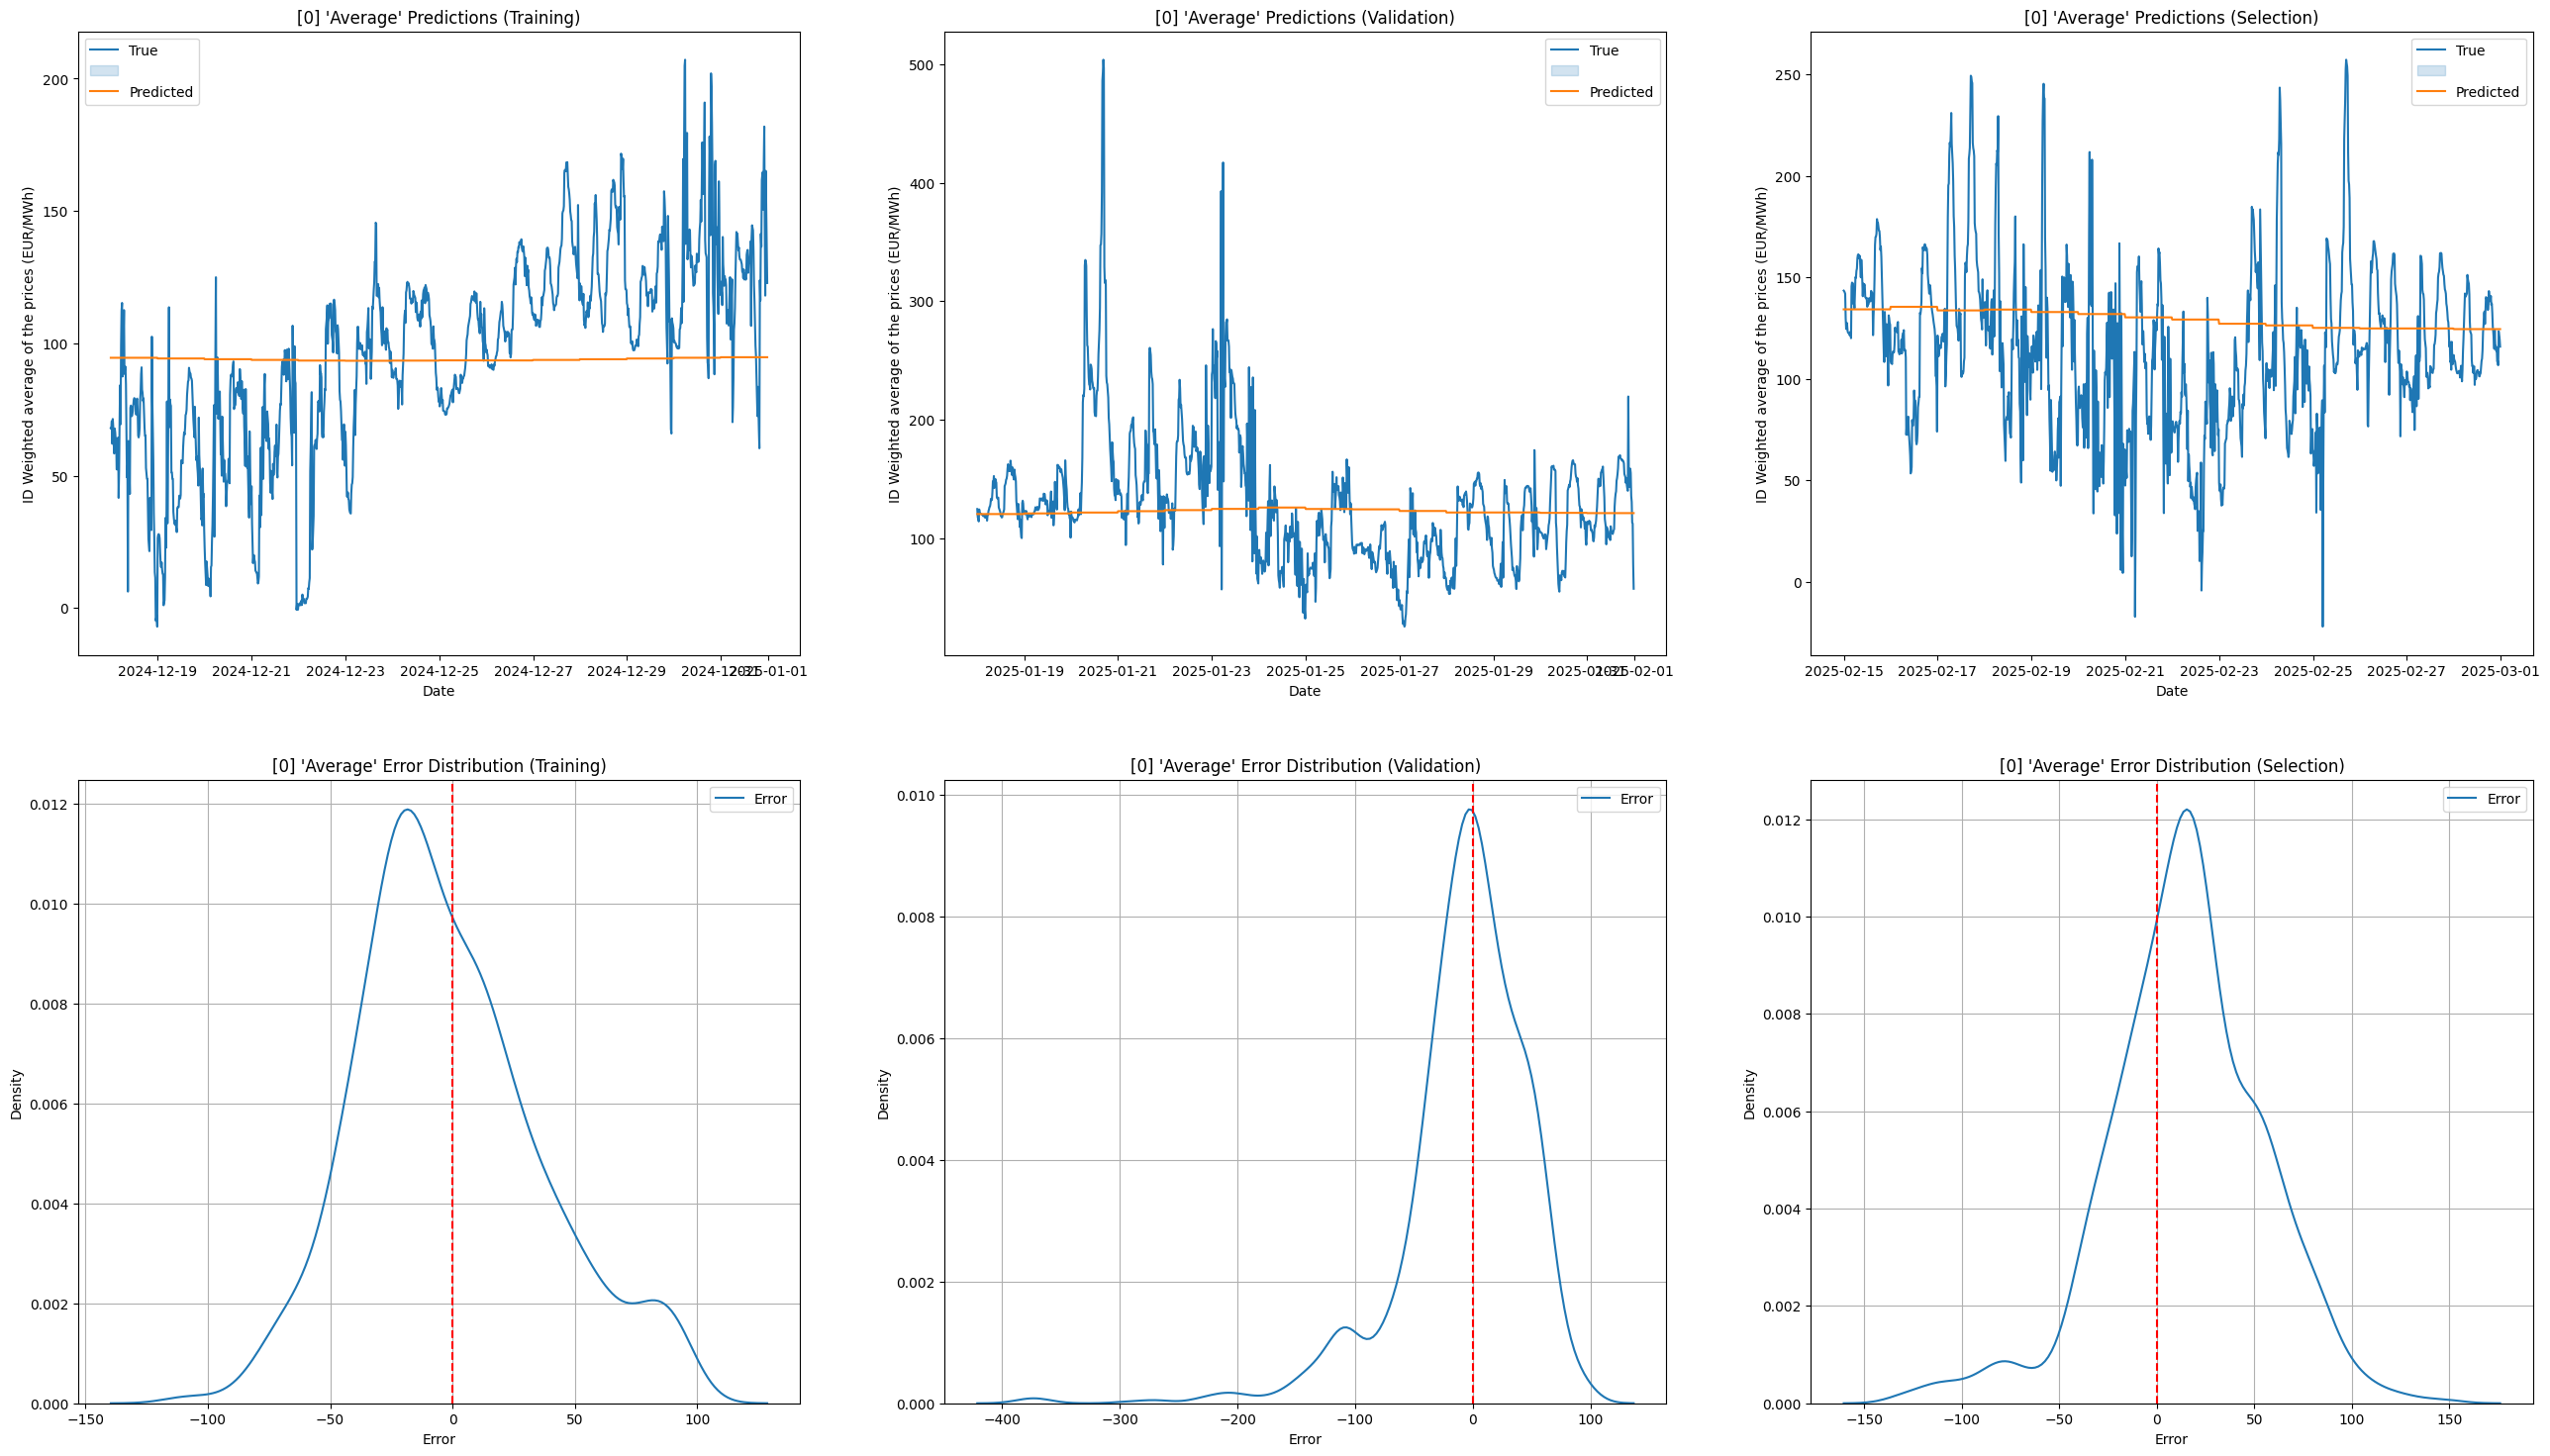

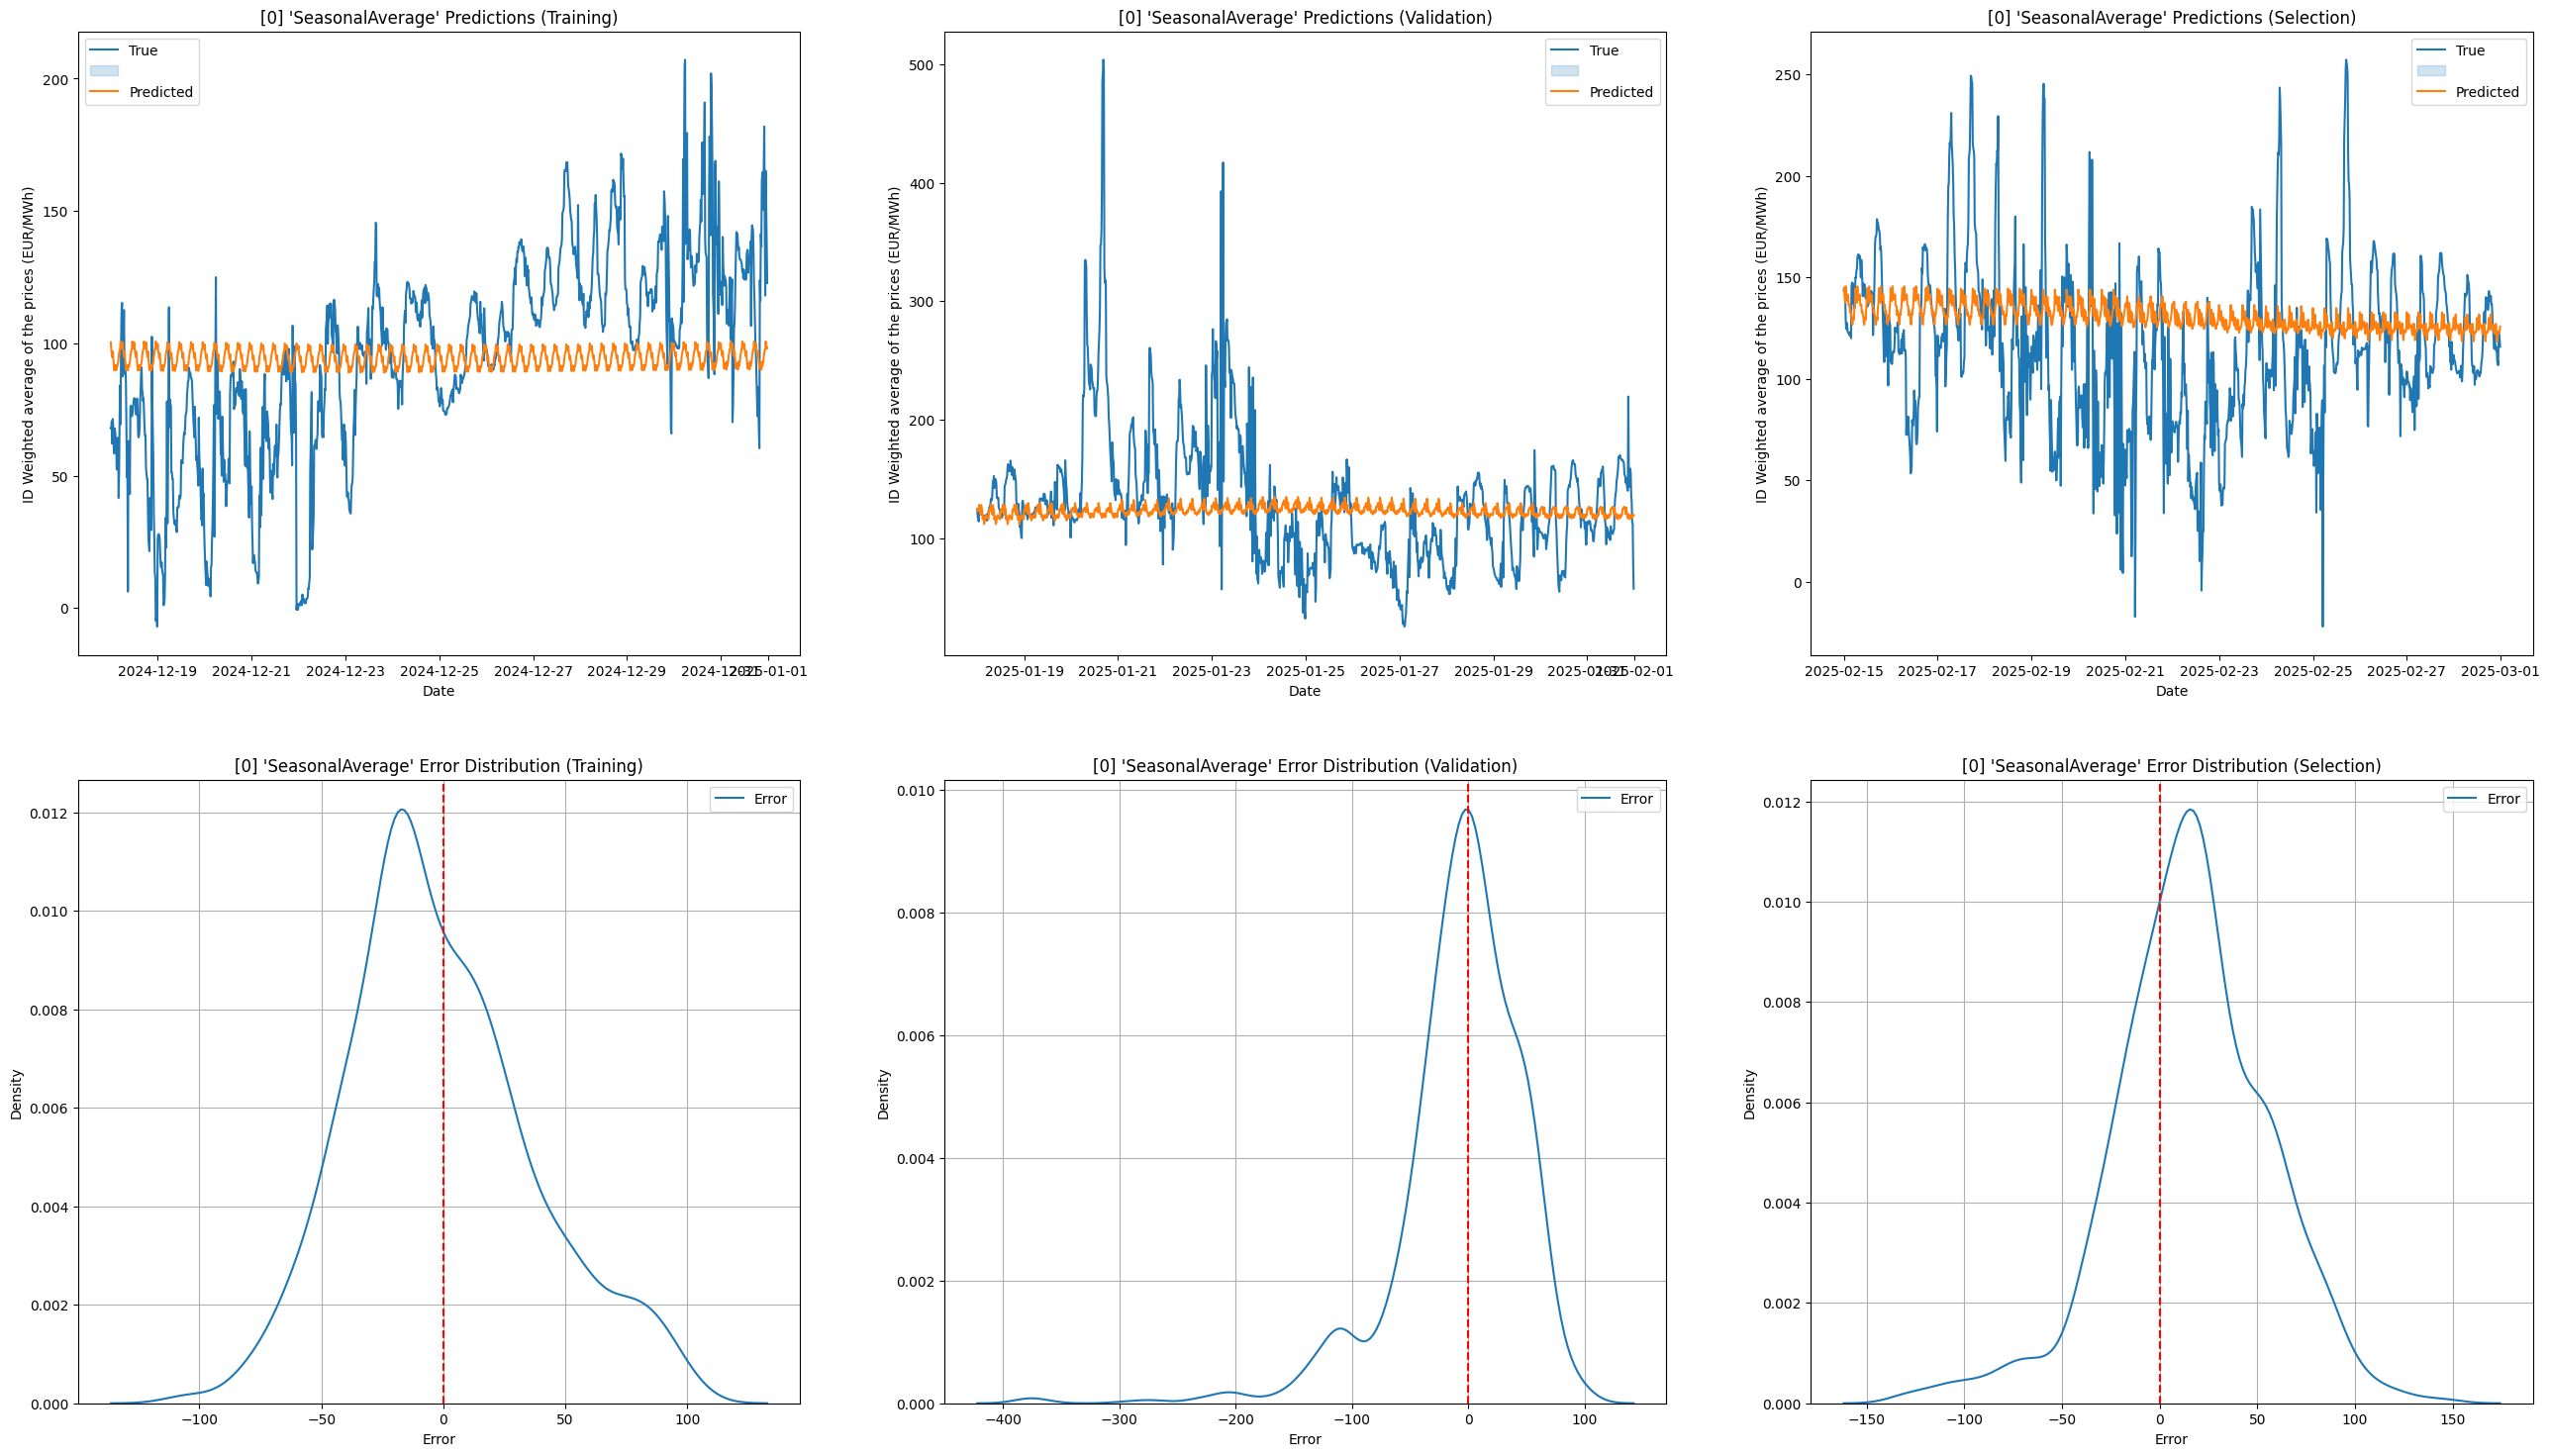

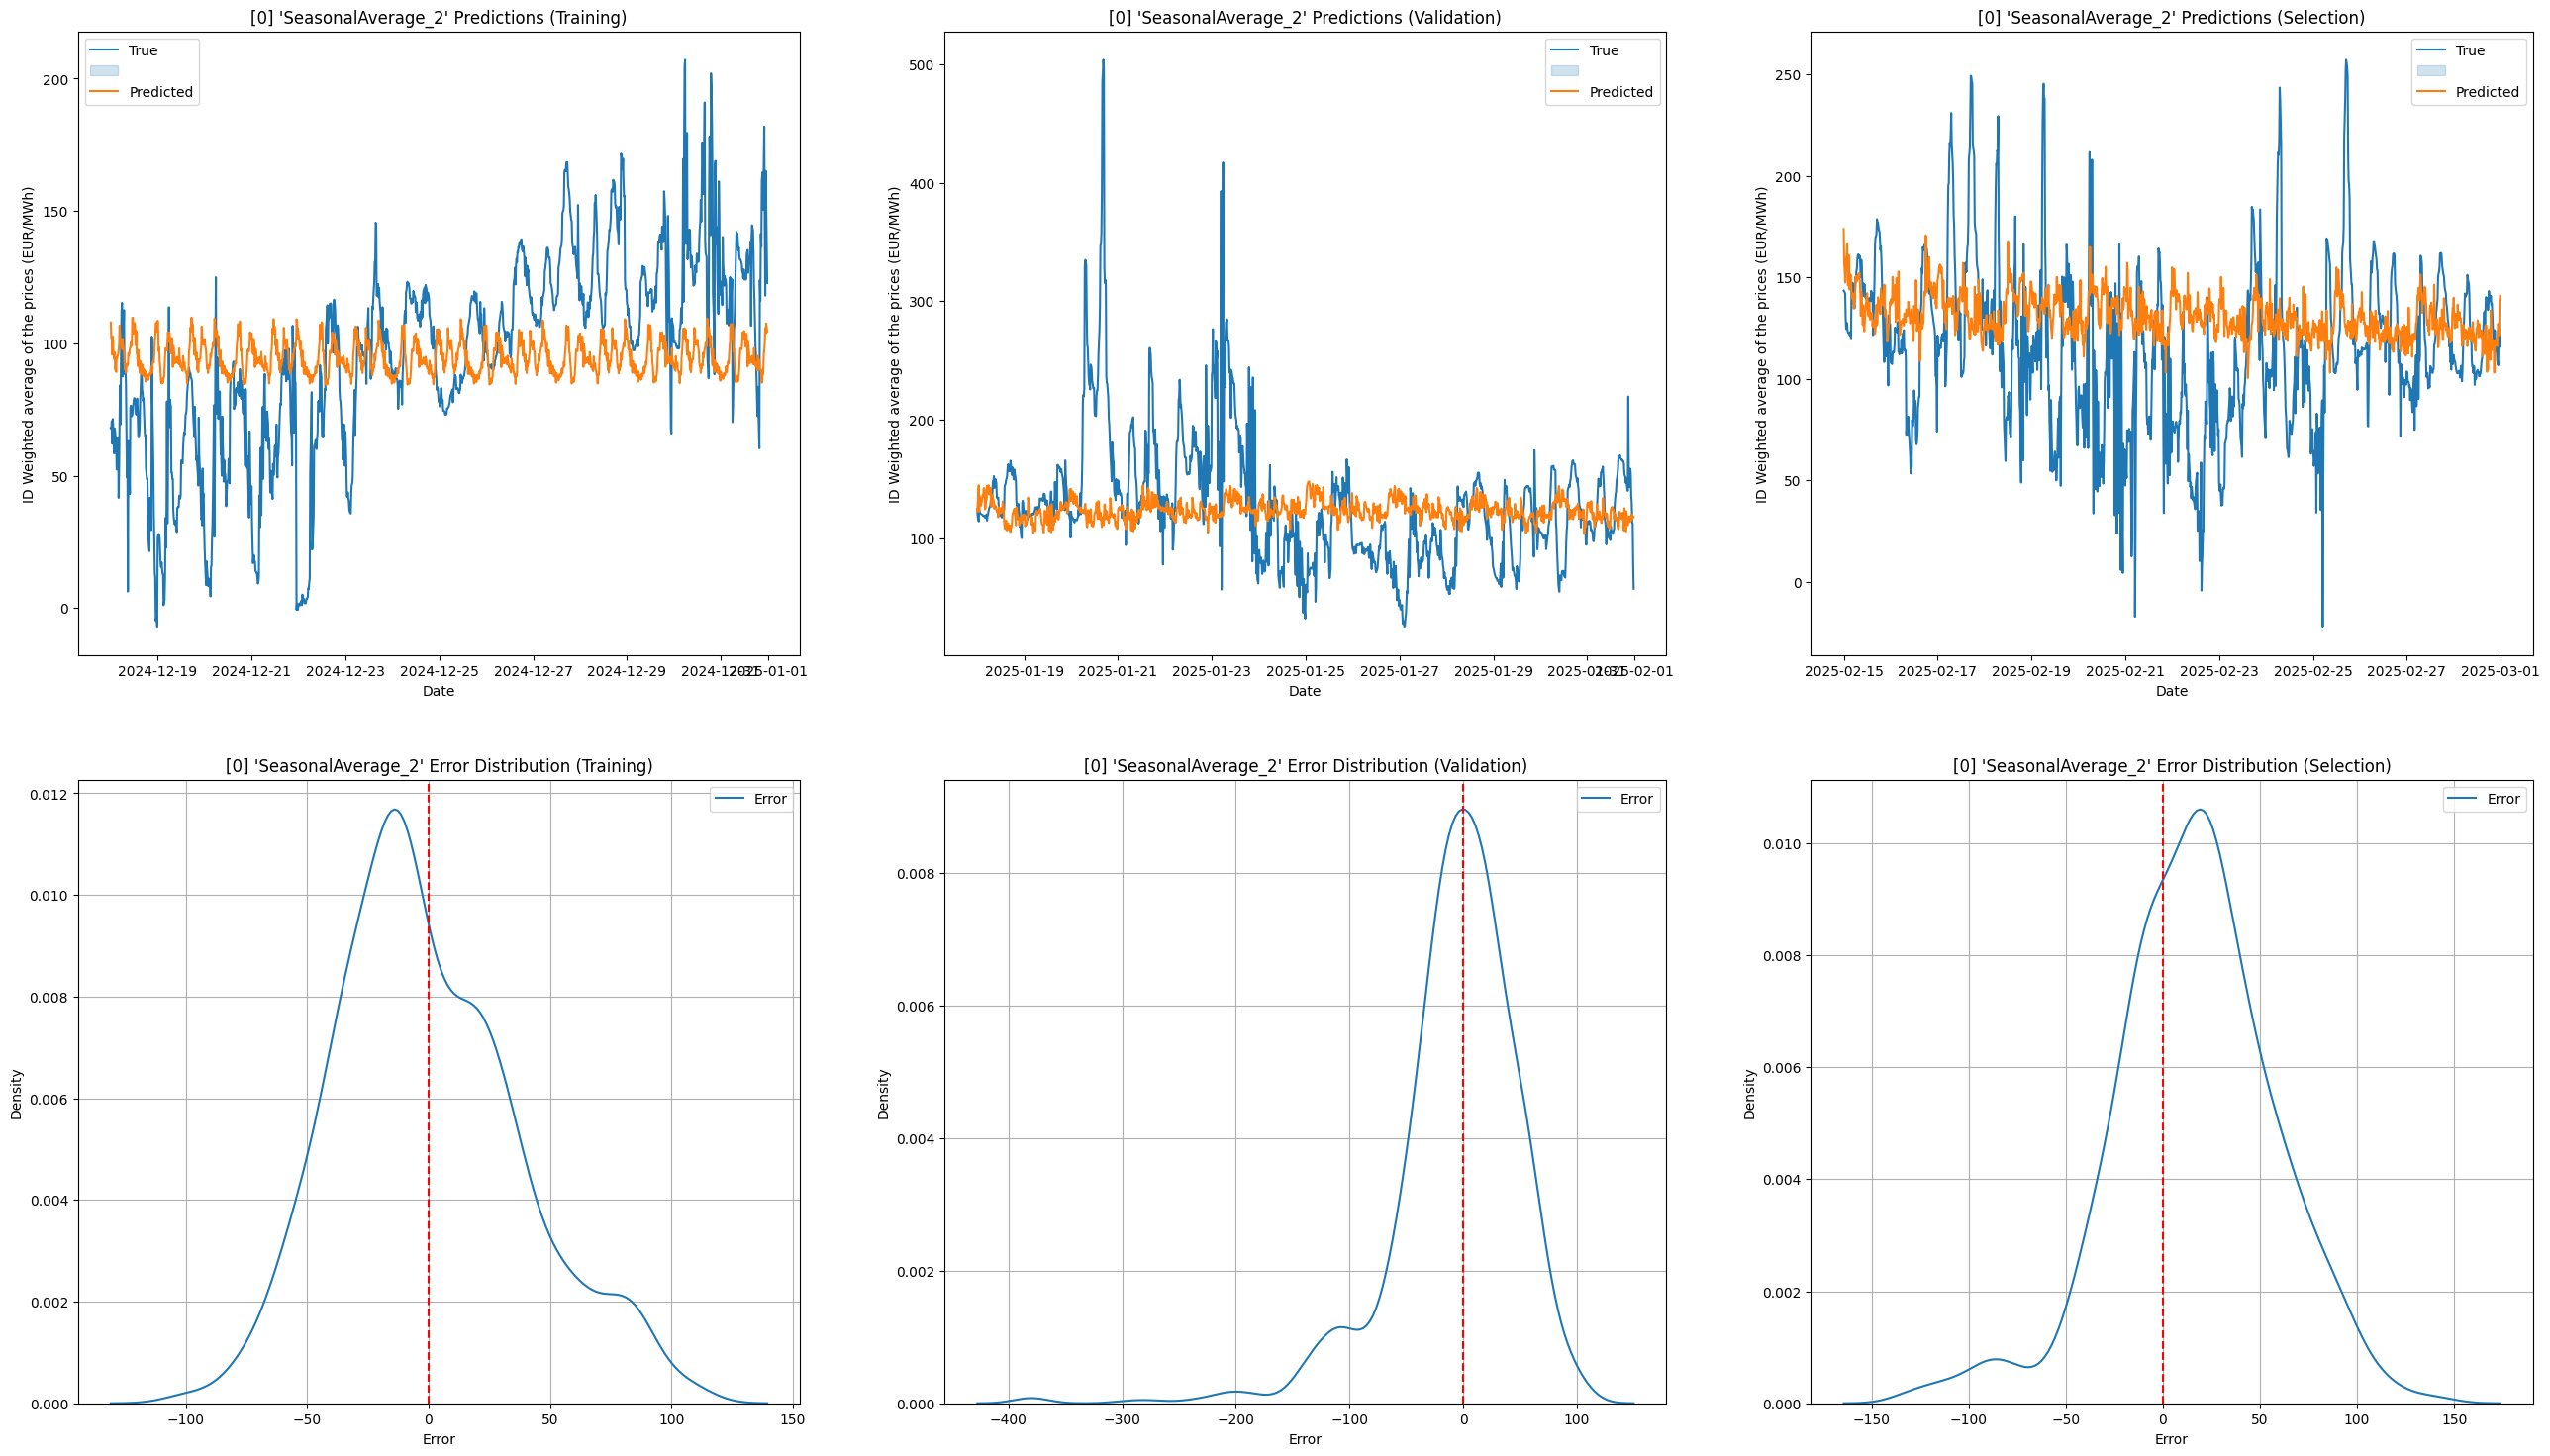

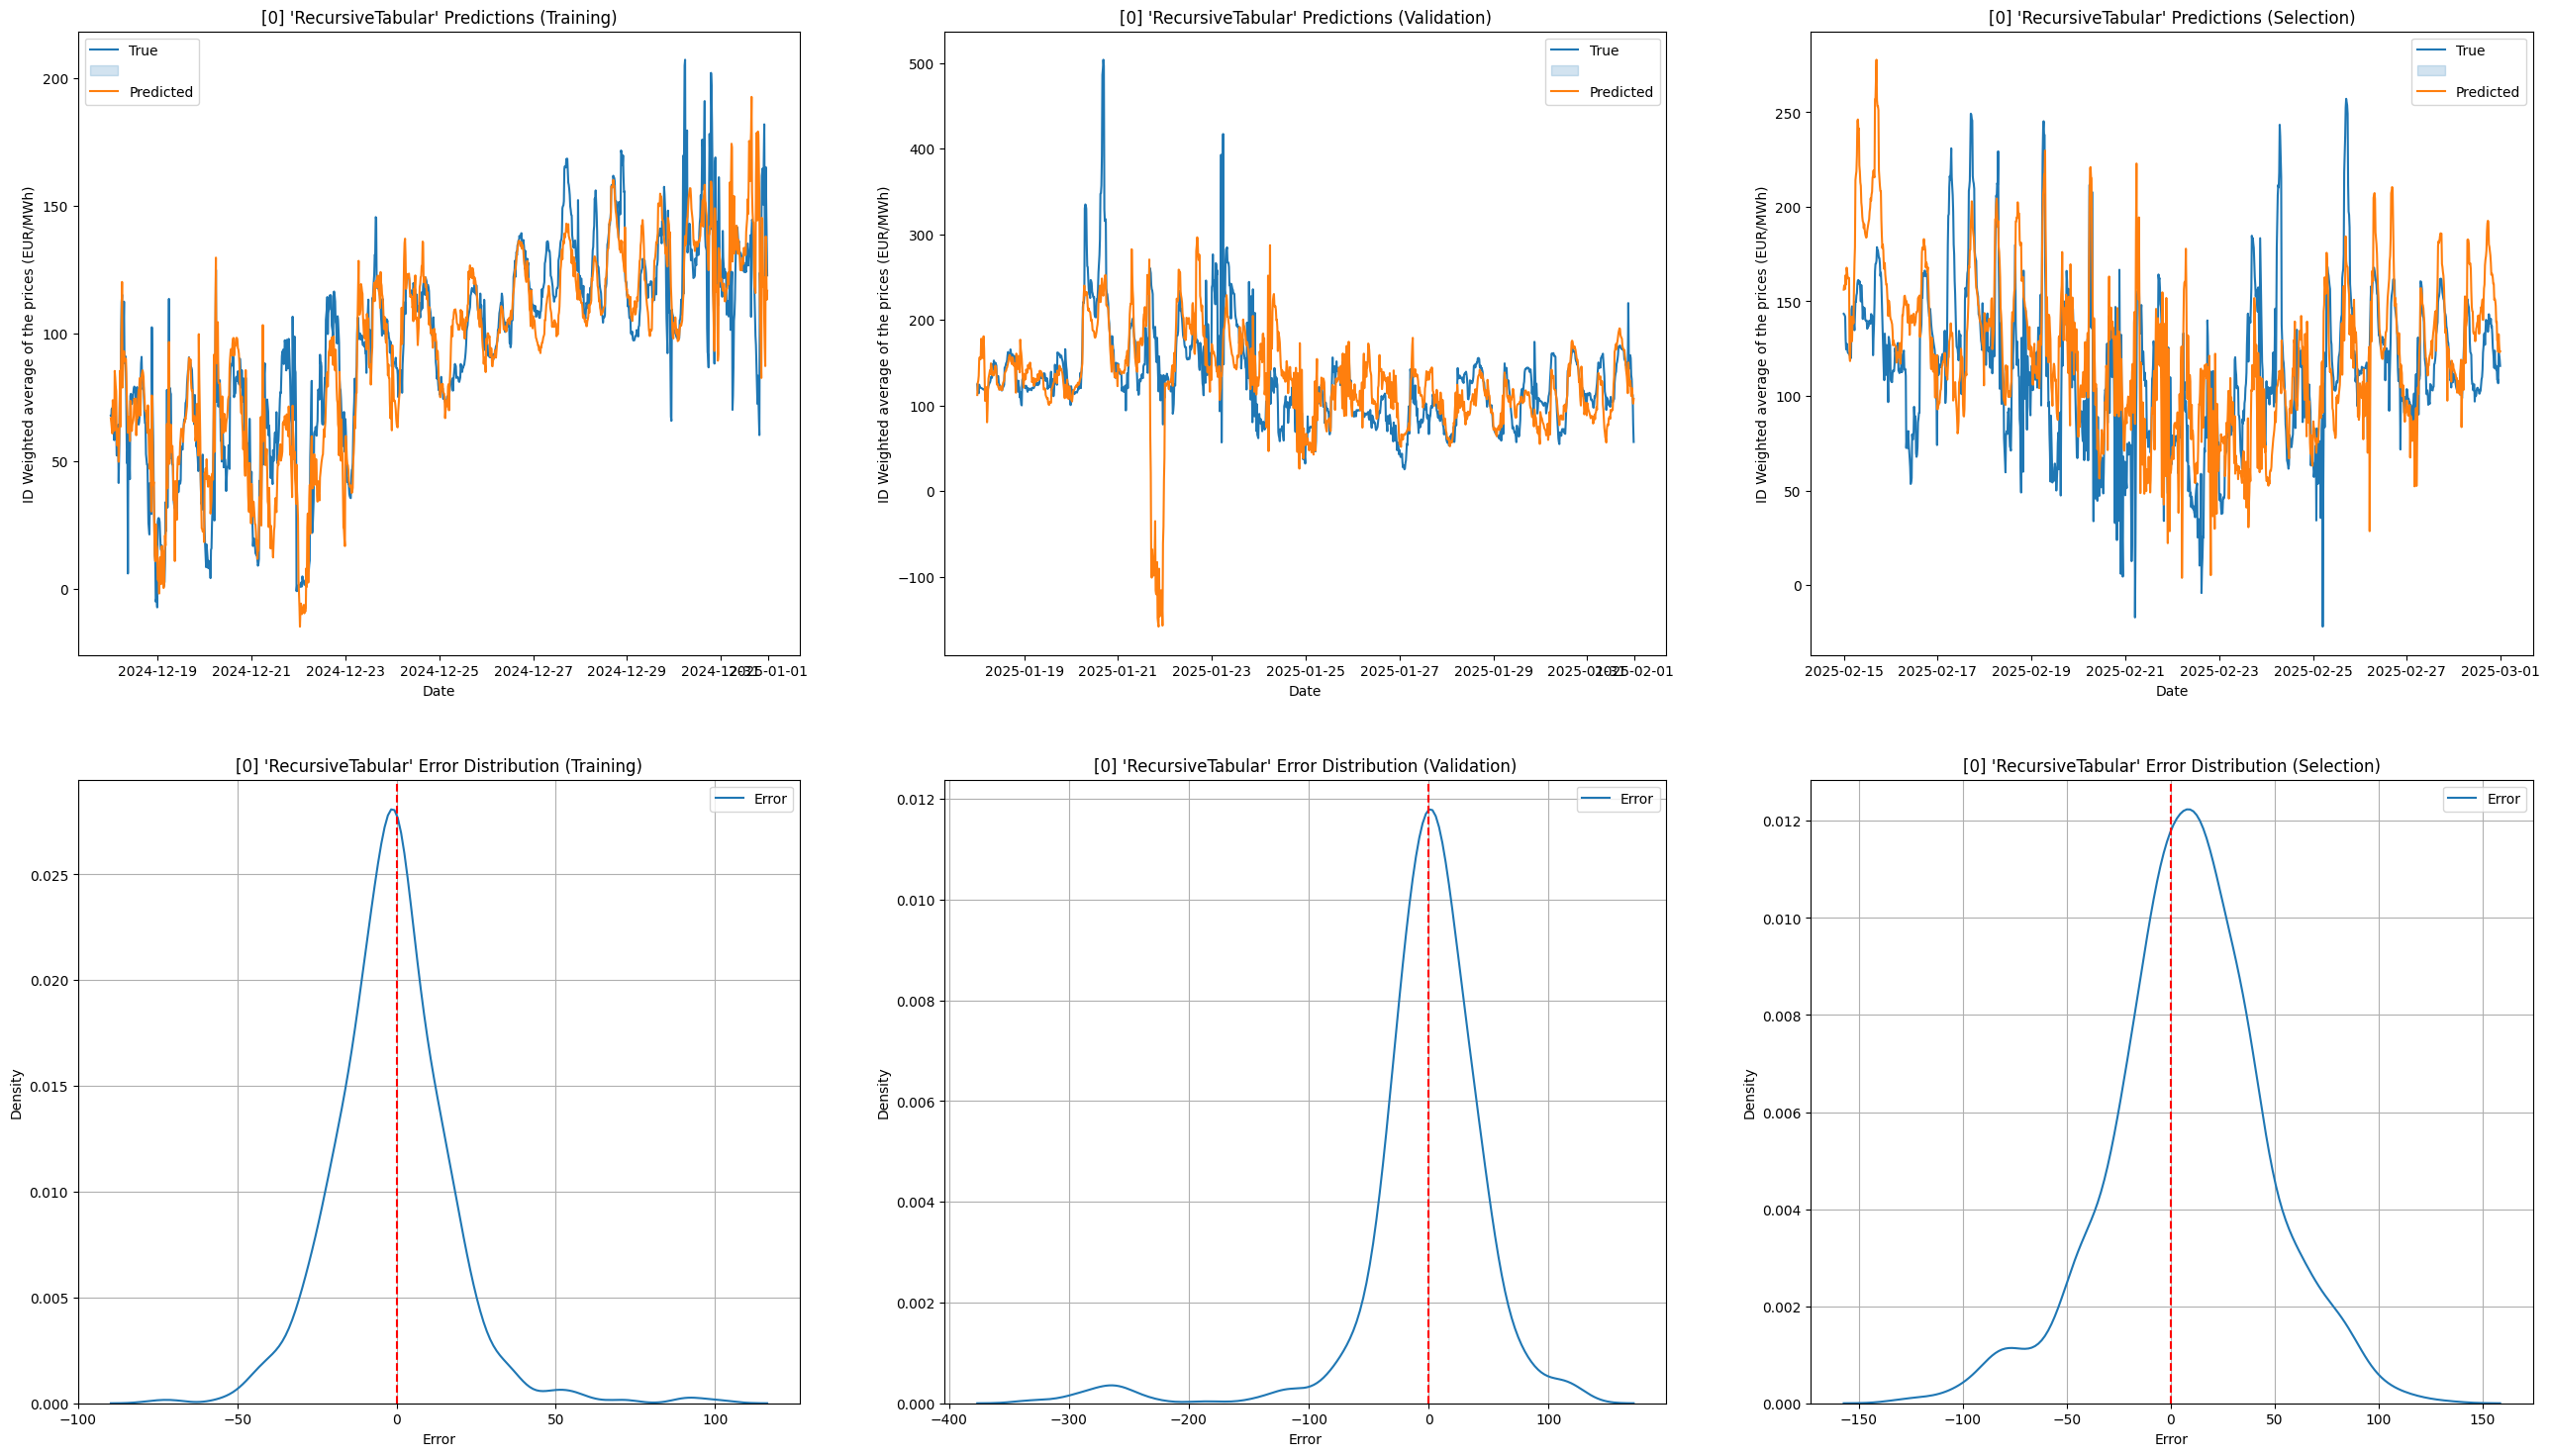

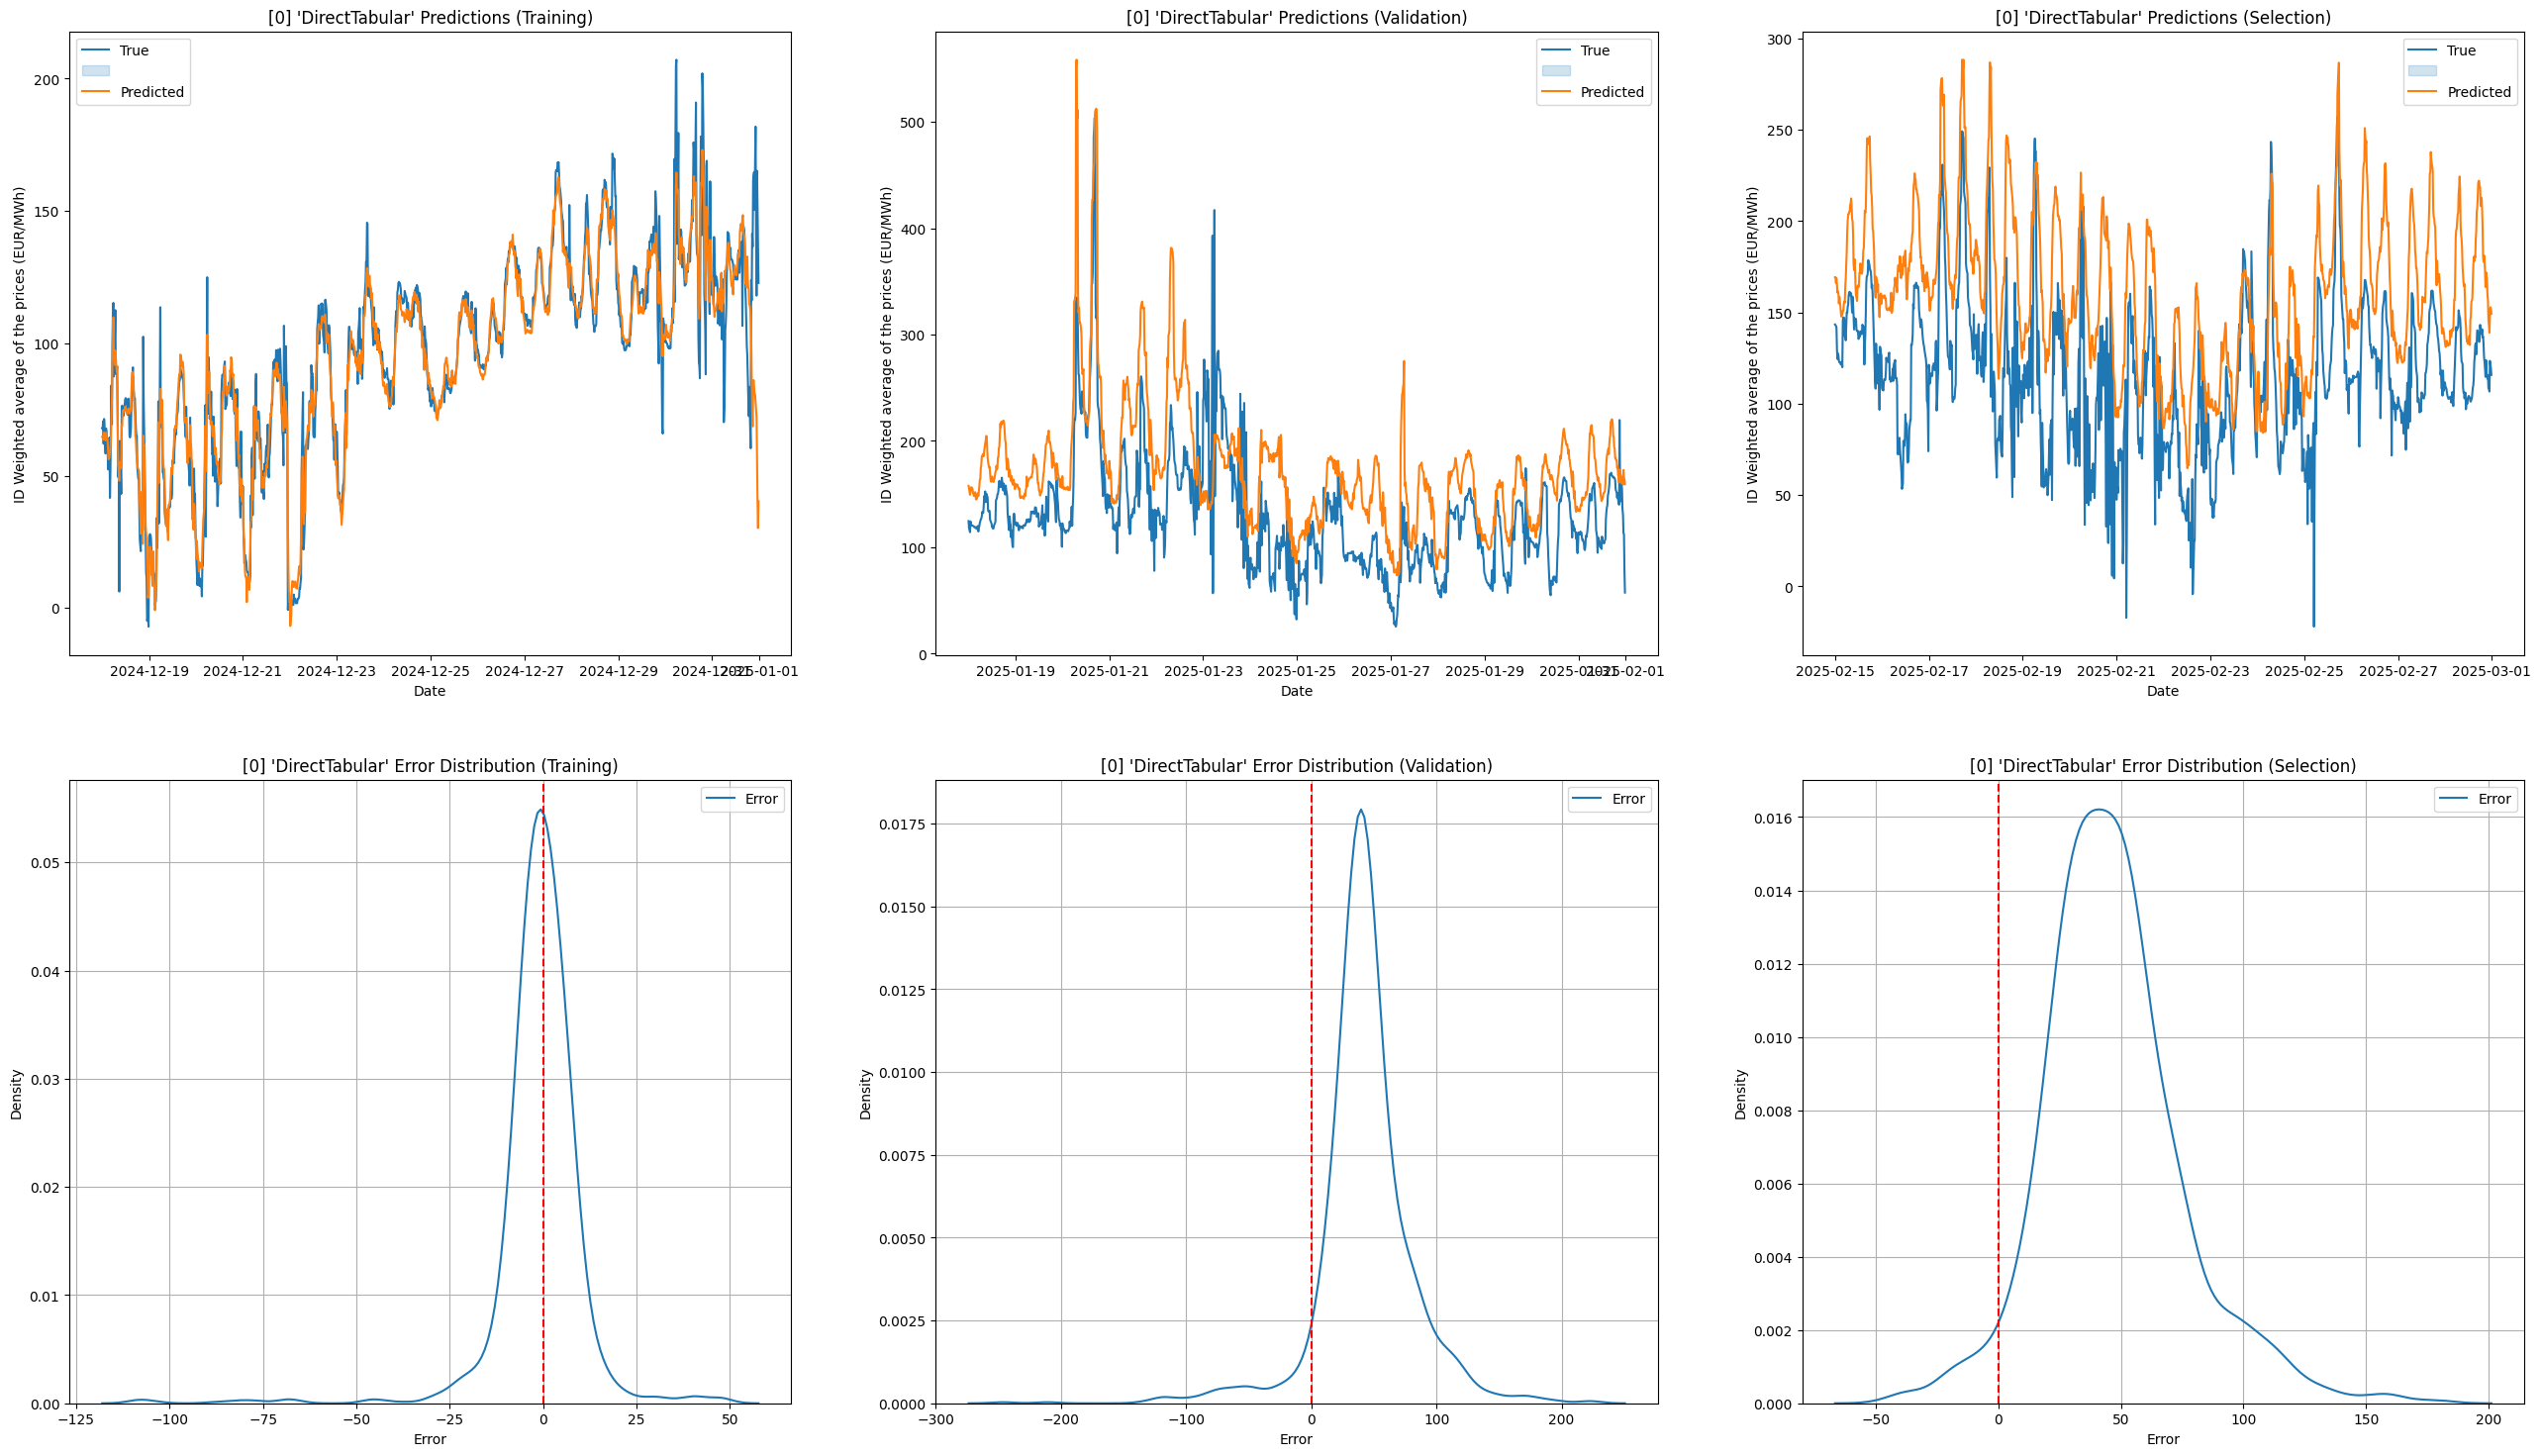

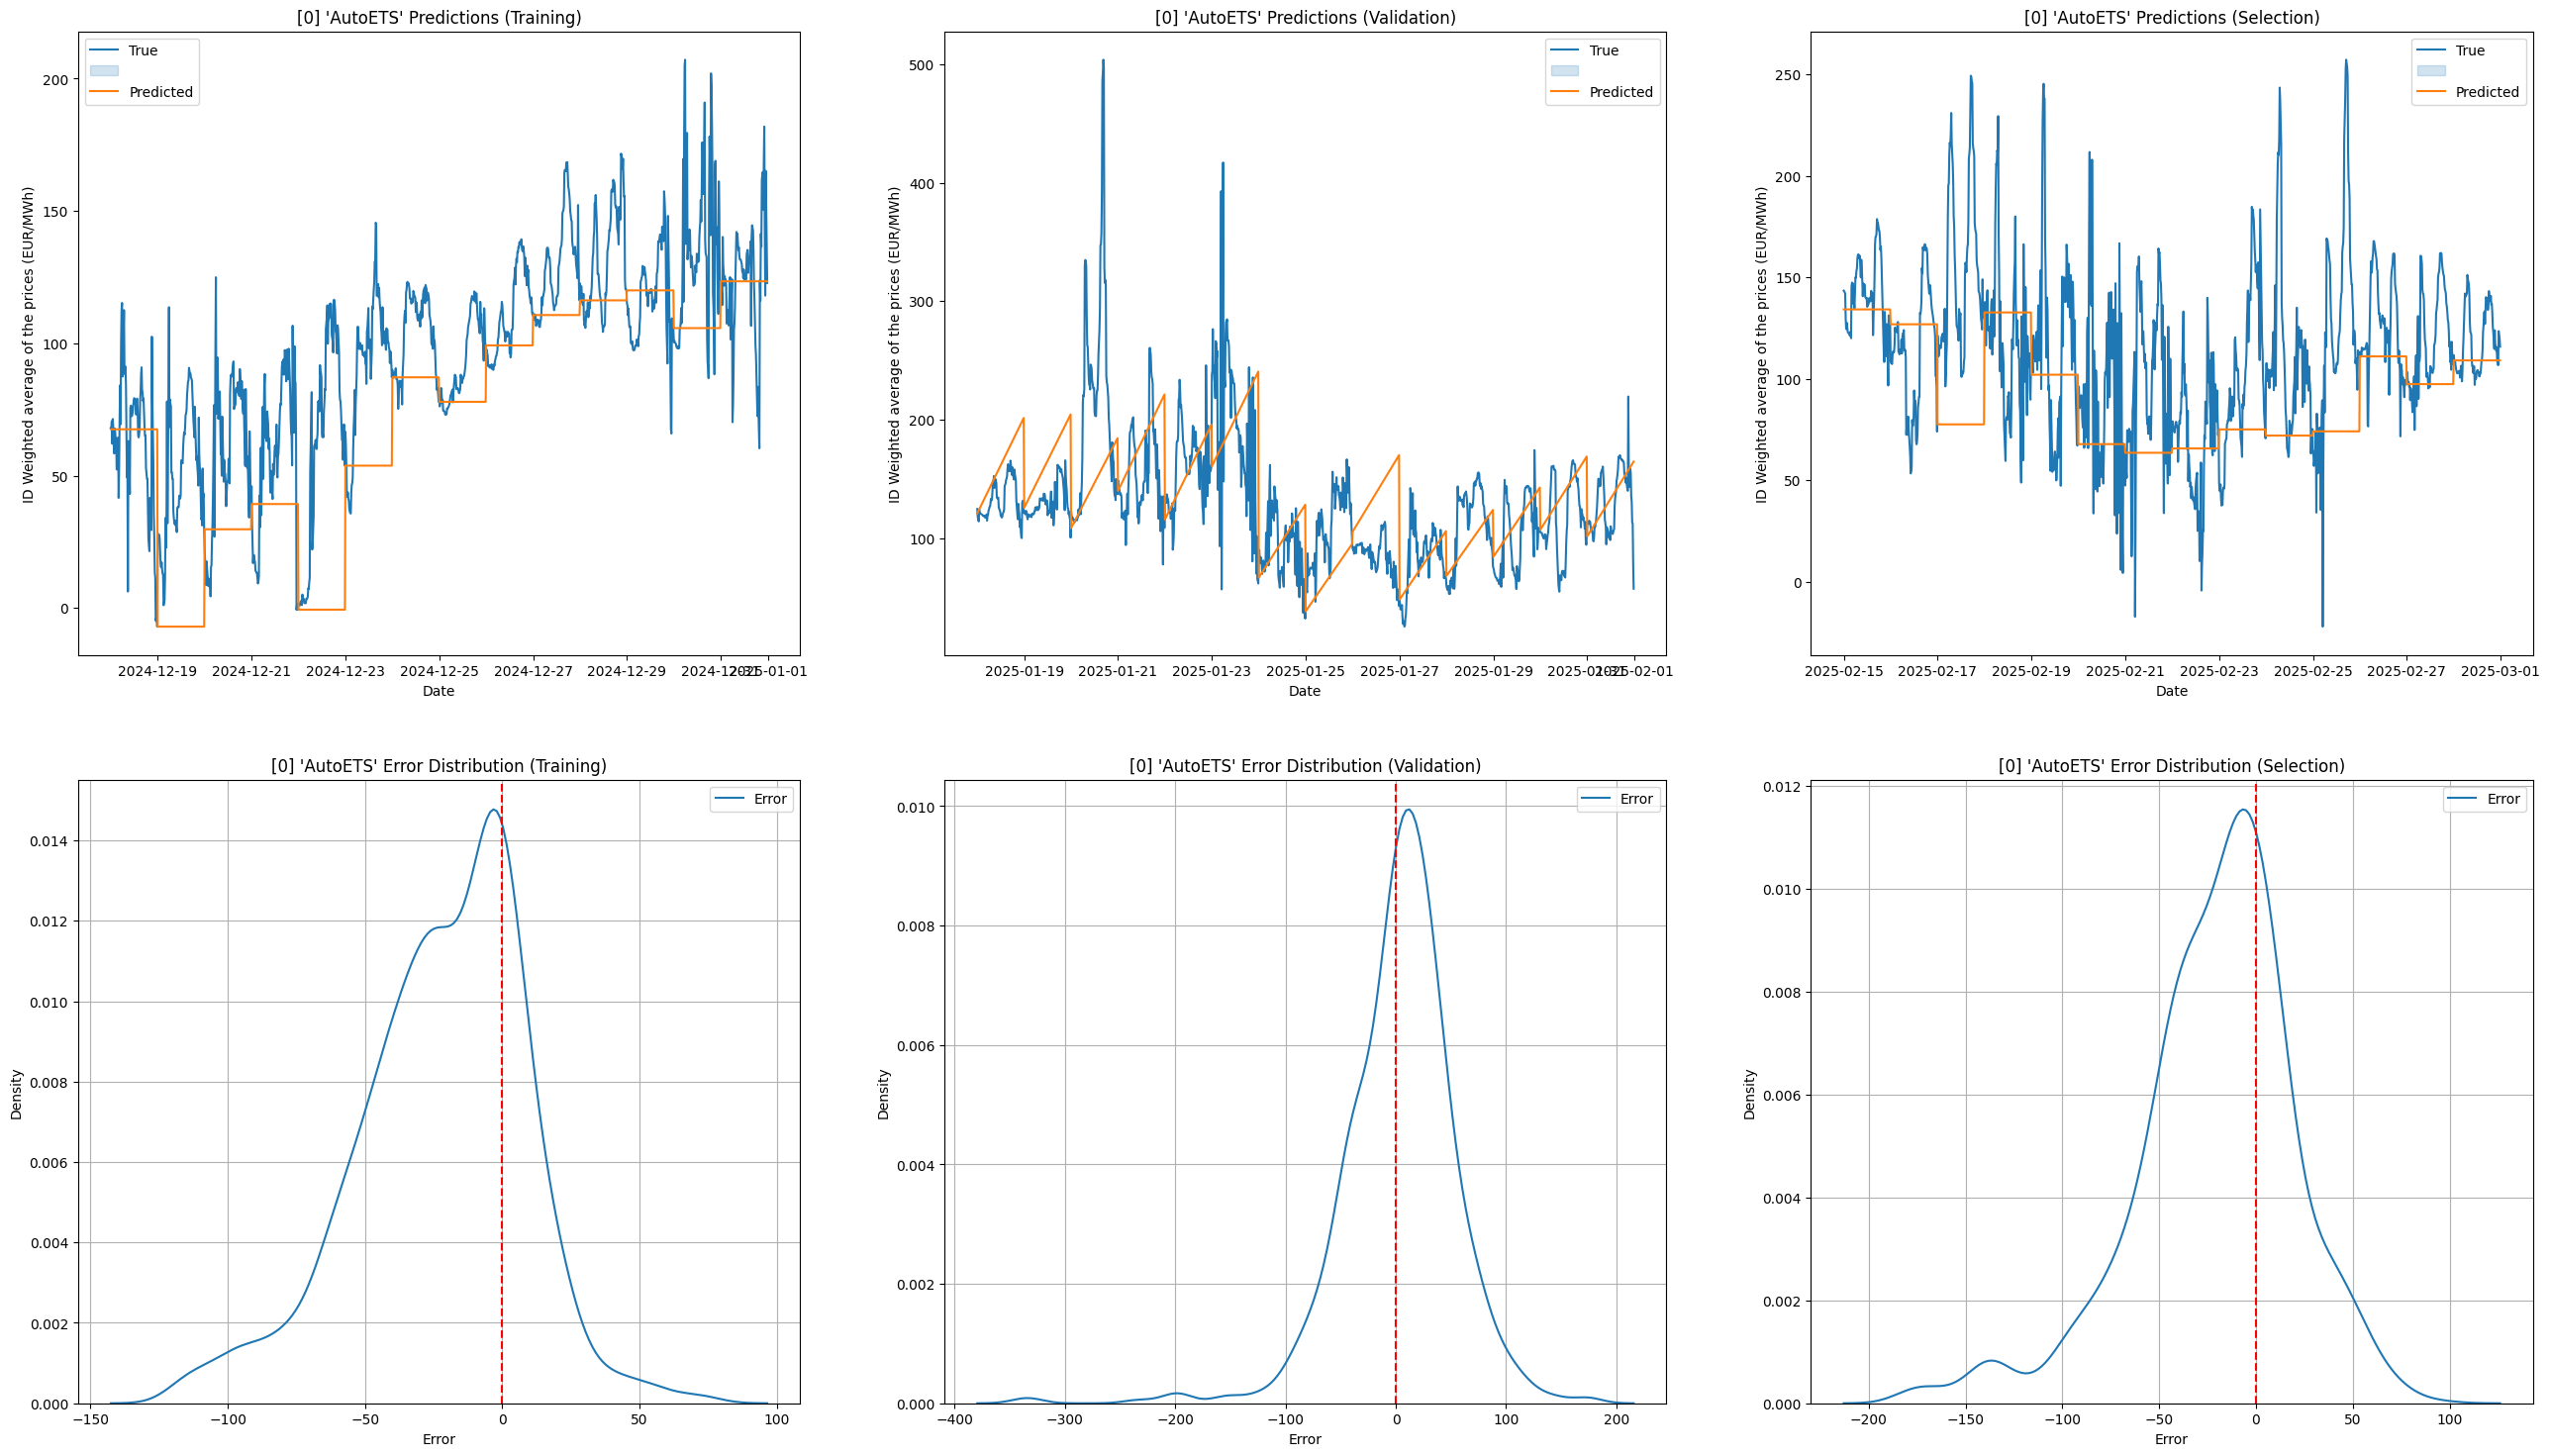

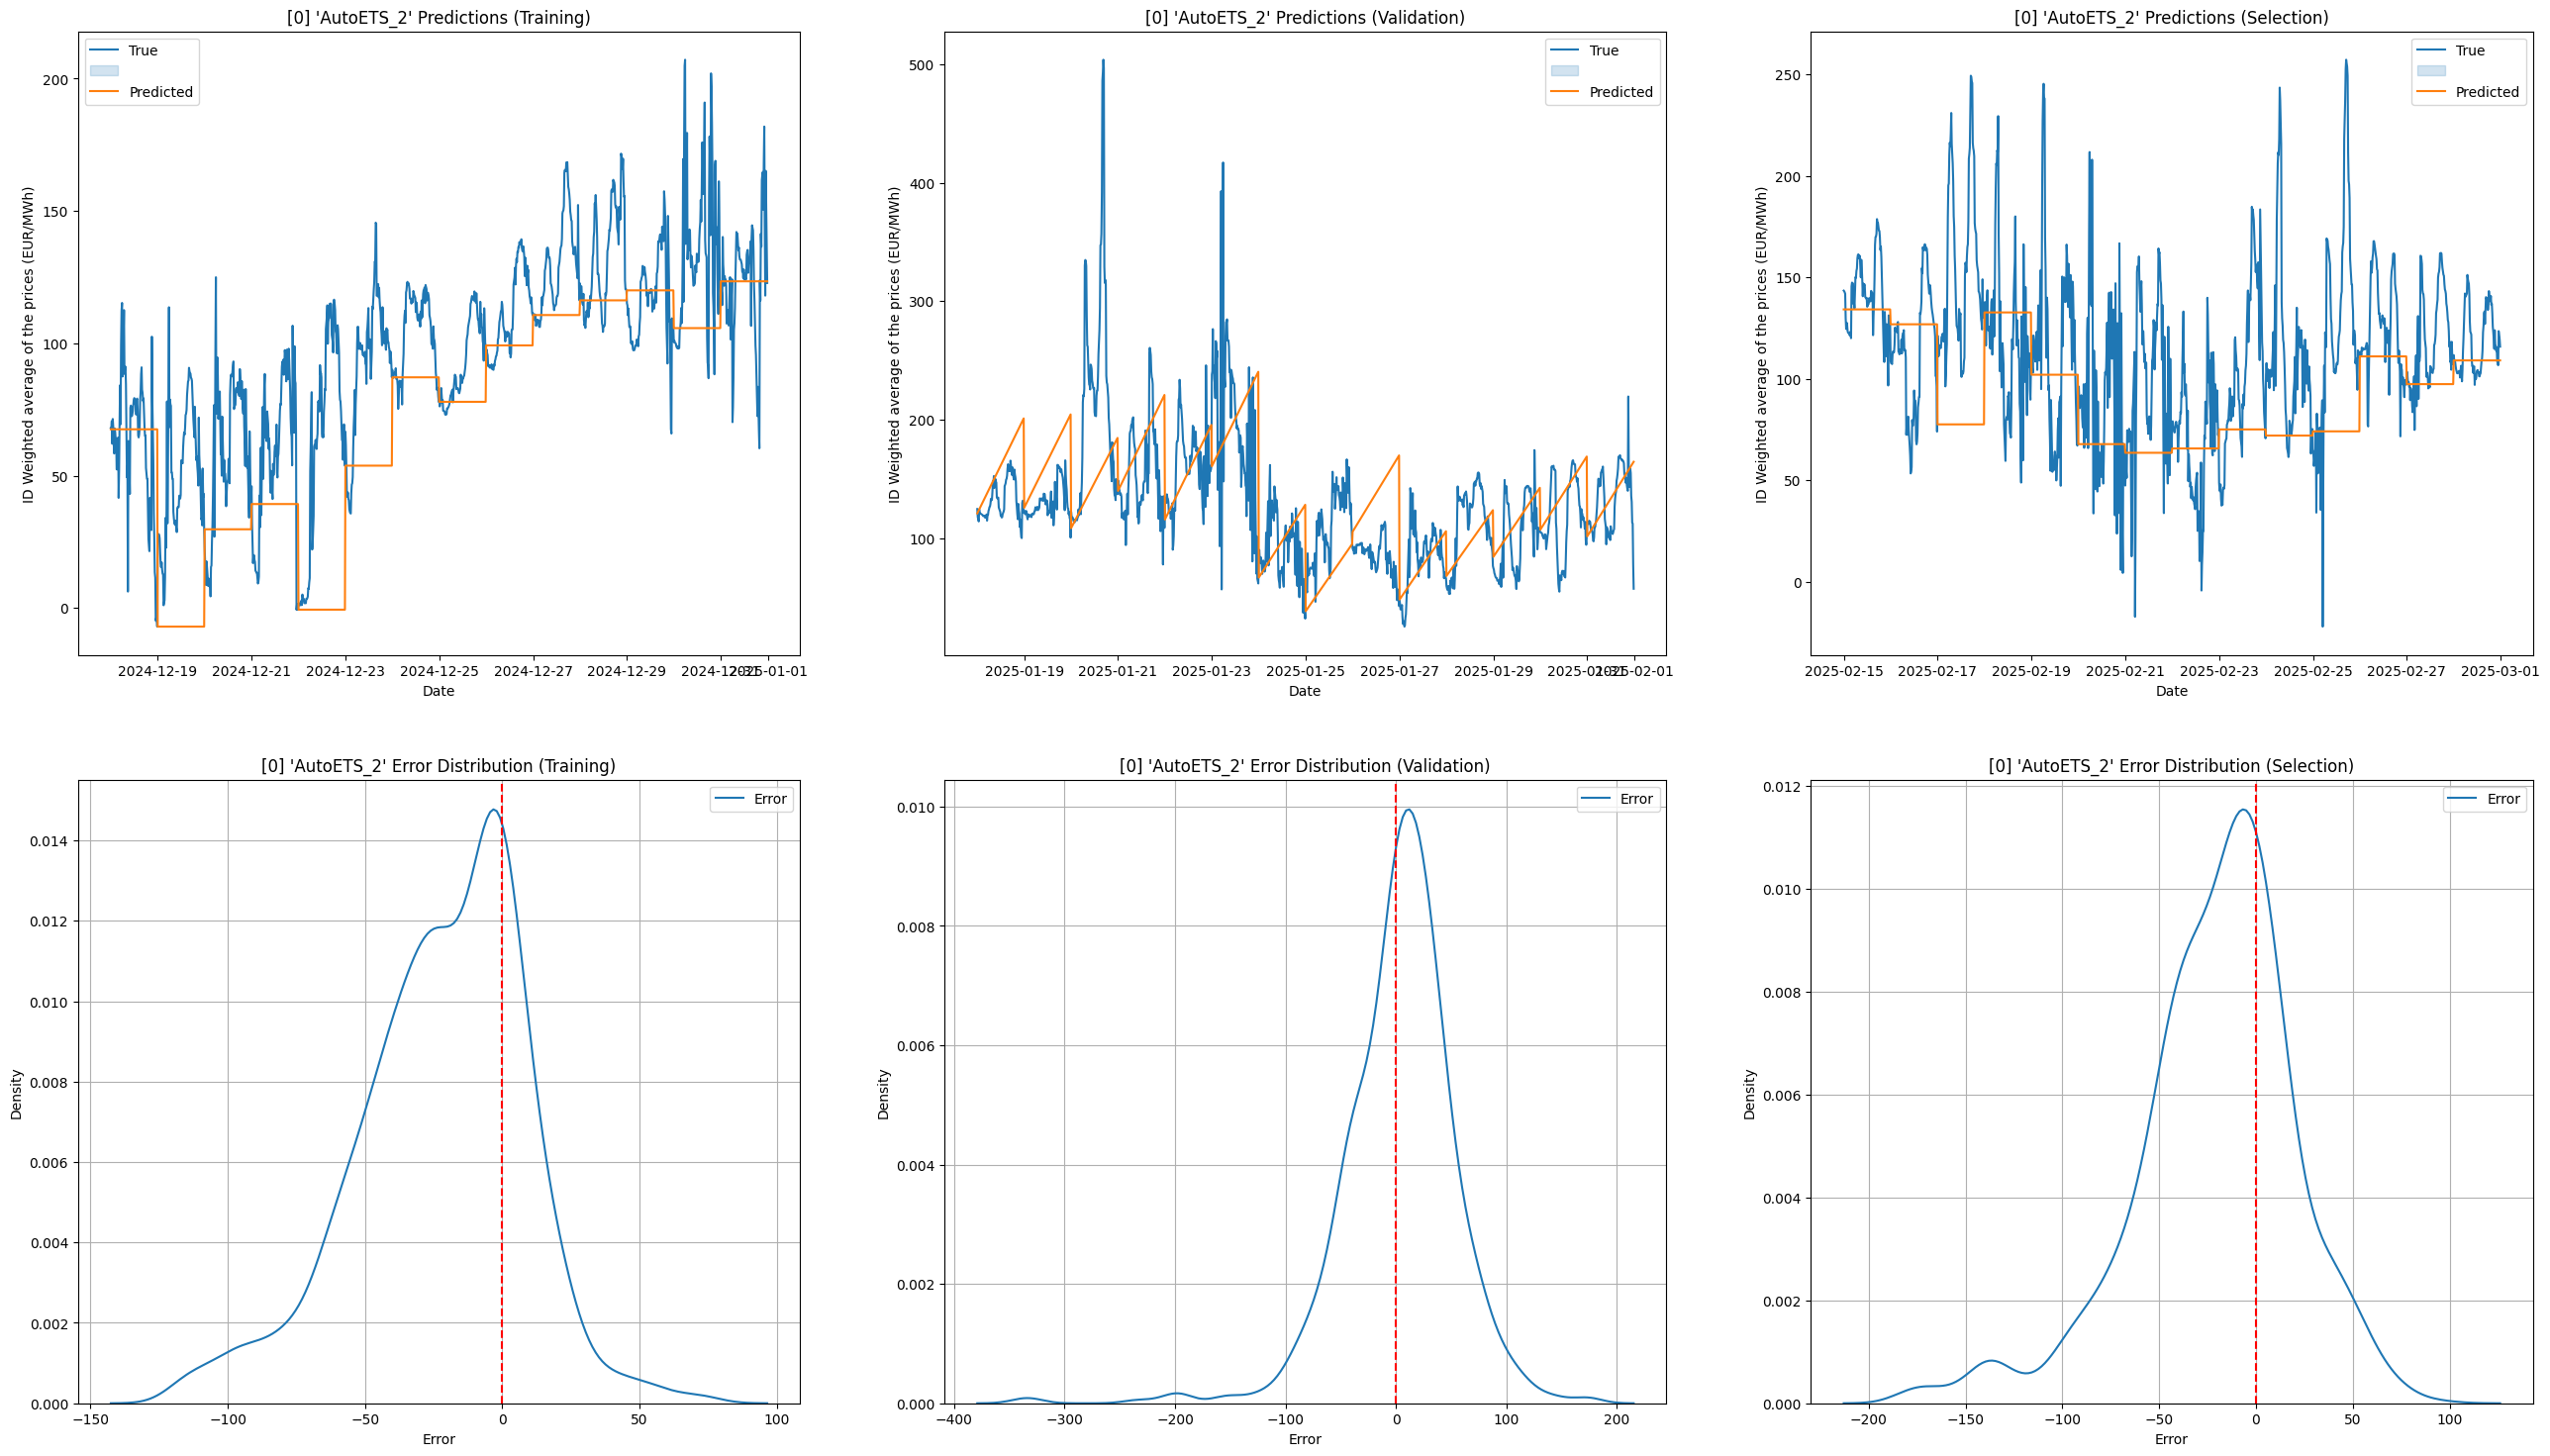

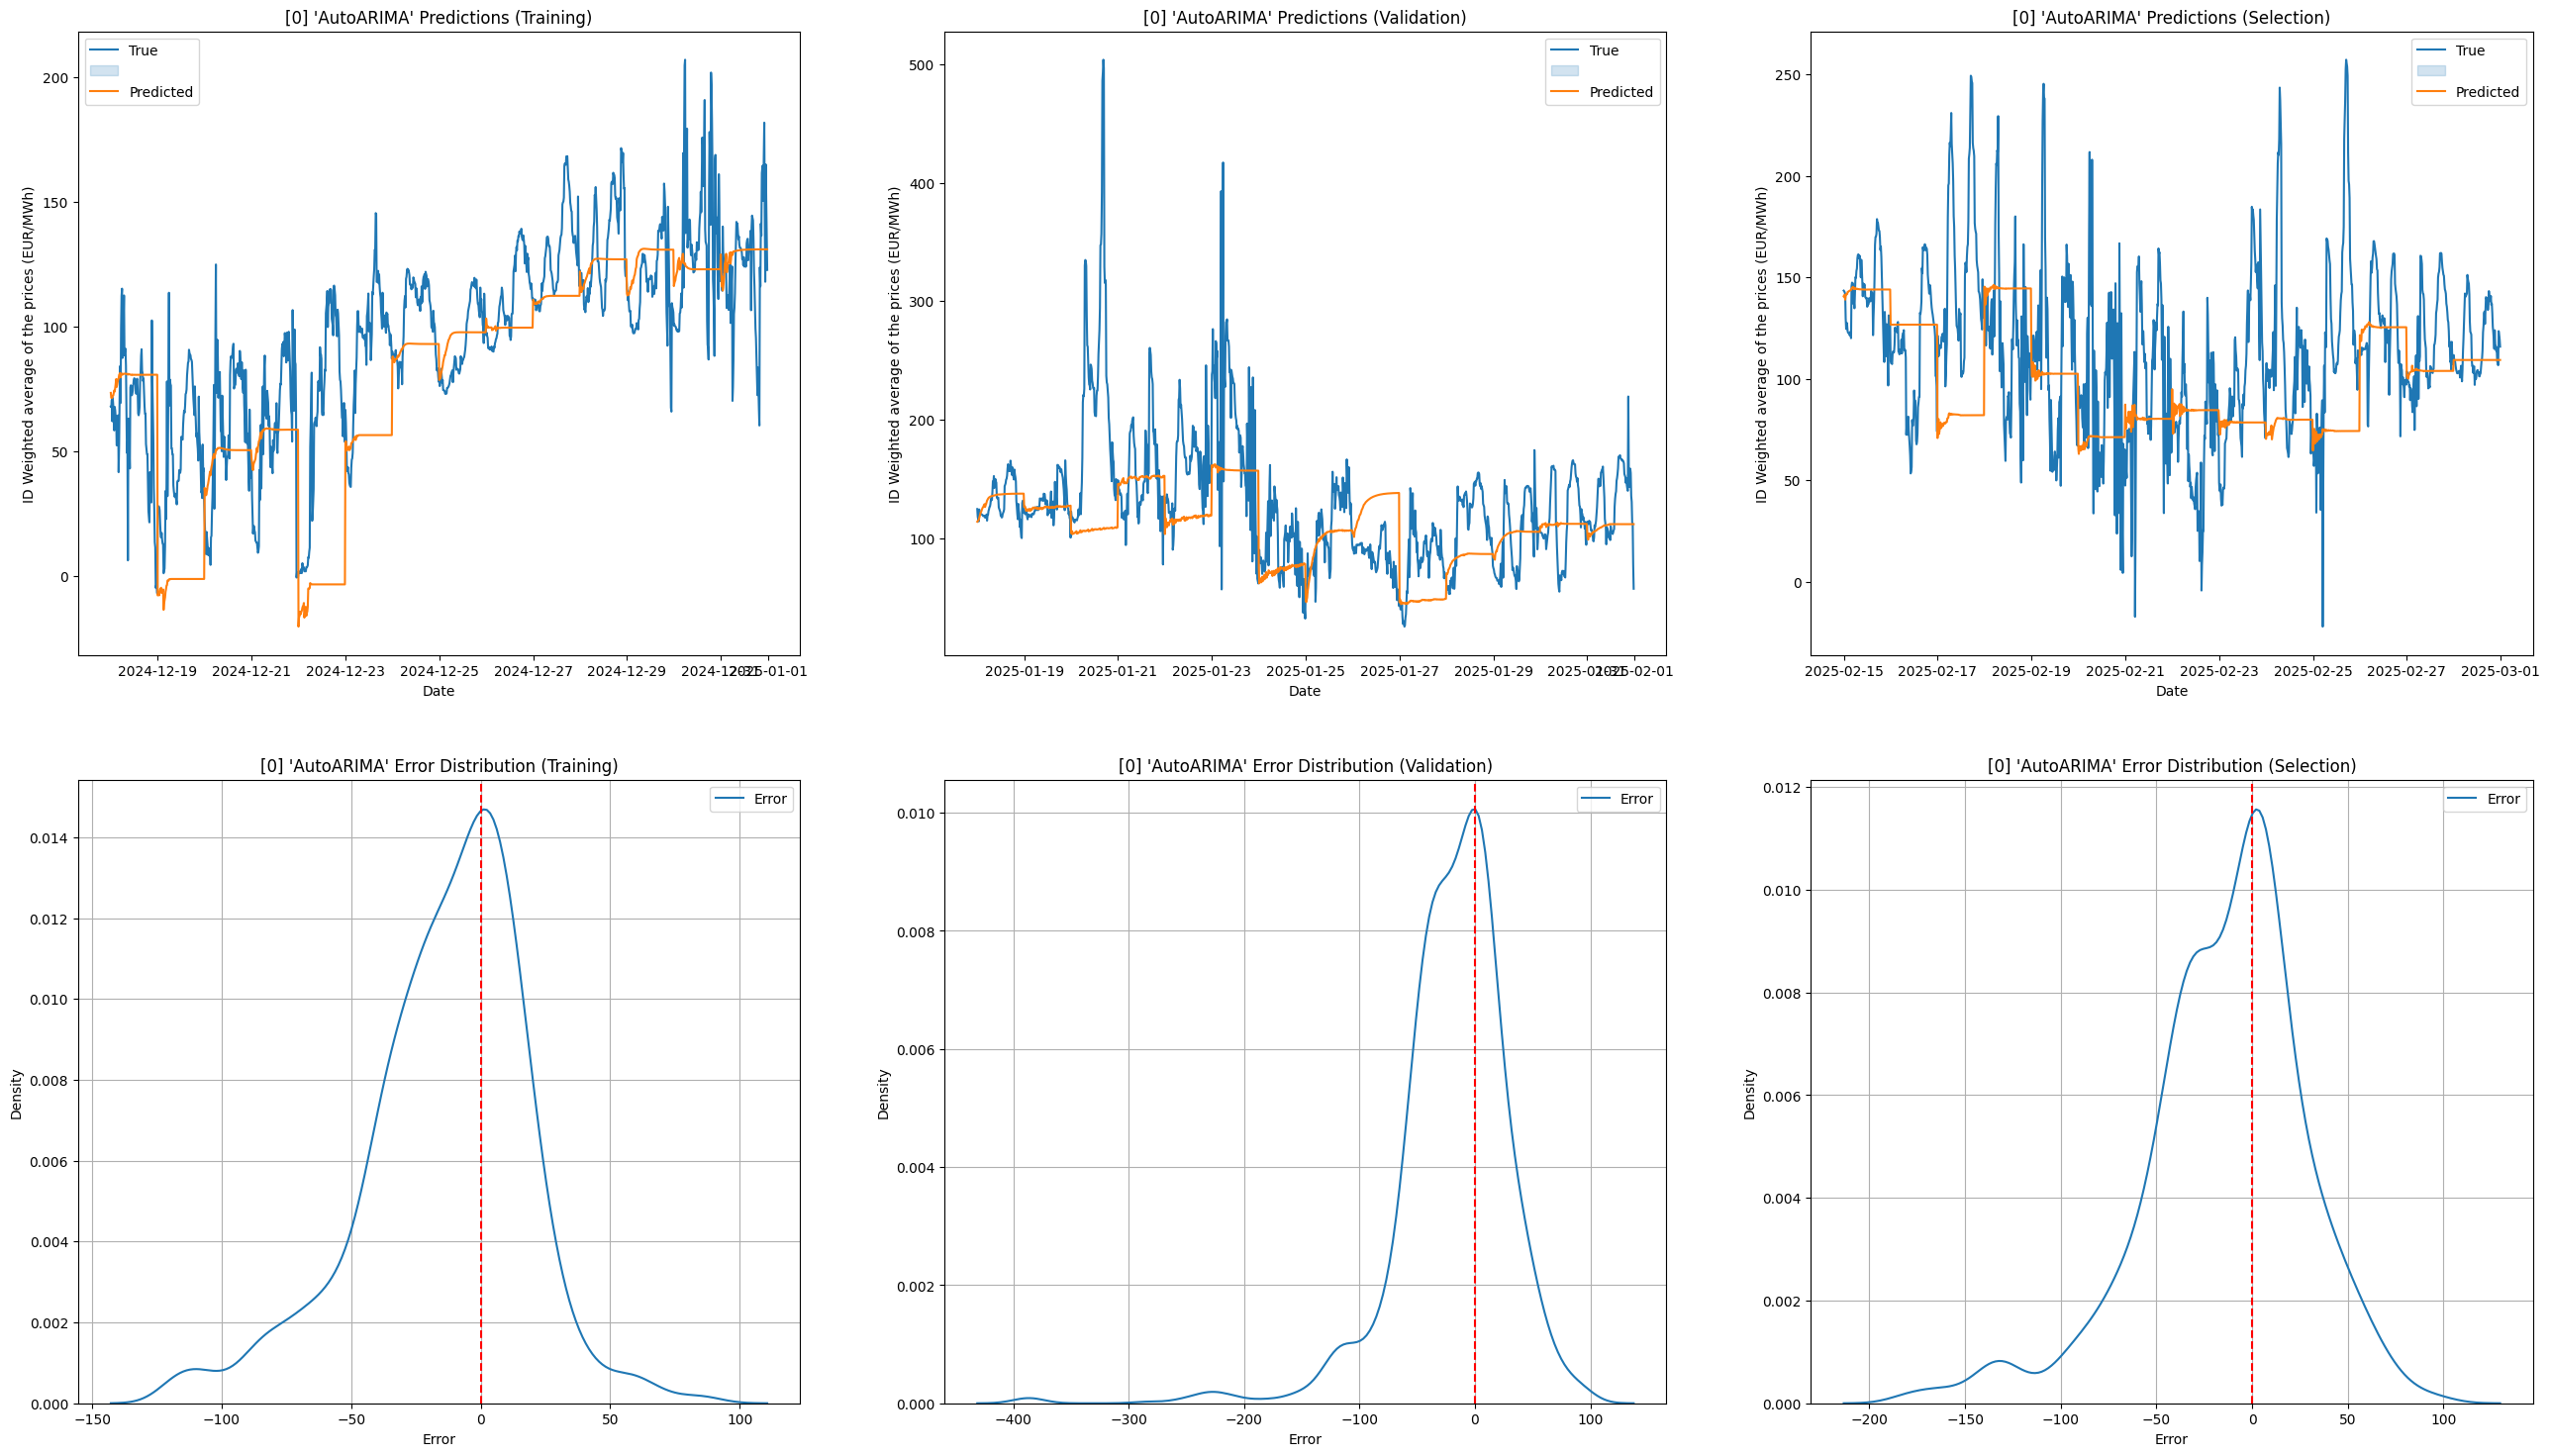

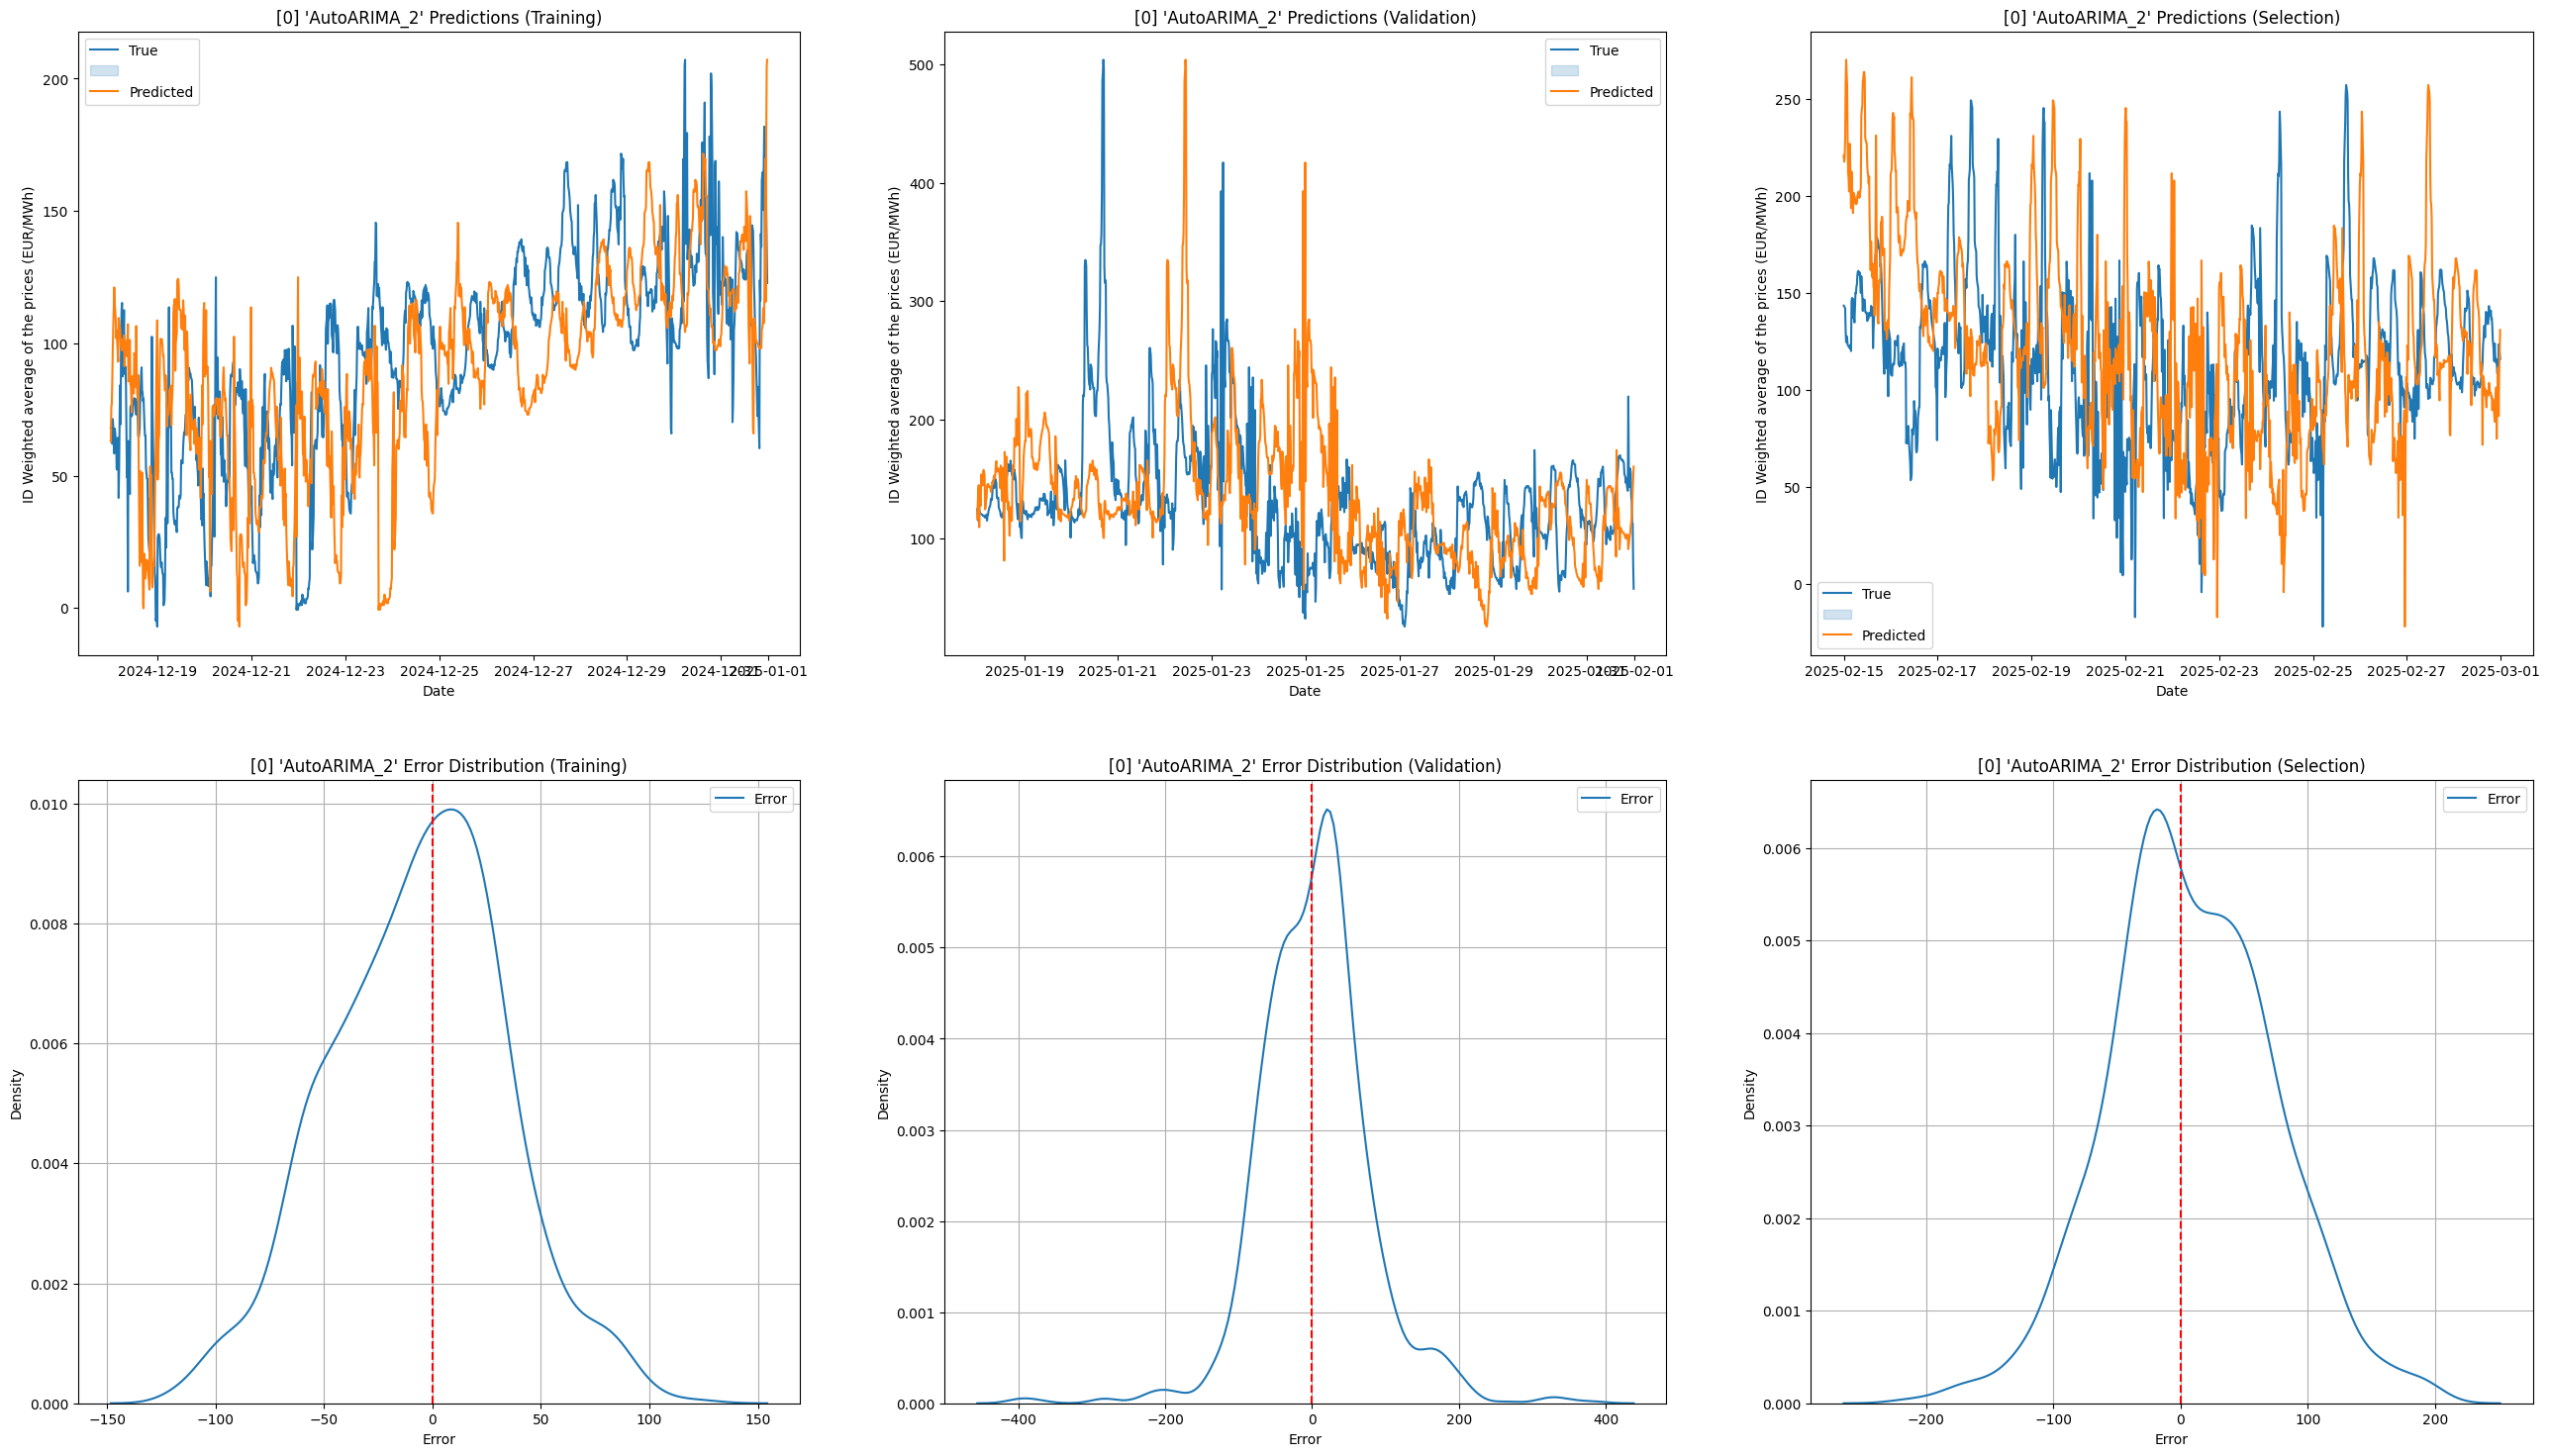

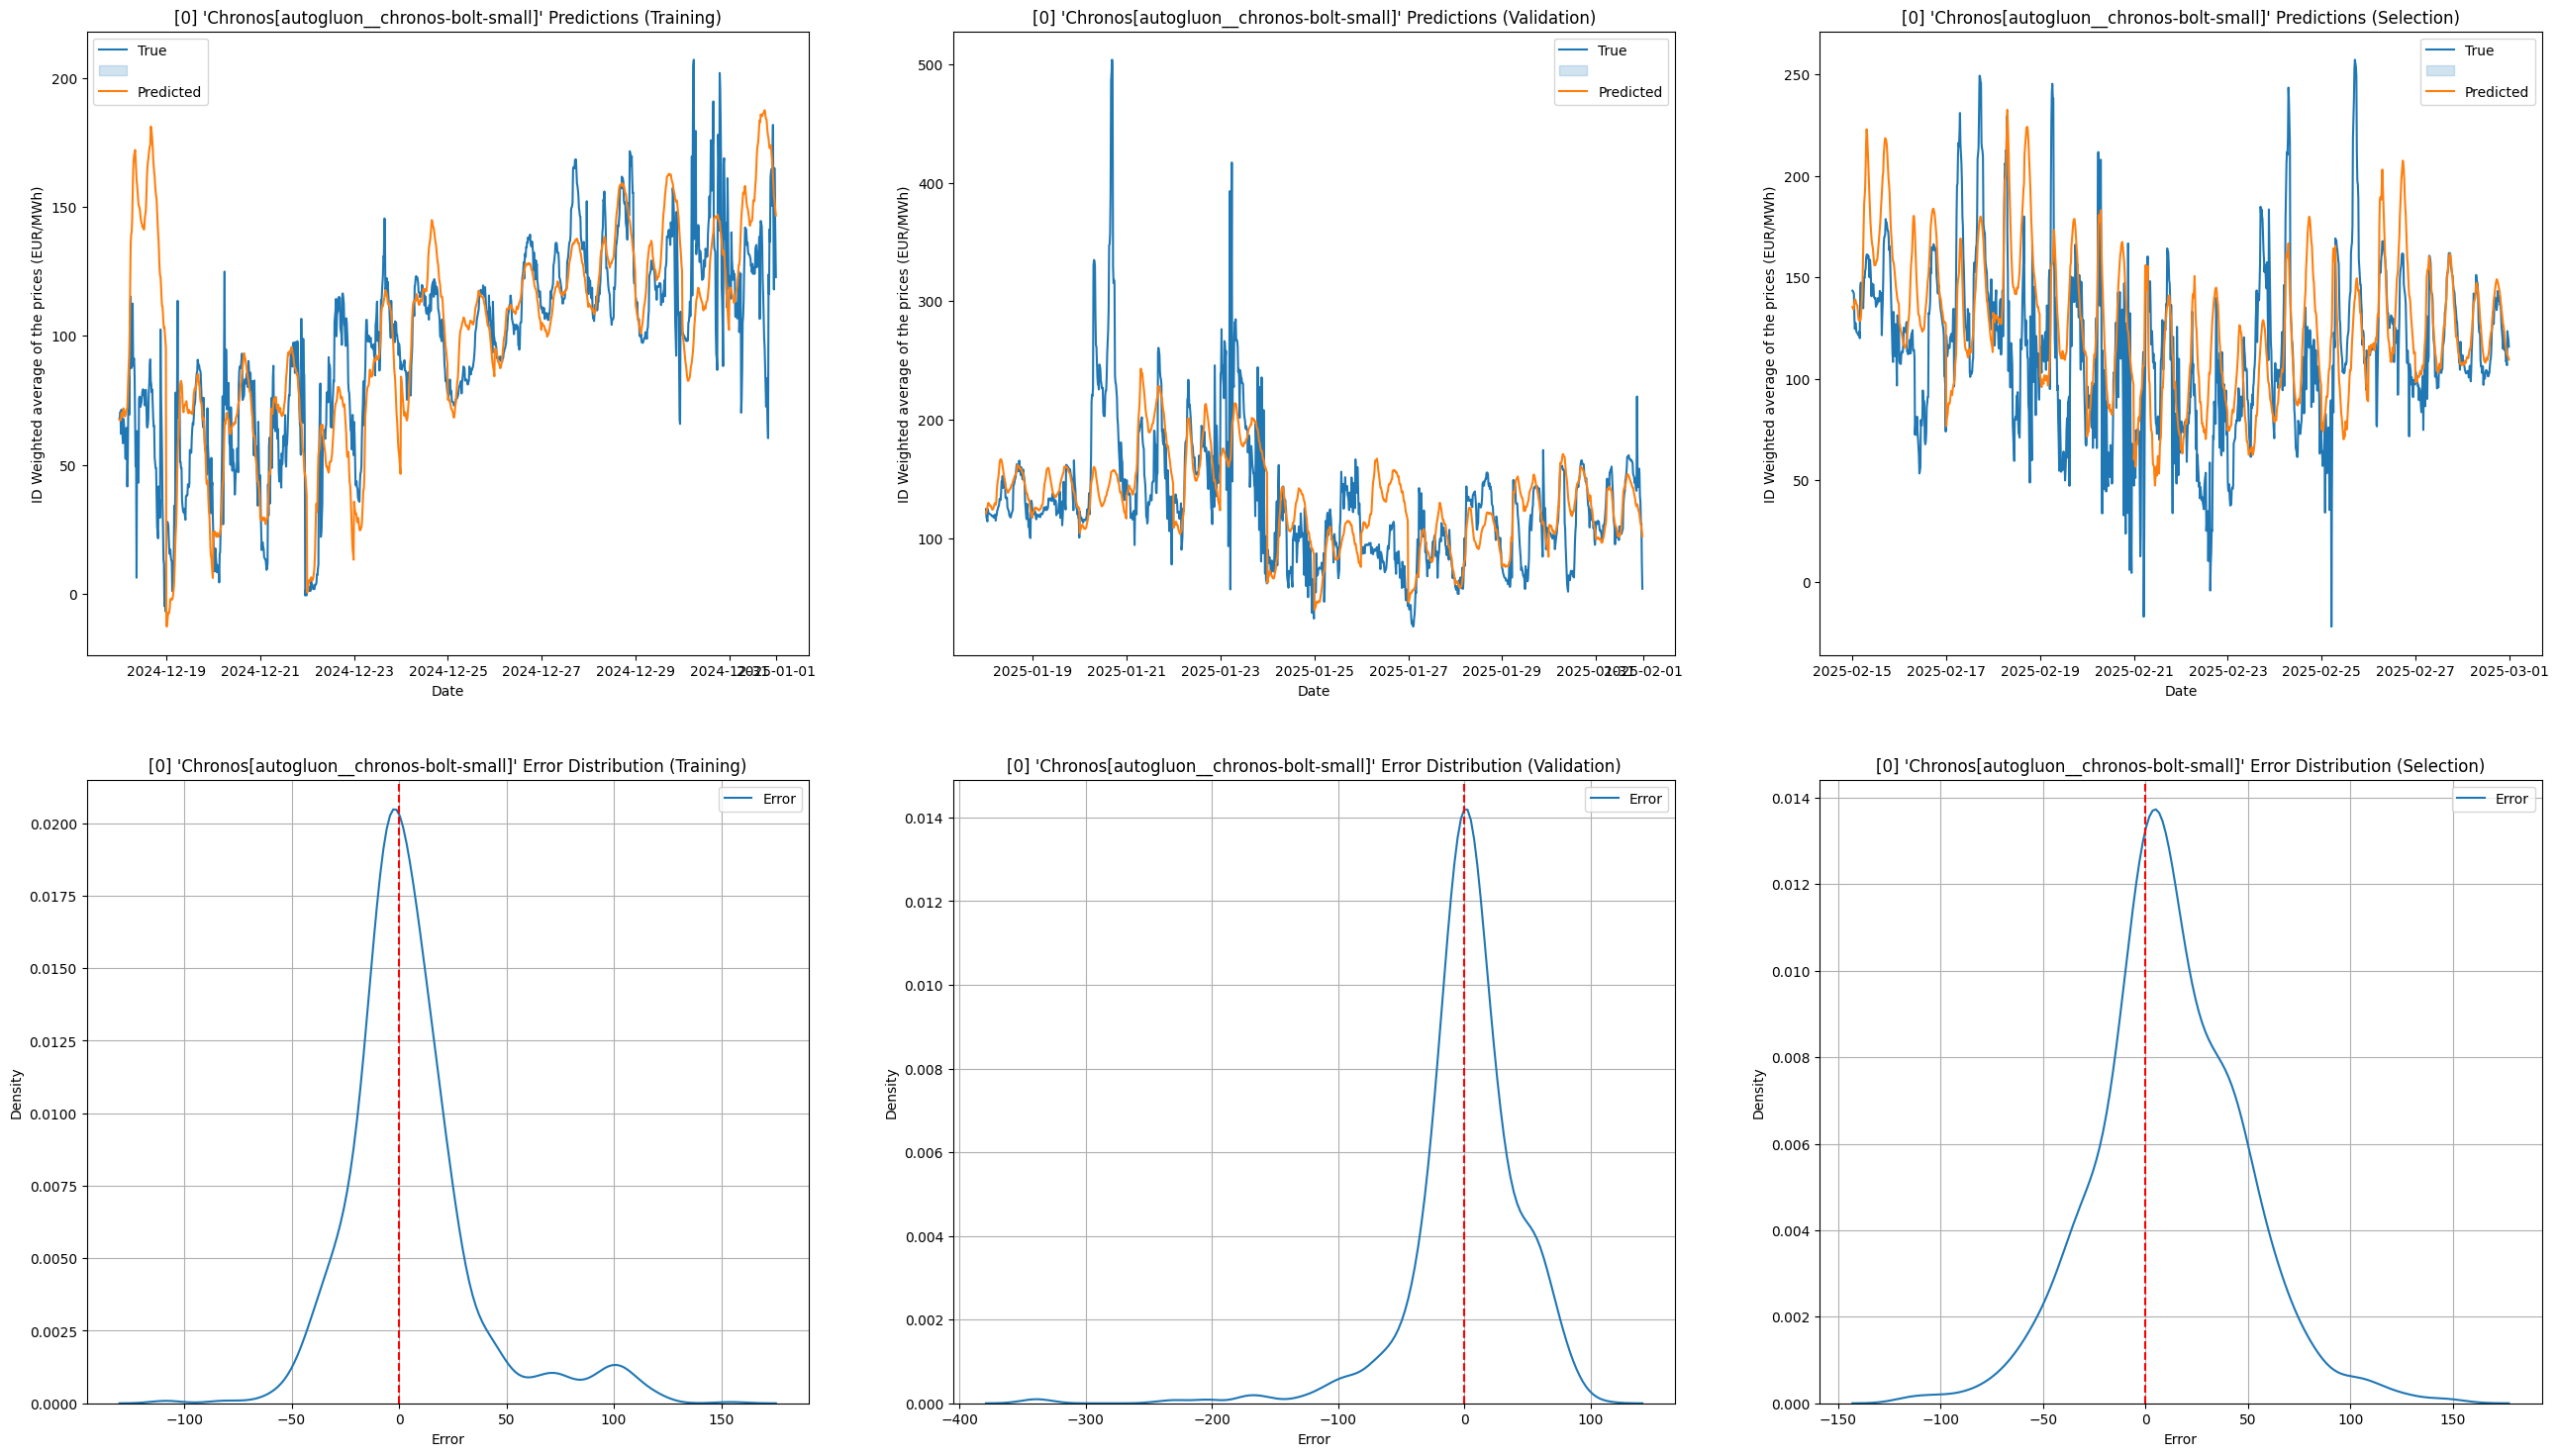

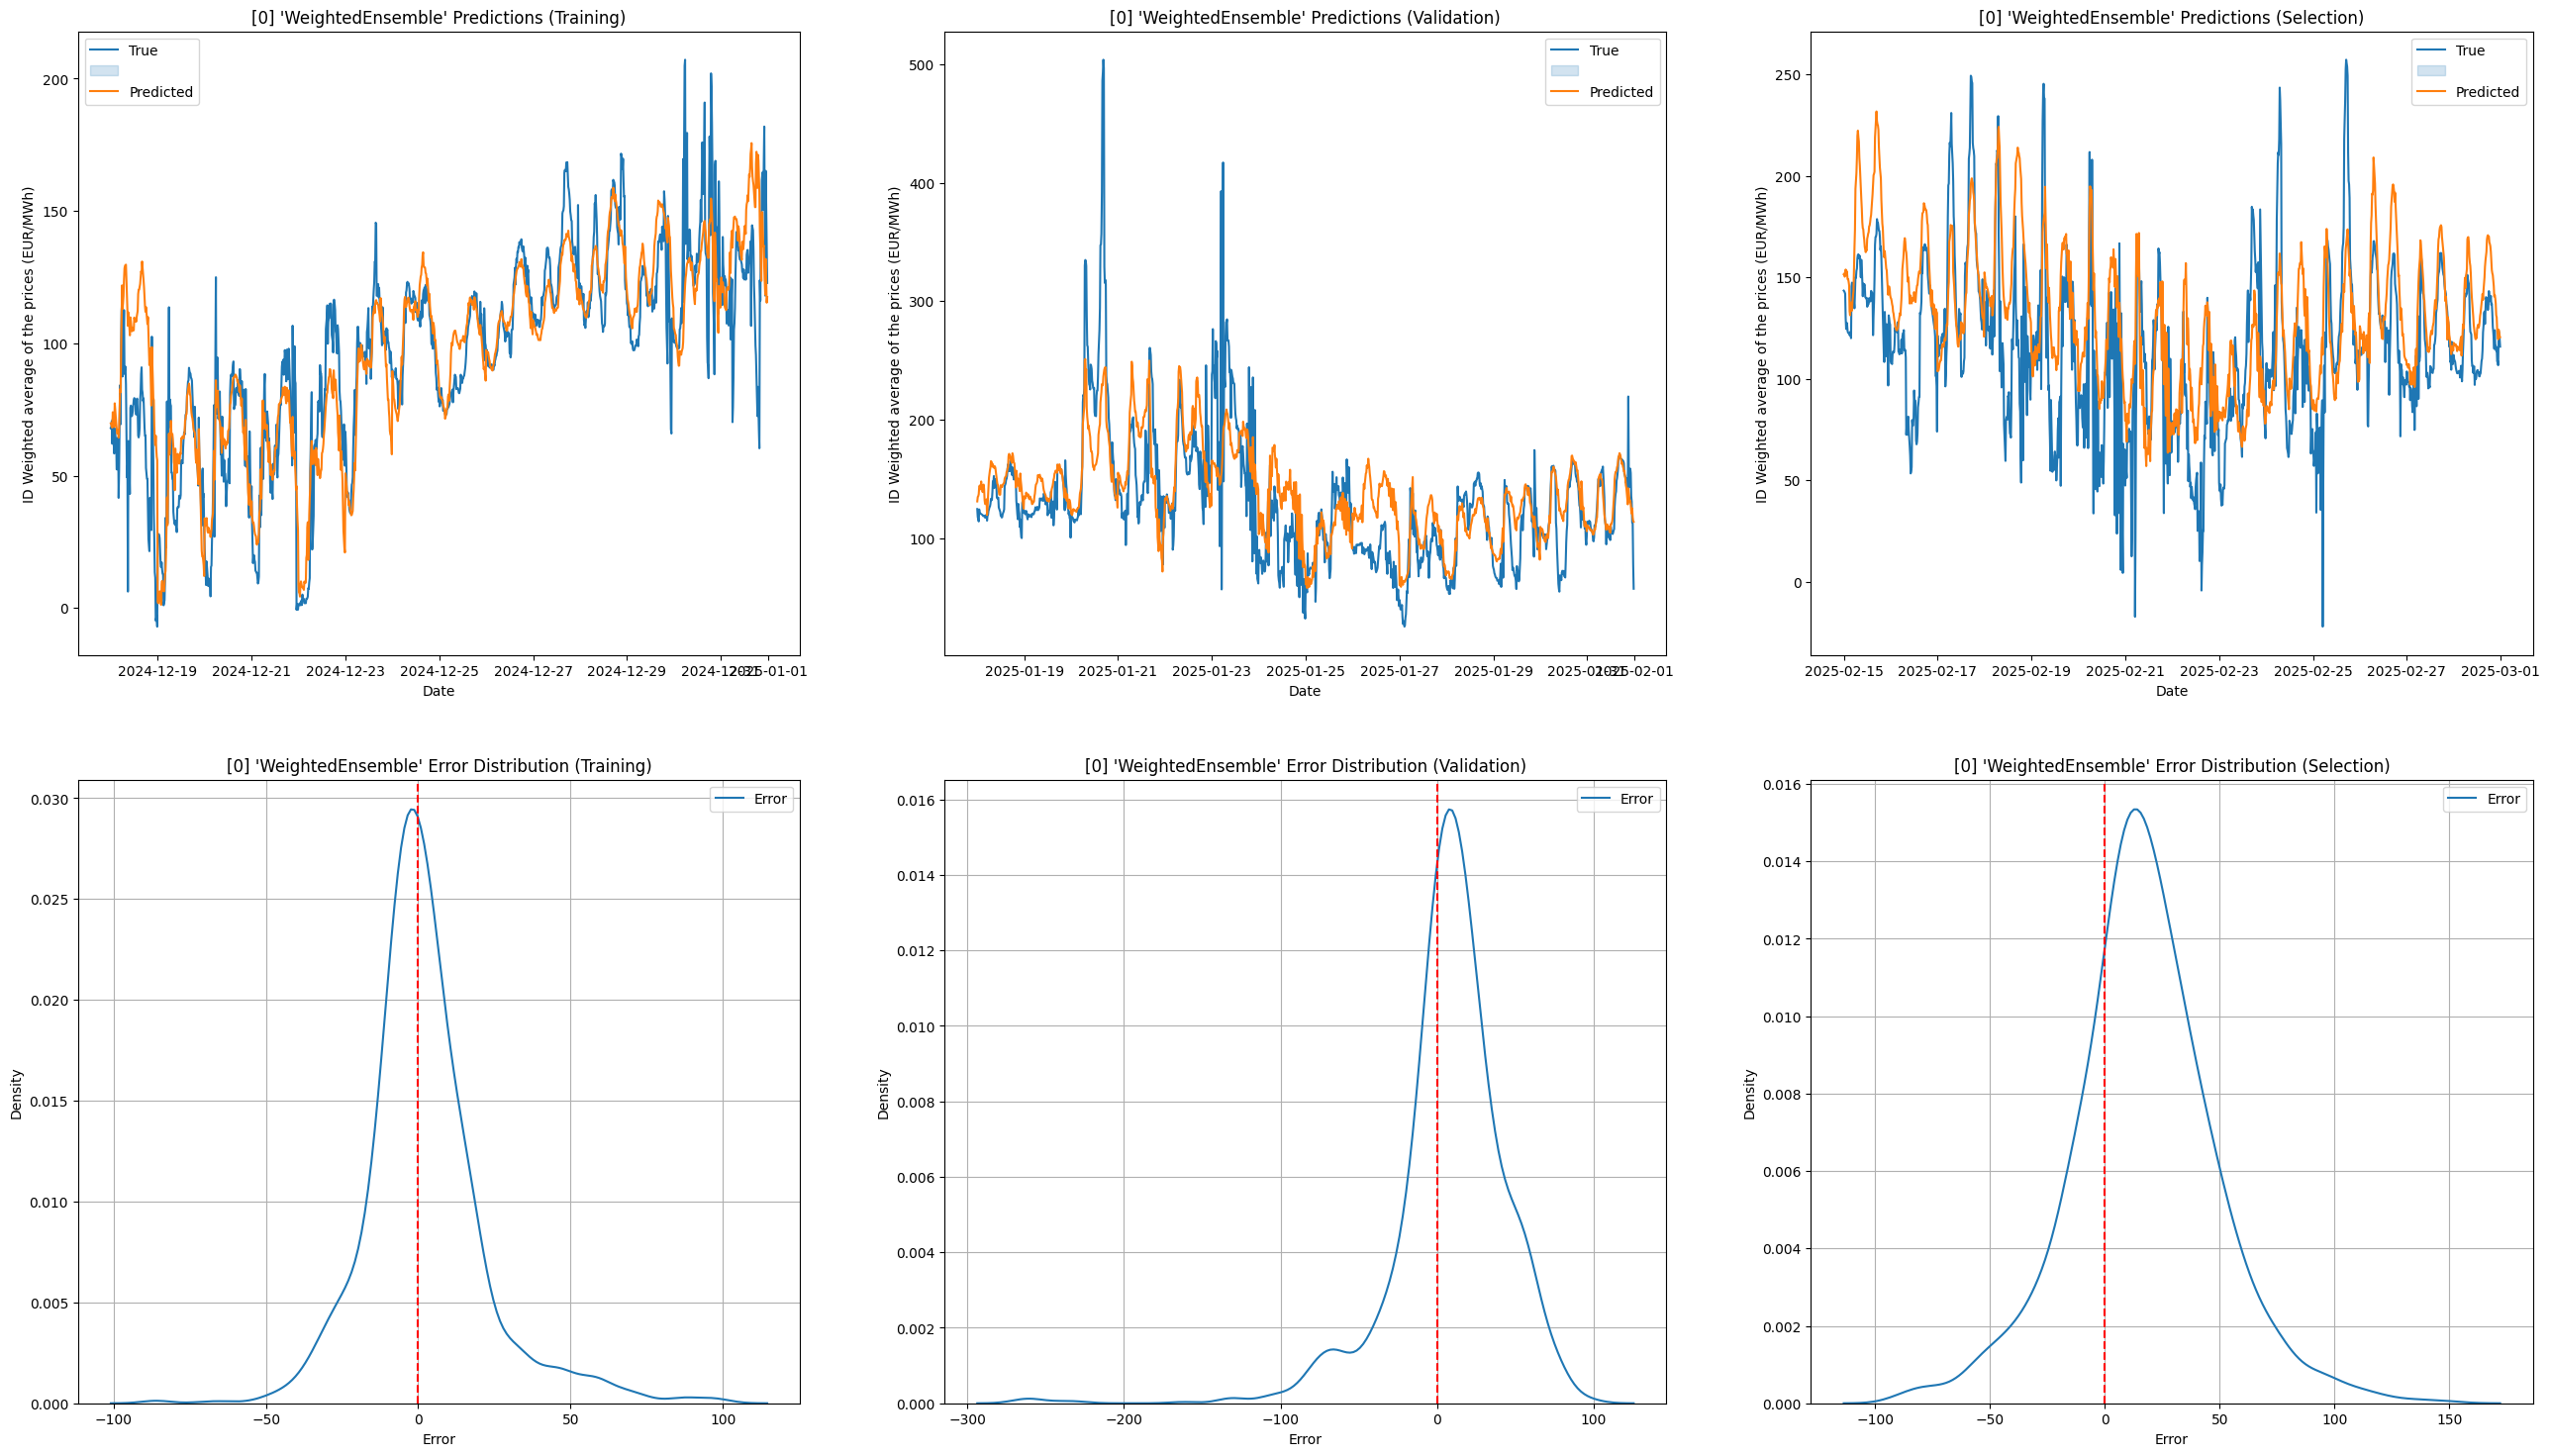

In [5]:
ts_mae_model = train_intra_day_time_series(ts_train, ts_val, "MAE", cache="MAE")
display(evaluate_timeseries_model(ts_mae_model, ts_train, ts_val, ts_select, eval_metrics))

2025-05-06 17:27:10,969 - INFO - Loading model from /Users/pavelholman/FIT/bp/models/intra_day/tabular/MAE
This means that the predictor was fit in an AutoGluon version `<=0.3.1`.
2025-05-06 17:27:10,971 - INFO - Model not found, training a new model
Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.2
Python Version:     3.12.6
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 24.4.0: Fri Apr 11 18:32:43 PDT 2025; root:xnu-11417.101.15~117/RELEASE_ARM64_T8103
CPU Count:          8
Memory Avail:       3.95 GB / 16.00 GB (24.7%)
Disk Space Avail:   68.66 GB / 460.43 GB (14.9%)
No presets specified! To achieve strong results with AutoGluon, it is recommended to use the available presets. Defaulting to `'medium'`...
	Recommended Presets (For more details refer to https://auto.gluon.ai/stable/tutorials/tabular/tabular-essentials.html#presets):
	presets='experimental' : New in v1.2: Pre-train

,model,mean_absolute_error [Training],mean_absolute_error [Validation],mean_absolute_error [Selection],mean_absolute_percentage_error [Training],mean_absolute_percentage_error [Validation],mean_absolute_percentage_error [Selection],root_mean_squared_error [Training],root_mean_squared_error [Validation],root_mean_squared_error [Selection],weighted_mae [Training],weighted_mae [Validation],weighted_mae [Selection],directional_accuracy [Training],directional_accuracy [Validation],directional_accuracy [Selection],peak_detection [Training],peak_detection [Validation],peak_detection [Selection],cost_simulation [Training],cost_simulation [Validation],cost_simulation [Selection]
0,KNeighbors,-4.500993,-36.615040,-30.608582,-0.119635,-0.304815,-0.405594,-7.937136,-55.114730,-46.176161,-4.524070,-44.216353,-32.153310,0.667908,0.553984,0.589724,0.971726,0.882440,0.897321,-0.000382,-0.056669,-0.132680
1,RandomForest,-1.990490,-23.376072,-19.973968,-0.091360,-0.190925,-0.310863,-3.402537,-37.684199,-28.341055,-1.914475,-29.118067,-18.054588,0.881608,0.625465,0.615786,0.988095,0.901786,0.941964,-0.002426,-0.020801,-0.080371
2,CatBoost,-10.185058,-20.654386,-20.342700,-0.509089,-0.166122,-0.307903,-14.216076,-34.022585,-28.282804,-10.017609,-25.914369,-18.372528,0.612807,0.620998,0.649293,0.925595,0.909226,0.919643,-0.000940,-0.009056,-0.088812
3,XGBoost,-12.551380,-26.169303,-19.231826,-0.776235,-0.203238,-0.295165,-17.556577,-56.074202,-27.235036,-11.782518,-35.977954,-17.974569,0.625465,0.620998,0.616530,0.916667,0.904762,0.940476,-0.013525,-0.025042,-0.047265
4,WeightedEnsemble_L2,-8.725147,-20.787986,-19.965825,-0.434014,-0.168619,-0.306613,-12.272096,-34.118051,-27.963763,-8.579351,-26.045811,-17.920216,0.693969,0.634401,0.661206,0.931548,0.904762,0.930060,-0.001110,-0.012658,-0.089618


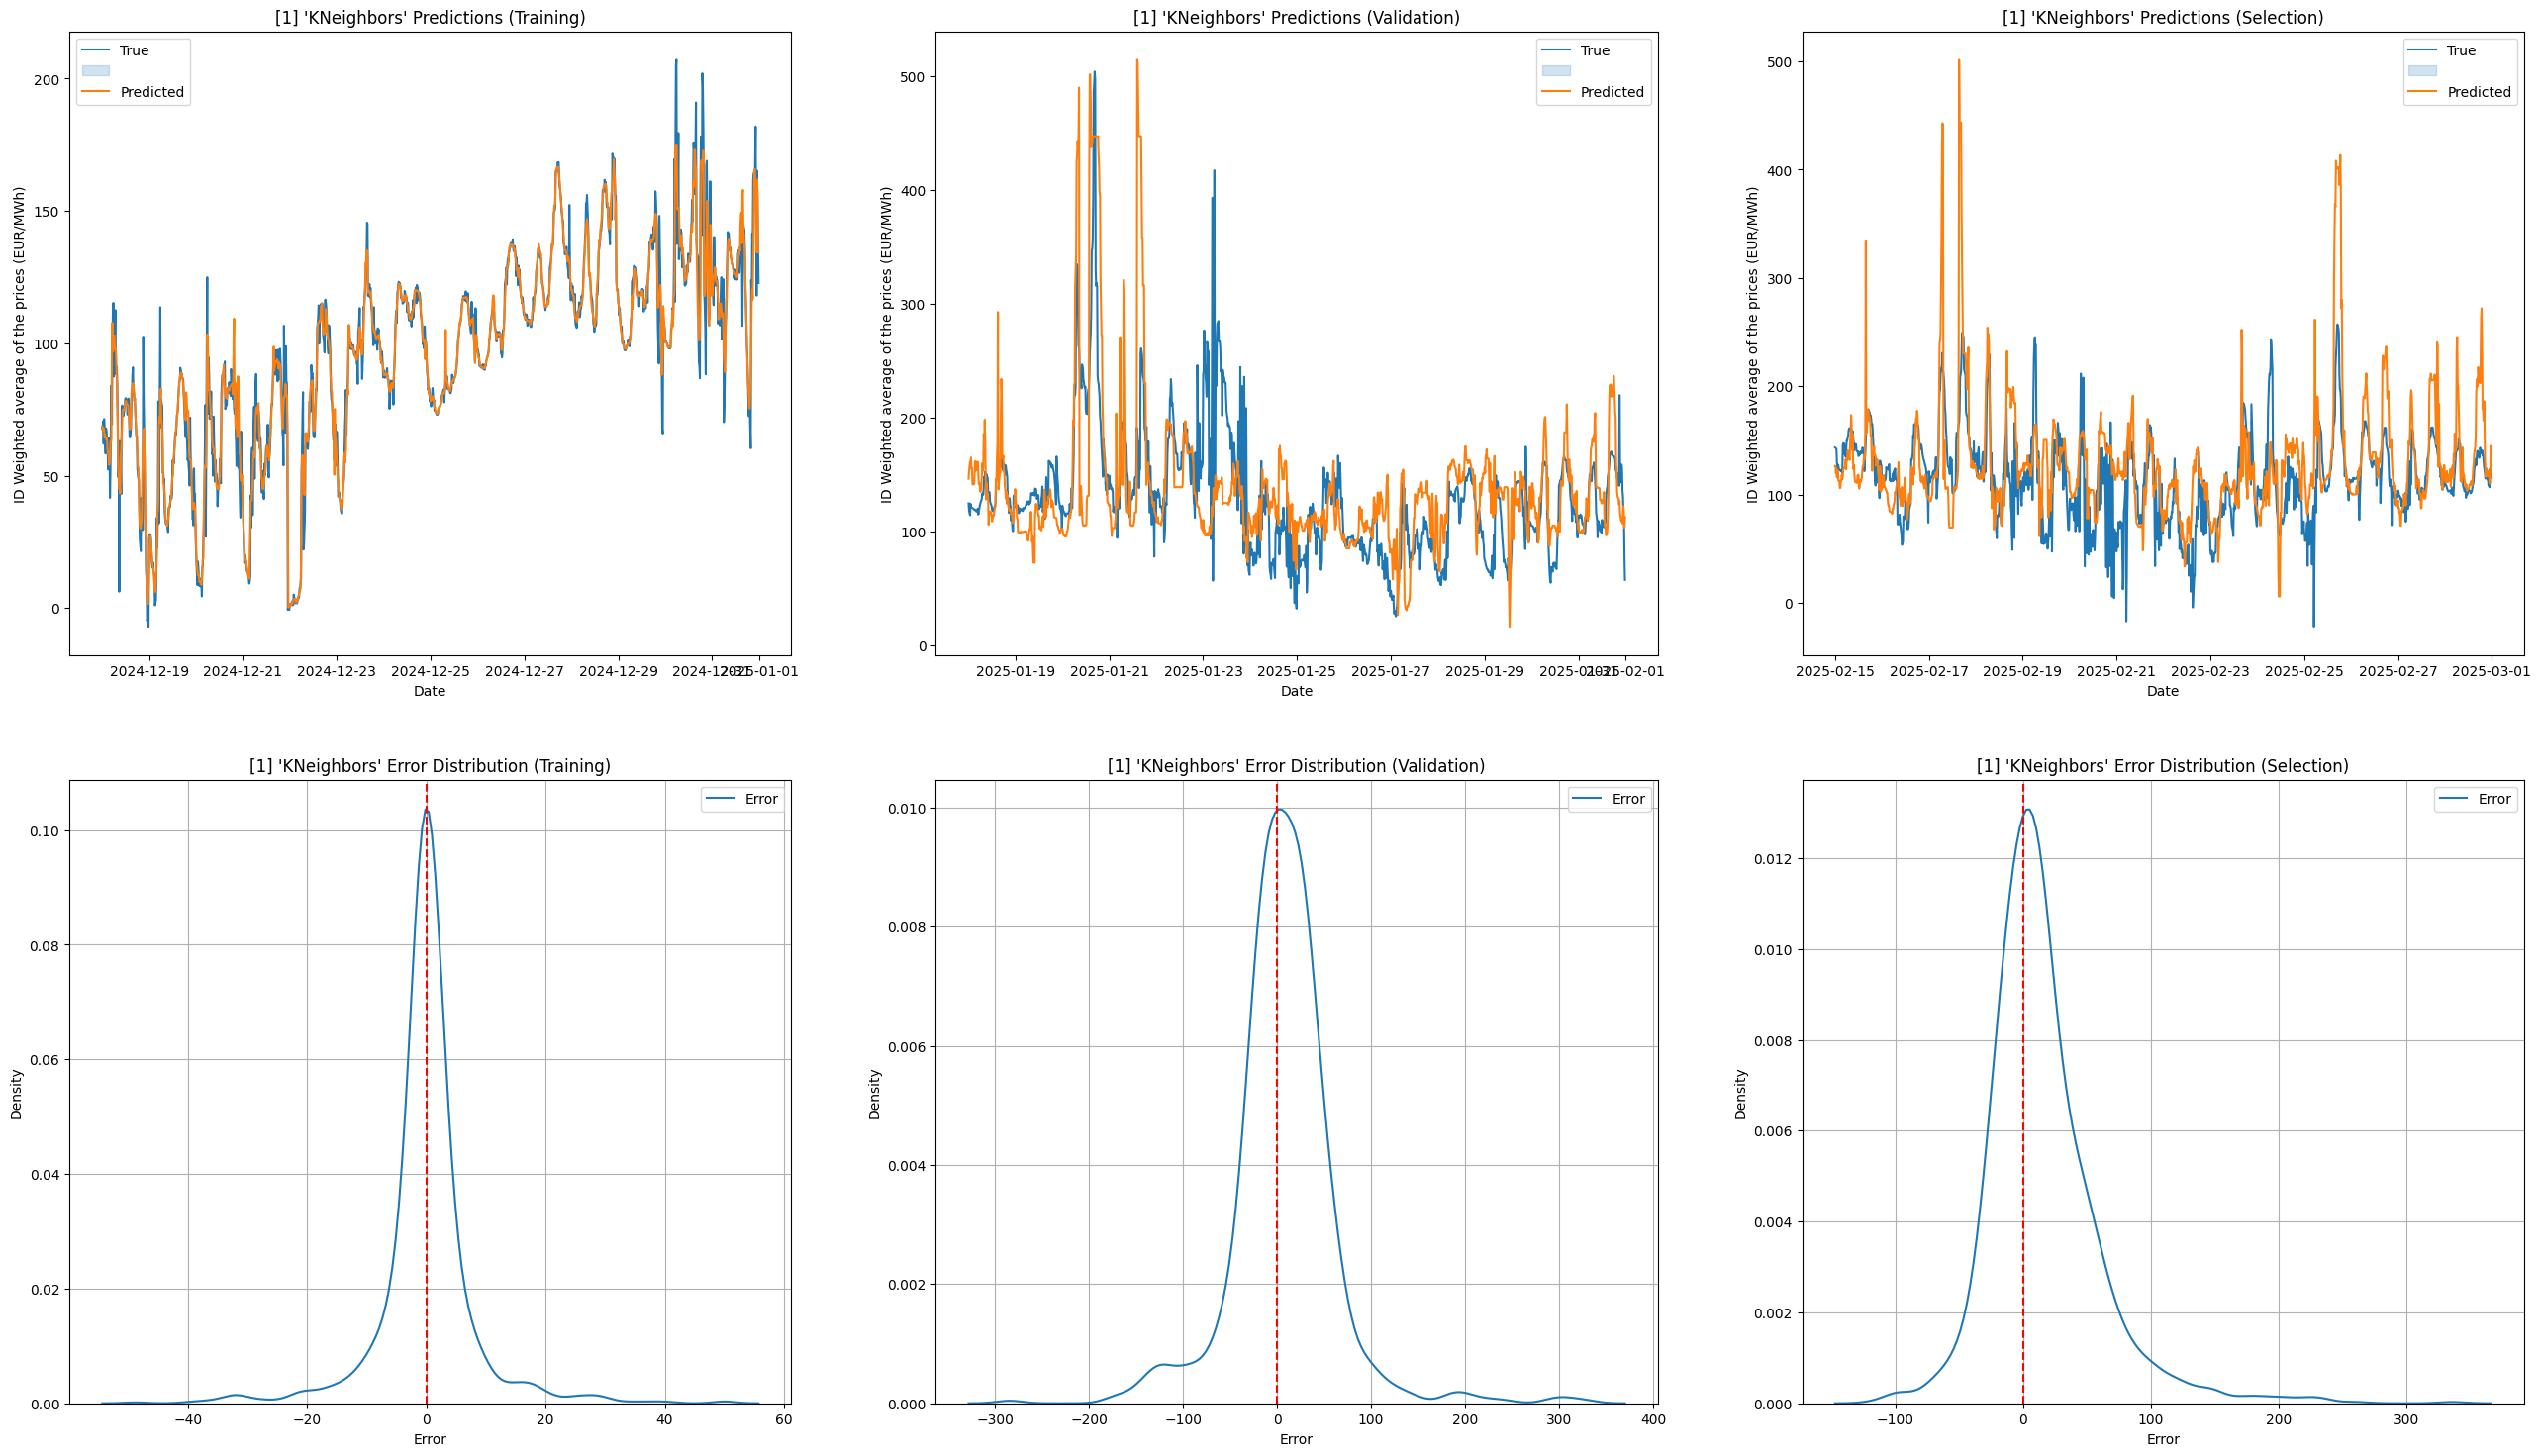

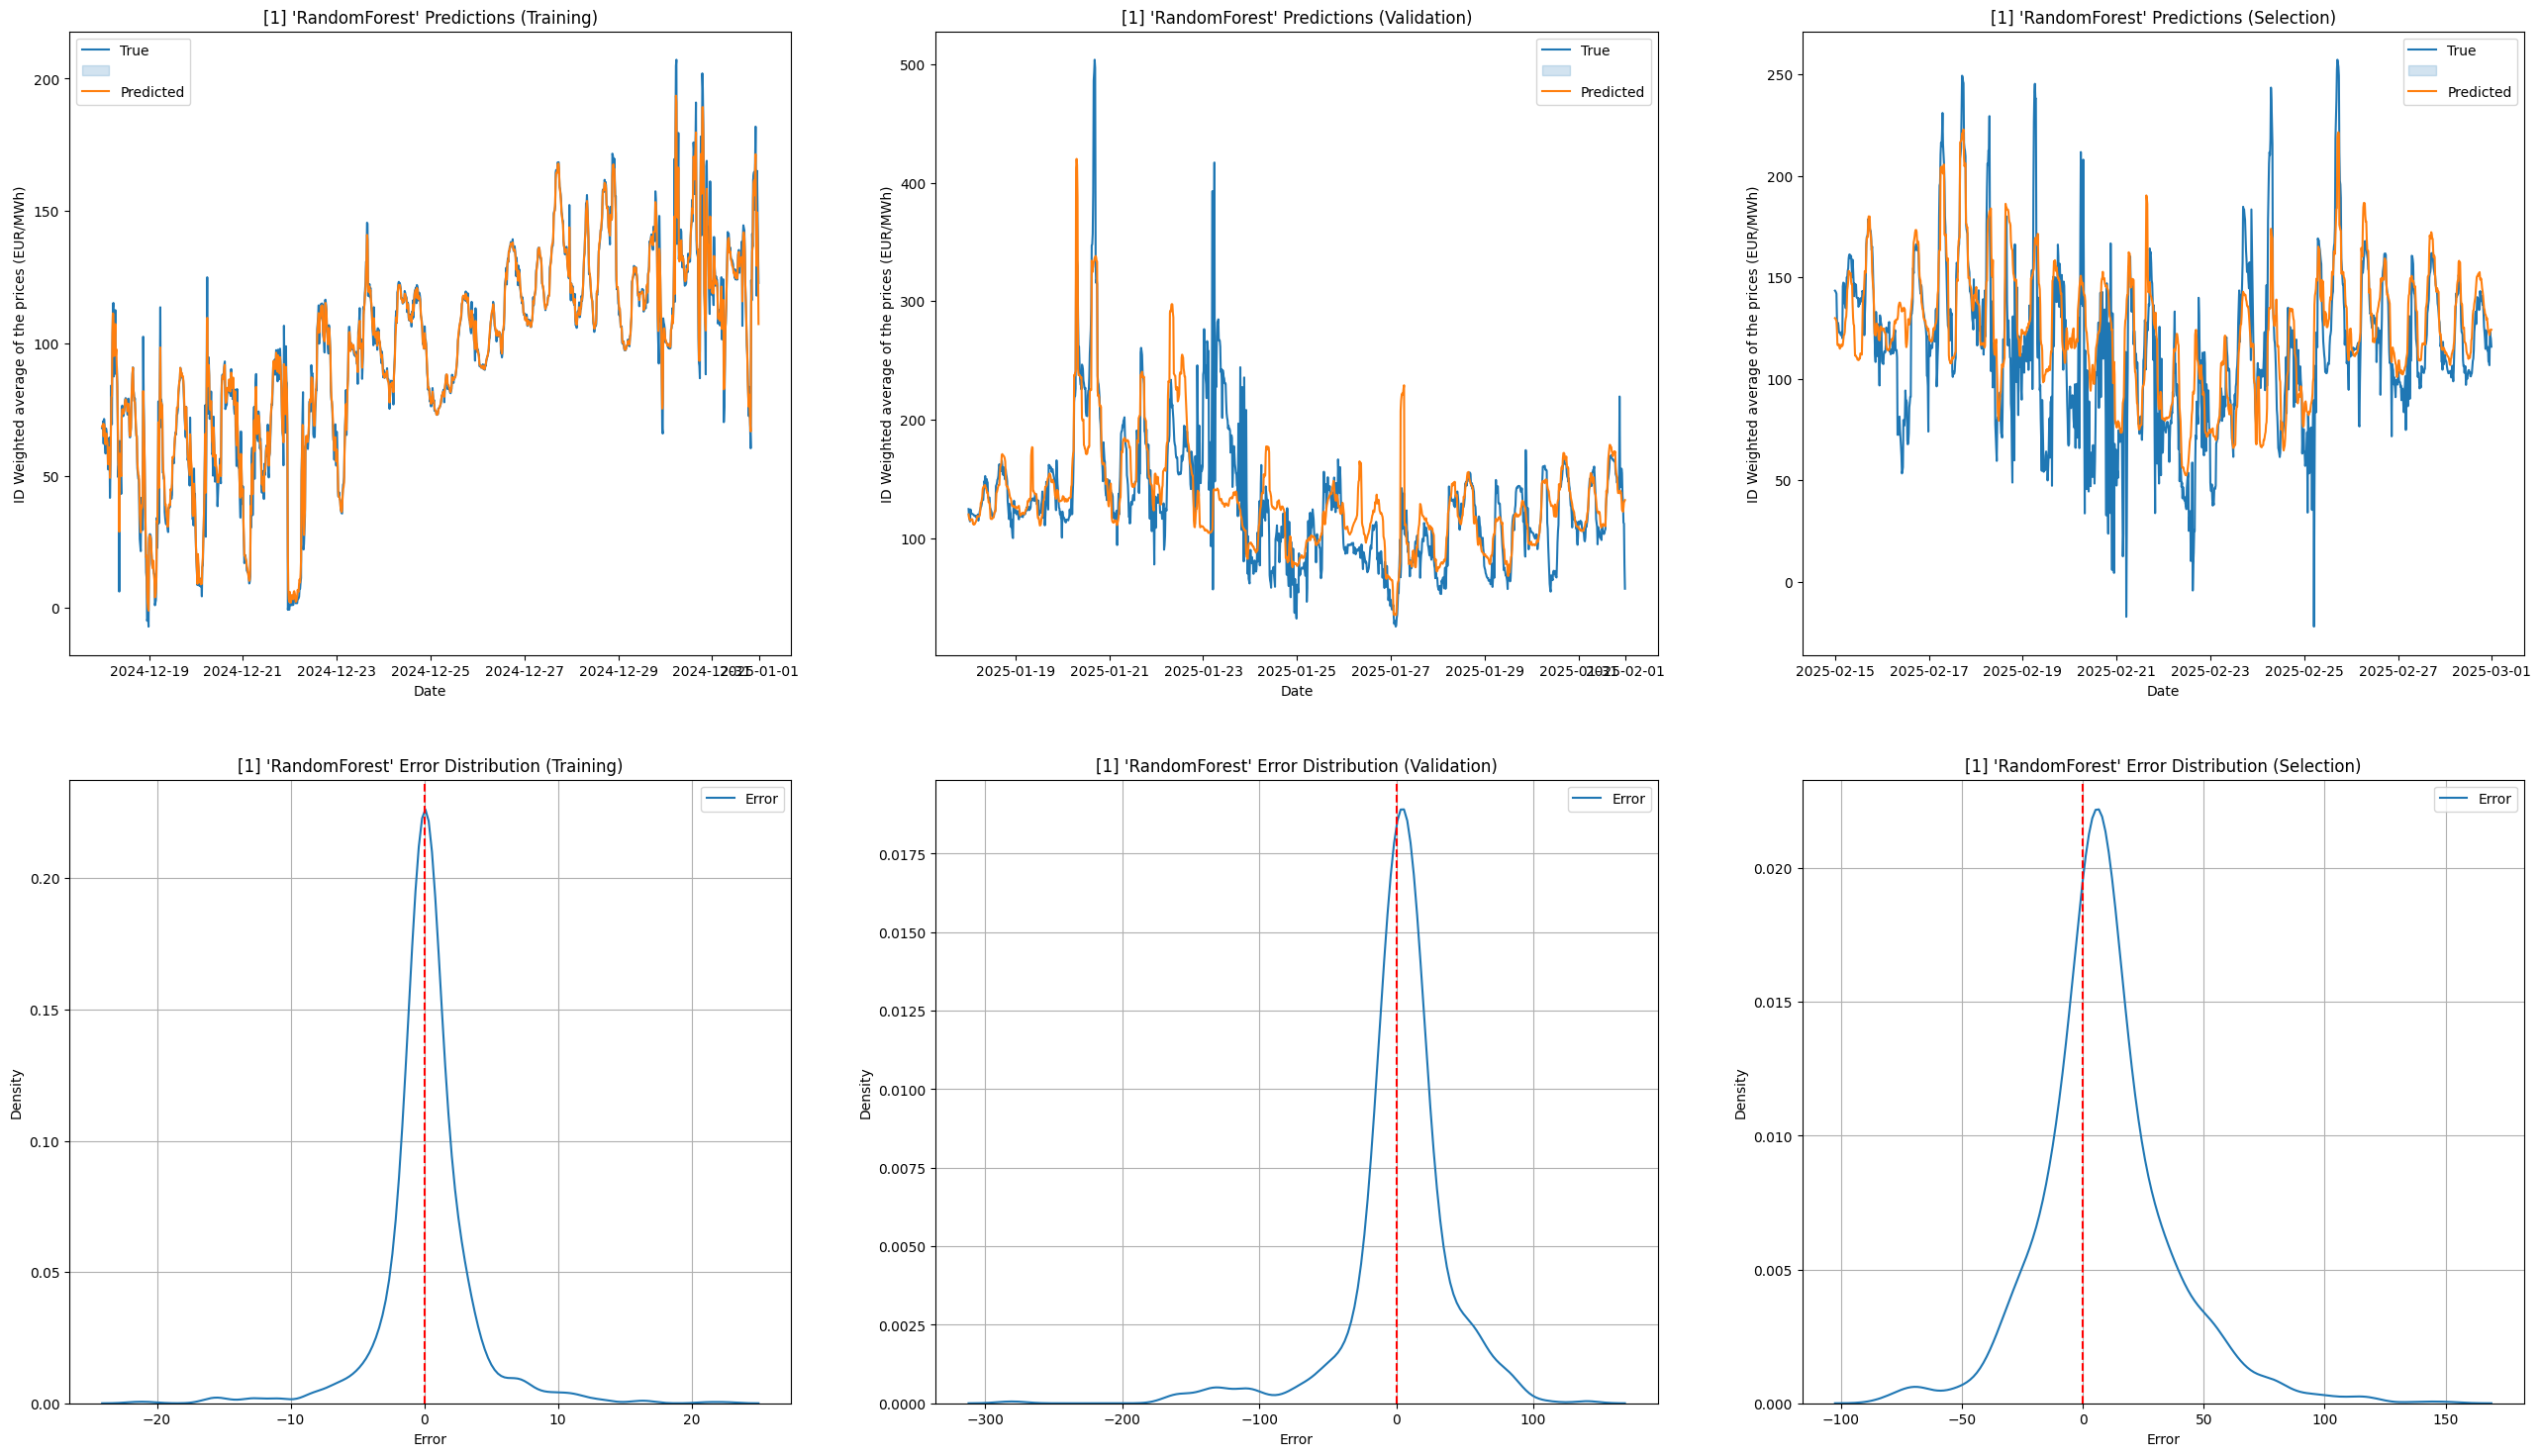

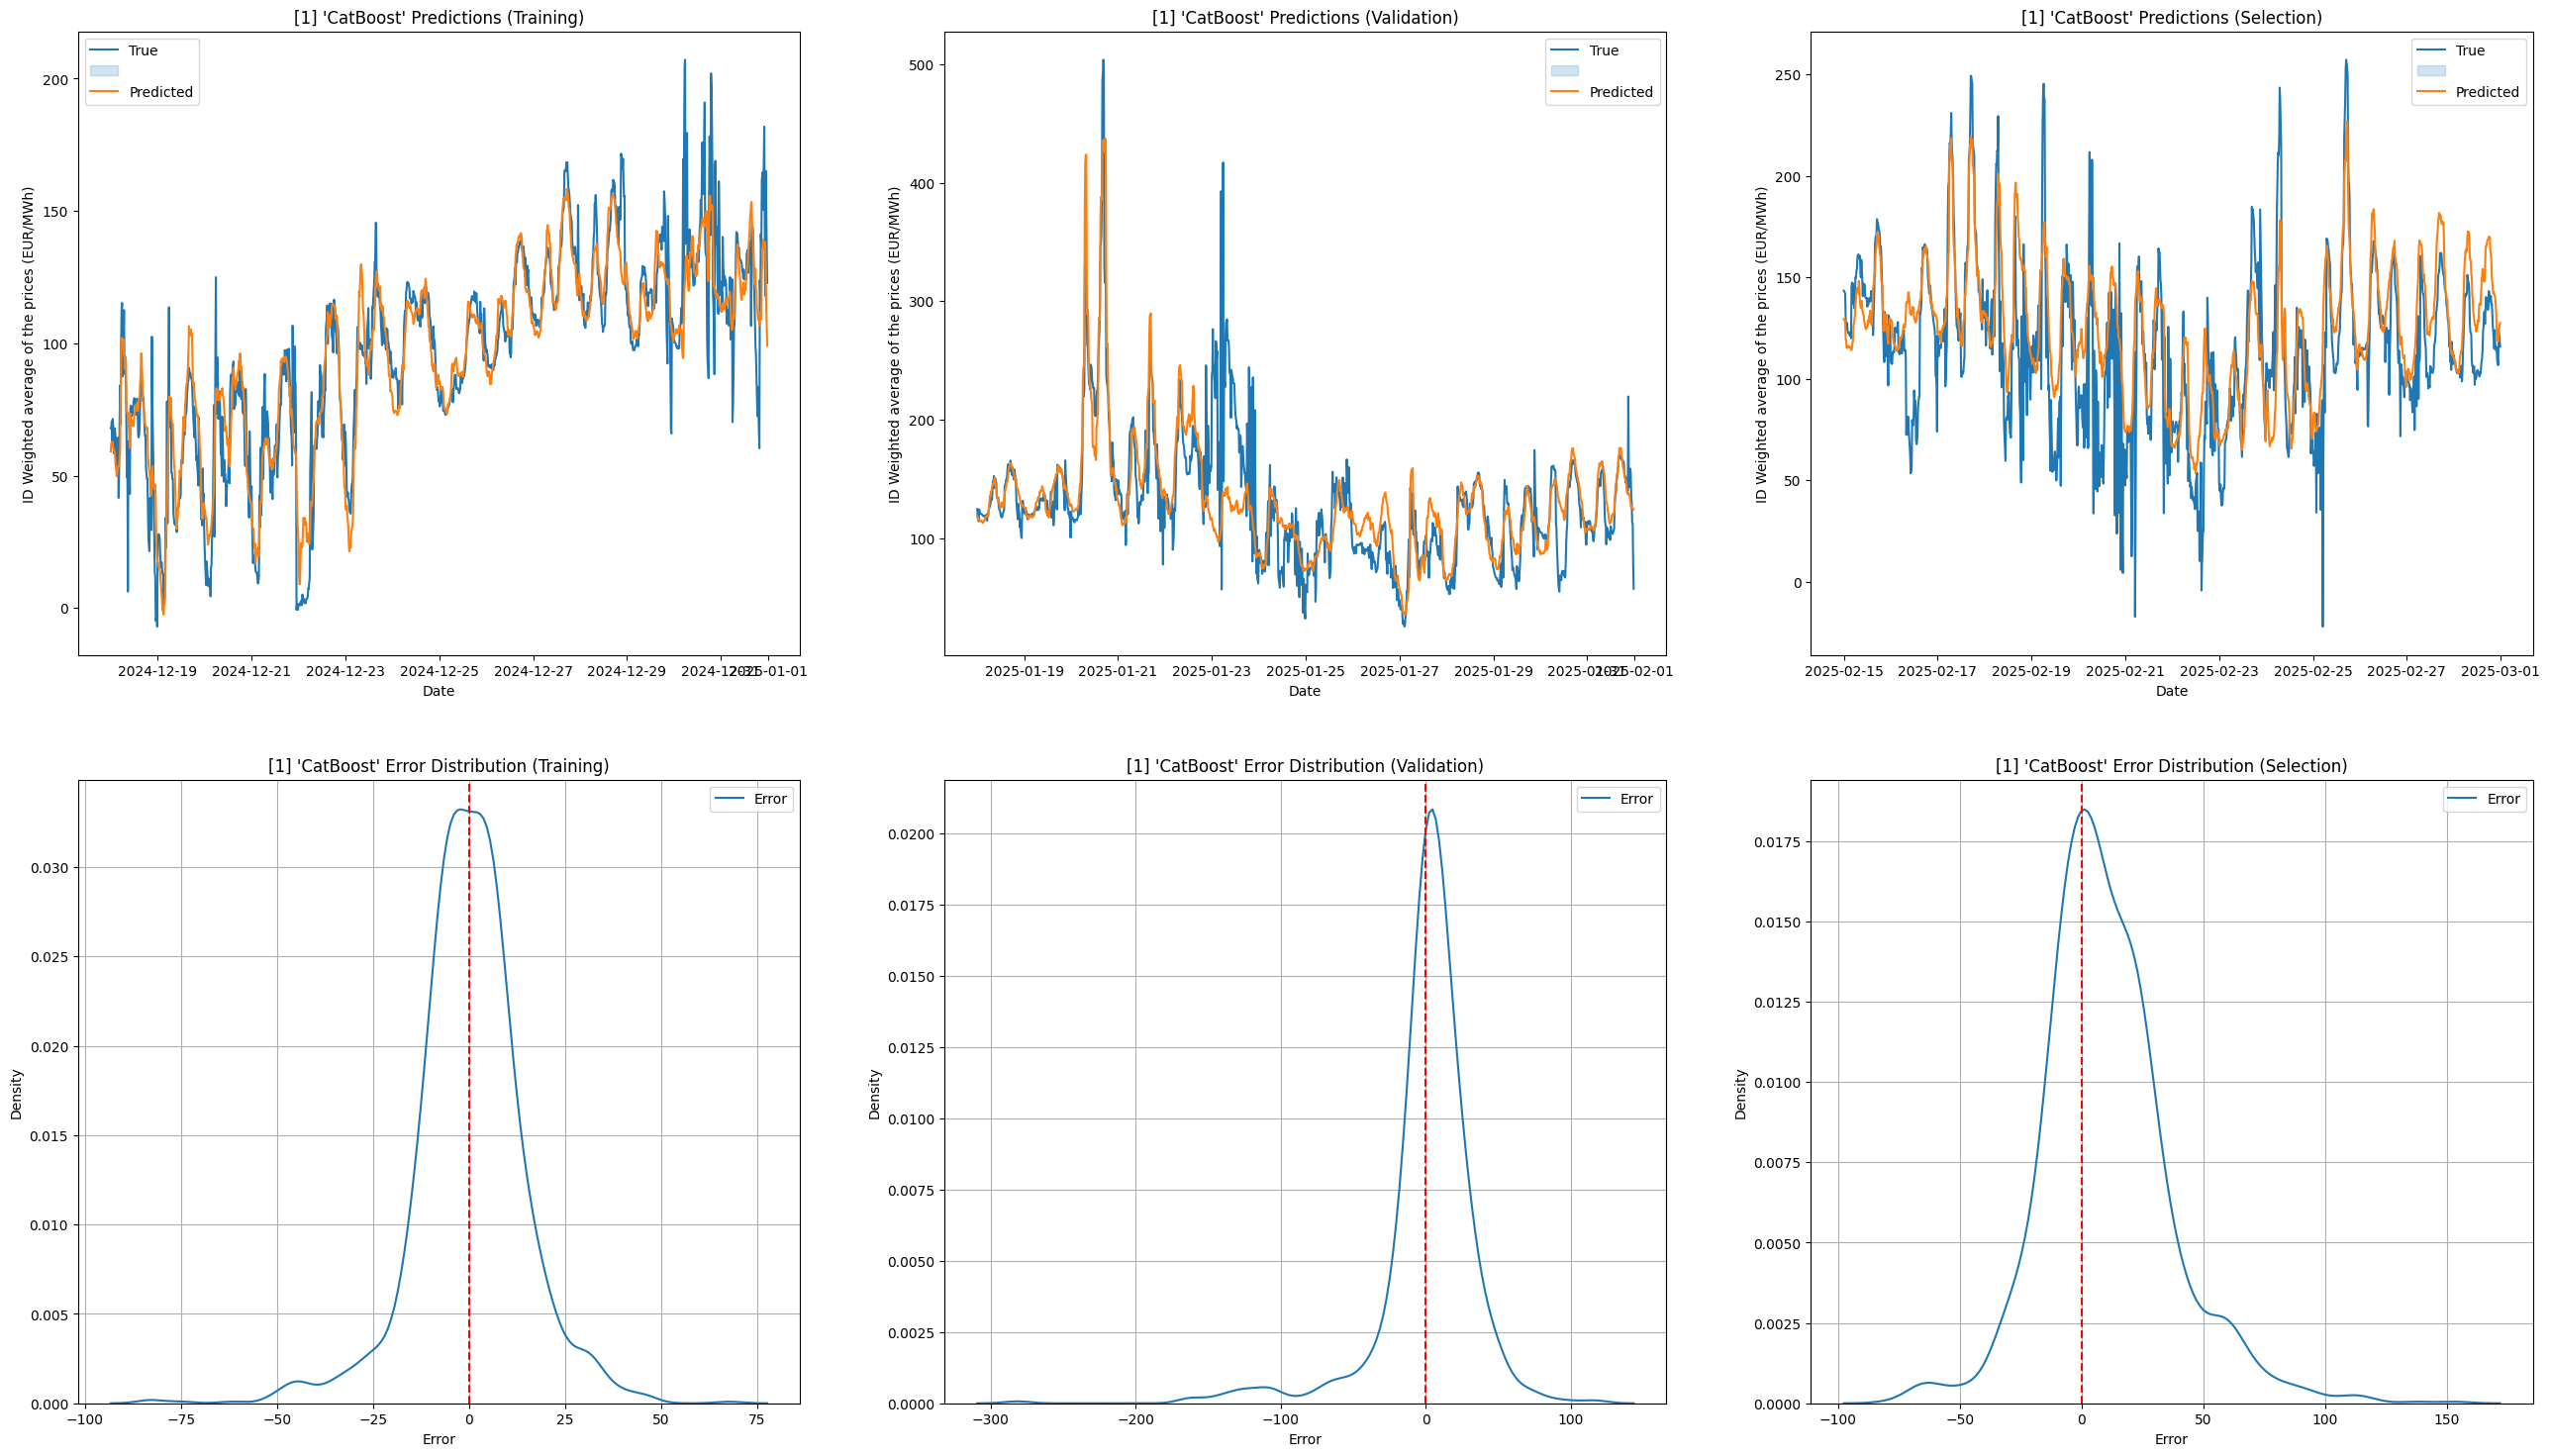

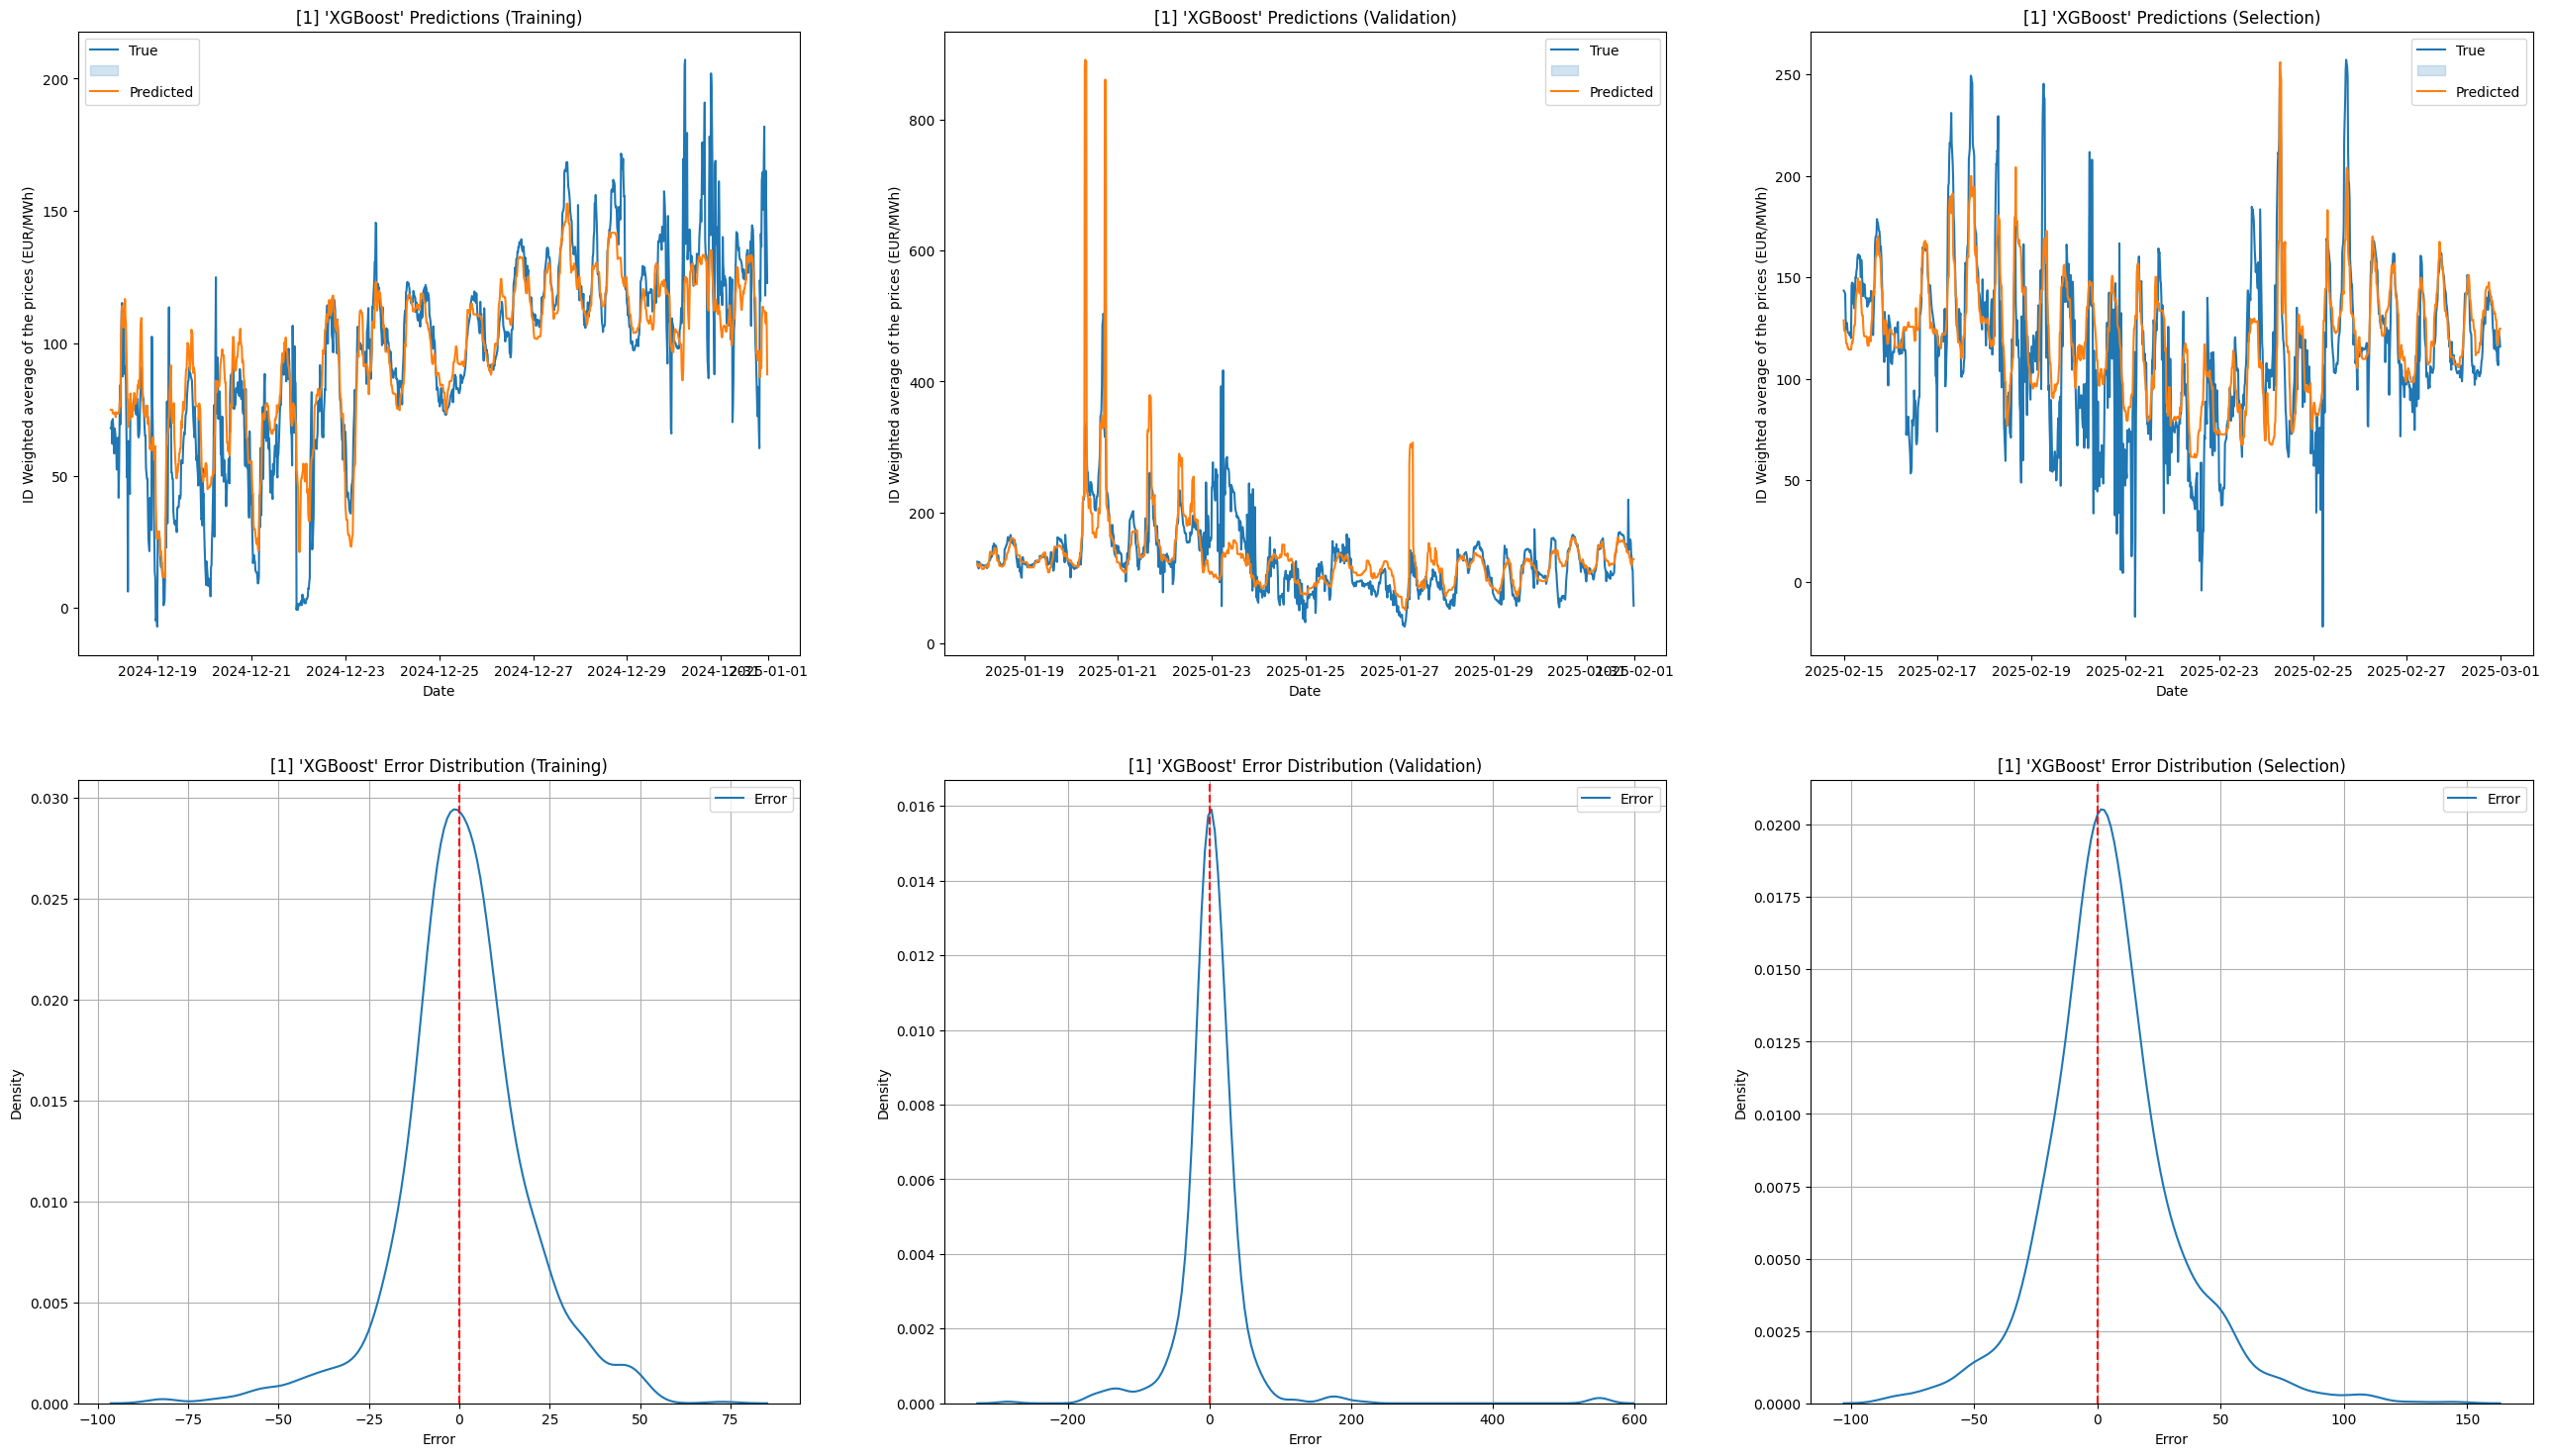

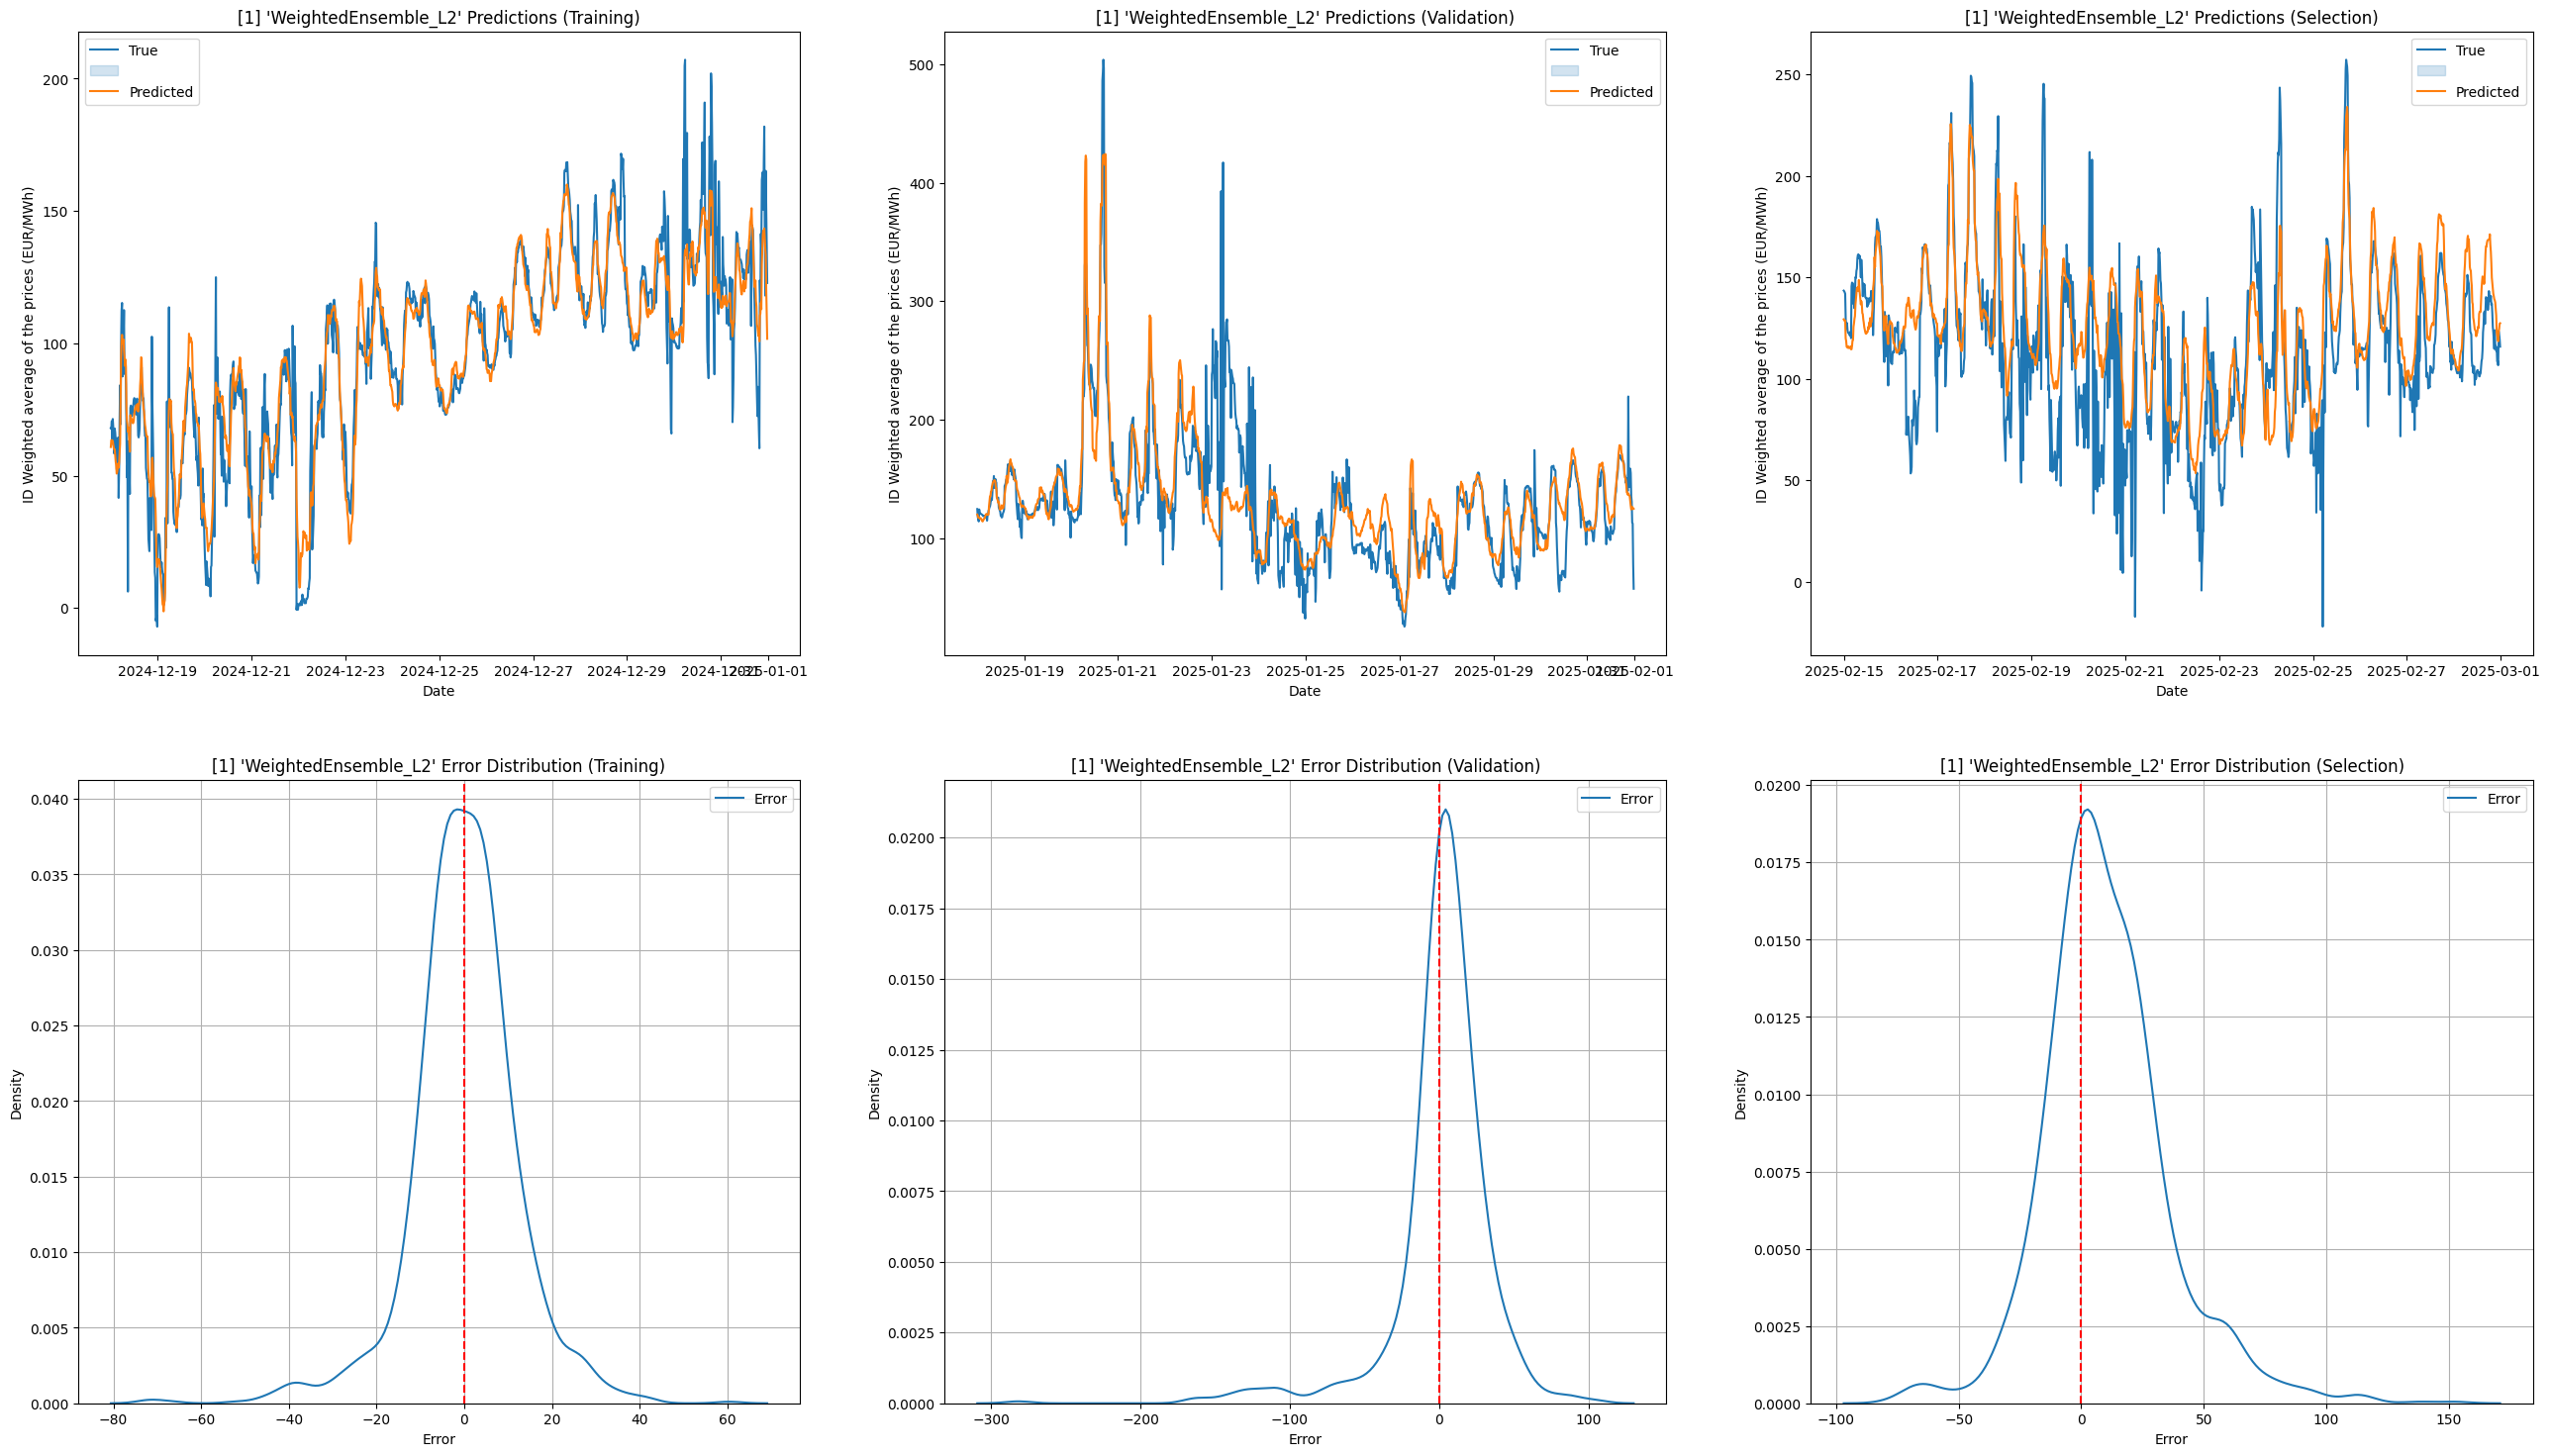

In [7]:
tab_mae_model = train_intra_day_tabular(tab_train, tab_val, "mae", cache="MAE")
display(evaluate_tabular_model(tab_mae_model, tab_train, tab_val, tab_select, eval_metrics))

In [ ]:
# from autogluon.timeseries import TimeSeriesDataFrame
#
# ts_retrain = TimeSeriesDataFrame.from_data_frame(pd.concat([ts_train, ts_val, ts_select]))
# ts_model = train_intra_day_time_series(ts_retrain, None, "MAE", cache="retrain", models={"Chronos": {}})
# display(ts_model.leaderboard(ts_test, extra_metrics=ts_metrics))